<a id="rozdzial-00"></a>
# ID3 × Mushroom
## Klasyczne drzewo decyzyjne ID3: własna implementacja, eksperymenty i interpretacja

| | |
|---|---|
| **Autor** | Kamil Piejko |
| **Temat** | Algorytm ID3 (*Iterative Dichotomiser 3*) na zbiorze Mushroom (UCI) |
| **Forma** | notebook Jupyter: jednocześnie projekt, sprawozdanie i prezentacja |
| **Dane** | UCI Machine Learning Repository, *Mushroom*, DOI [10.24432/C5959T](https://doi.org/10.24432/C5959T), licencja CC BY 4.0 |
| **Uruchomienie** | JupyterLab lokalnie lub Google Colab (notebook jest samowystarczalny) |

> ⚠️ **Zastrzeżenie bezpieczeństwa.** Mushroom jest zbiorem **edukacyjnym**: opisuje *hipotetyczne* okazy 23 gatunków
> z jednego przewodnika terenowego. Żaden wynik tego notebooka, także 100% trafności, nie uprawnia do decyzji
> o spożyciu dzikich grzybów.

### Spis treści

| Rozdział | Zawartość |
|---|---|
| [00. Okładka i środowisko](#rozdzial-00) | mapa wymagań, kod projektu, wczytanie danych |
| [01. Algorytm ID3](#rozdzial-01) | problem, historia, entropia i IG, pseudokod, przykład ręczny, ograniczenia, biblioteki |
| [02. Zbiór Mushroom](#rozdzial-02) | pochodzenie, kontrakt danych, słownik cech, rozkład klas |
| [03. EDA i czyszczenie](#rozdzial-03) | audyt jakości, braki, rozkłady, V Craméra, balans klas, zbędne cechy |
| [04. Dane modelowe](#rozdzial-04) | odpowiedź na „???” ze slajdu, podział 60/20/20, 3 strategie braków, duplikaty |
| [05. Własny ID3](#rozdzial-05) | pseudokod ↔ kod, pierwszy węzeł (`odor`), testy |
| [06. Strojenie](#rozdzial-06) | 36 modeli próbnych, krzywa głębokości, strategie braków, reguła wyboru, lasy losowe |
| [07. Model finalny](#rozdzial-07) | trening na train+val, charakterystyka, ważność cech, reguły |
| [08. Wizualizacja drzewa](#rozdzial-08) | diagram drzewa, pełne drzewo SVG/PNG, biblioteki grafiki |
| [09. Ocena i predykcja](#rozdzial-09) | jednorazowy test, macierz pomyłek, metryki, ścieżki predykcji |
| [10. Warsztat dla grupy](#rozdzial-10) | „Delivery Decision” — zadanie na 20 minut i do domu |
| [11. Podsumowanie i źródła](#rozdzial-11) | wnioski, ograniczenia, reprodukowalność, bibliografia |

### Mapa zgodności z wymaganiami prowadzącego

| Nr | Wymóg ze slajdu | Gdzie w notebooku | Artefakt |
|---|---|---|---|
| 1 | Wprowadzenie, przedstawienie algorytmu (pseudokod), zestawienie bibliotek zawierających algorytm | rozdz. 01 | wzory, pseudokod, tabela bibliotek |
| 2 | Dane, analiza danych, zbalansowanie, korelacje, braki w danych, błędne dane, czyszczenie danych, uzupełnianie danych, usunięcie zbędnych atrybutów | rozdz. 02–03 (+ 04.4) | raport jakości danych, V Craméra, tabela „przed/po” |
| 3 | Przygotowanie danych do budowy modelu, `???`, dane uczące, walidacyjne i testowe | rozdz. 04 | protokół podziału, `split_indices.csv` |
| 4 | Modele próbne, dostrojenie parametrów, ocena jakości, dobór parametrów; `(Nie ??? w przypadku lasów)` | rozdz. 06 | `experiment_results.csv`, wykresy, reguła wyboru |
| 5 | Budowa modelu finalnego | rozdz. 07 | `final_model/final_tree.json`, `final_config.json` |
| 6 | Graficzne przedstawienie drzewa, zestawienie bibliotek generujących grafikę | rozdz. 08 | `figures/final_tree.svg/.png`, `final_tree.dot` |
| 7 | Ocena modelu, macierz pomyłek, predykcje | rozdz. 09 | metryki, `test_predictions.csv` |
| 8 | Inne dane i zadanie dla grupy, kod w miejscu dostępnym tylko dla grupy | rozdz. 10 | `group_exercise/` (paczka uczestnika) |

**Wymóg formalny:** notebook `.ipynb` z zapisanymi wynikami oraz dane spakowane w ZIP
(`submission/ID3_Mushroom_Submission.zip`), przesłane mailem co najmniej dzień przed zajęciami.

### Konwencje

- Każda sekcja ma układ **cel/teoria → obliczenia → wykres lub tabela → interpretacja**.
- Kolory klas są stałe na wszystkich wykresach: <span style="color:#2a9d8f">■</span> **jadalny (`e`)**,
  <span style="color:#e76f51">■</span> **trujący (`p`)**. Paletę sprawdzono walidatorem kontrastu i odróżnialności
  przy daltonizmie.
- Liczby zapisujemy z kropką dziesiętną, tak jak w kodzie i tabelach. Entropię i IG podajemy w bitach.
- **Każda liczba w komentarzach pochodzi z obliczeń.** Generator notebooka wstawia ją z rzeczywistego uruchomienia,
  a ostatnia komórka (rozdz. 11) porównuje wszystkie cytowane wartości z wynikami bieżącego przebiegu.

## 0.1. Środowisko i kod projektu

Notebook jest **samowystarczalny**: działa w czystym Google Colab bez folderu `src/`. Kod modułów nie jest jednak
utrzymywany w dwóch miejscach. Skrypt `scripts/build_notebook.py` kopiuje pliki `src/*.py` do komórek poniżej
w kolejności zależności `data_io → preprocessing → id3 → evaluation → experiments → visualization`. Usuwa przy tym
importy wewnątrzpakietowe (`from .id3 import …`) i sprawdza, że żaden moduł nie nadpisuje nazw innego. Test
`tests/test_notebook.py` pilnuje, by komórki były identyczne z `src/`.

| Moduł | Odpowiedzialność | Rozdziały |
|---|---|---|
| `data_io` | ZIP z UCI (lokalnie lub pobranie w Colab), kontrakt danych, słownik kategorii | 00, 02 |
| `preprocessing` | audyt jakości, V Craméra, podział 60/20/20, „sejf” zbioru testowego, strategie braków | 03, 04 |
| `id3` | **własna implementacja ID3**: entropia, IG, budowa drzewa, predykcja, wyjaśnienia | 01, 05–09 |
| `evaluation` | metryki, macierz pomyłek z ustaloną kolejnością klas, błąd krytyczny `p → e` | 06, 09 |
| `experiments` | siatka 36 konfiguracji, krzywa głębokości, deterministyczna reguła wyboru | 06, 07 |
| `visualization` | wykresy oraz diagram drzewa (Graphviz lub matplotlib) | wszystkie |

Komórki modułów są zwinięte (JupyterLab/Colab): kliknij, aby rozwinąć. Najważniejsze fragmenty ID3 są omówione
w rozdziale 05.

In [1]:
# Biblioteki zewnętrzne (preinstalowane w Google Colab) i ich wersje
import importlib.metadata as metadata
import importlib.util
import io
import json
import os
import platform
import shutil
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, Math, SVG, display

IN_COLAB = "google.colab" in sys.modules
pd.set_option("display.max_colwidth", 110)
pd.set_option("display.width", 200)


def package_version(name: str) -> str:
    try:
        return metadata.version(name)
    except metadata.PackageNotFoundError:
        return "—"


ENVIRONMENT = {"Python": platform.python_version(), "uruchomienie": "Google Colab" if IN_COLAB else "lokalnie",
               **{name: package_version(name) for name in
                  ("numpy", "pandas", "scipy", "scikit-learn", "matplotlib", "seaborn")}}
display(pd.DataFrame([ENVIRONMENT]))

,Python,uruchomienie,numpy,pandas,scipy,scikit-learn,matplotlib,seaborn
0,3.12.13,lokalnie,2.5.4,3.0.6,1.18.1,1.9.1,3.11.2,0.13.2


In [2]:
# @title src/data_io.py — kod modułu wstrzyknięty automatycznie
# Źródło: src/data_io.py · generator: scripts/build_notebook.py · nie edytuj ręcznie.
"""Access to the UCI Mushroom data: local ZIP (offline) or download (Colab).

The original ``agaricus-lepiota.data`` is a header-less CSV with the class in
the first column followed by 22 nominal attributes. Values are read as strings
and the documented missing-value marker ``?`` is converted to NaN explicitly.
"""
from __future__ import annotations

import hashlib
import io
import re
import urllib.request
import zipfile
from pathlib import Path
from typing import Any

import numpy as np
import pandas as pd

UCI_DATASET_URL = "https://archive.ics.uci.edu/dataset/73/mushroom"
UCI_ZIP_URL = "https://archive.ics.uci.edu/static/public/73/mushroom.zip"
UCI_DOI = "https://doi.org/10.24432/C5959T"
DATA_LICENSE = "CC BY 4.0"
DATA_CITATION = ("Mushroom [Dataset]. (1981). UCI Machine Learning Repository. "
                 "https://doi.org/10.24432/C5959T")

DATA_MEMBER = "agaricus-lepiota.data"
NAMES_MEMBER = "agaricus-lepiota.names"
MISSING_CODE = "?"
MISSING_TOKEN = "__MISSING__"

FEATURE_NAMES = [
    'cap-shape', 'cap-surface', 'cap-color', 'bruises', 'odor',
    'gill-attachment', 'gill-spacing', 'gill-size', 'gill-color',
    'stalk-shape', 'stalk-root', 'stalk-surface-above-ring',
    'stalk-surface-below-ring', 'stalk-color-above-ring',
    'stalk-color-below-ring', 'veil-type', 'veil-color',
    'ring-number', 'ring-type', 'spore-print-color',
    'population', 'habitat',
]
TARGET_NAME = 'class'
COLUMN_NAMES = [TARGET_NAME, *FEATURE_NAMES]

EXPECTED_N_ROWS = 8124
EXPECTED_N_COLUMNS = 23
EXPECTED_CLASS_COUNTS = {"e": 4208, "p": 3916}
EXPECTED_MISSING = {"stalk-root": 2480}

CLASS_NAMES = {"e": "edible", "p": "poisonous"}
CLASS_NAMES_PL = {"e": "jadalny", "p": "trujący"}

# Category dictionary from section 7 of agaricus-lepiota.names (code -> name).
# tests/test_preprocessing.py checks it against the .names file in the ZIP.
CATEGORY_NAMES: dict[str, dict[str, str]] = {
    "cap-shape": {"b": "bell", "c": "conical", "x": "convex", "f": "flat", "k": "knobbed", "s": "sunken"},
    "cap-surface": {"f": "fibrous", "g": "grooves", "y": "scaly", "s": "smooth"},
    "cap-color": {"n": "brown", "b": "buff", "c": "cinnamon", "g": "gray", "r": "green", "p": "pink",
                  "u": "purple", "e": "red", "w": "white", "y": "yellow"},
    "bruises": {"t": "bruises", "f": "no"},
    "odor": {"a": "almond", "l": "anise", "c": "creosote", "y": "fishy", "f": "foul", "m": "musty",
             "n": "none", "p": "pungent", "s": "spicy"},
    "gill-attachment": {"a": "attached", "d": "descending", "f": "free", "n": "notched"},
    "gill-spacing": {"c": "close", "w": "crowded", "d": "distant"},
    "gill-size": {"b": "broad", "n": "narrow"},
    "gill-color": {"k": "black", "n": "brown", "b": "buff", "h": "chocolate", "g": "gray", "r": "green",
                   "o": "orange", "p": "pink", "u": "purple", "e": "red", "w": "white", "y": "yellow"},
    "stalk-shape": {"e": "enlarging", "t": "tapering"},
    "stalk-root": {"b": "bulbous", "c": "club", "u": "cup", "e": "equal", "z": "rhizomorphs", "r": "rooted"},
    "stalk-surface-above-ring": {"f": "fibrous", "y": "scaly", "k": "silky", "s": "smooth"},
    "stalk-surface-below-ring": {"f": "fibrous", "y": "scaly", "k": "silky", "s": "smooth"},
    "stalk-color-above-ring": {"n": "brown", "b": "buff", "c": "cinnamon", "g": "gray", "o": "orange",
                               "p": "pink", "e": "red", "w": "white", "y": "yellow"},
    "stalk-color-below-ring": {"n": "brown", "b": "buff", "c": "cinnamon", "g": "gray", "o": "orange",
                               "p": "pink", "e": "red", "w": "white", "y": "yellow"},
    "veil-type": {"p": "partial", "u": "universal"},
    "veil-color": {"n": "brown", "o": "orange", "w": "white", "y": "yellow"},
    "ring-number": {"n": "none", "o": "one", "t": "two"},
    "ring-type": {"c": "cobwebby", "e": "evanescent", "f": "flaring", "l": "large", "n": "none",
                  "p": "pendant", "s": "sheathing", "z": "zone"},
    "spore-print-color": {"k": "black", "n": "brown", "b": "buff", "h": "chocolate", "r": "green",
                          "o": "orange", "u": "purple", "w": "white", "y": "yellow"},
    "population": {"a": "abundant", "c": "clustered", "n": "numerous", "s": "scattered", "v": "several",
                   "y": "solitary"},
    "habitat": {"g": "grasses", "l": "leaves", "m": "meadows", "p": "paths", "u": "urban", "w": "waste",
                "d": "woods"},
}

FEATURE_NAMES_PL = {
    "cap-shape": "kształt kapelusza",
    "cap-surface": "powierzchnia kapelusza",
    "cap-color": "kolor kapelusza",
    "bruises": "siniaczenie po uszkodzeniu",
    "odor": "zapach",
    "gill-attachment": "przyrośnięcie blaszek",
    "gill-spacing": "rozstaw blaszek",
    "gill-size": "szerokość blaszek",
    "gill-color": "kolor blaszek",
    "stalk-shape": "kształt trzonu",
    "stalk-root": "nasada trzonu",
    "stalk-surface-above-ring": "powierzchnia trzonu nad pierścieniem",
    "stalk-surface-below-ring": "powierzchnia trzonu pod pierścieniem",
    "stalk-color-above-ring": "kolor trzonu nad pierścieniem",
    "stalk-color-below-ring": "kolor trzonu pod pierścieniem",
    "veil-type": "typ osłony (velum)",
    "veil-color": "kolor osłony",
    "ring-number": "liczba pierścieni",
    "ring-type": "typ pierścienia",
    "spore-print-color": "kolor wysypu zarodników",
    "population": "sposób występowania (populacja)",
    "habitat": "siedlisko",
}

MANUAL_DOWNLOAD_HINT = """\
Nie znaleziono pliku {path} i nie udało się pobrać archiwum z UCI ({reason}).
Jak wczytać dane ręcznie:
  1. Pobierz {url} w przeglądarce (UCI Machine Learning Repository, Mushroom).
  2. Lokalnie: zapisz plik jako {path} (bez rozpakowywania).
  3. Google Colab: uruchom w komórce
         from google.colab import files; files.upload()
     wybierz mushroom.zip, a następnie przenieś plik do {path}
     (np. !mkdir -p data && mv mushroom.zip data/).
"""


class DataContractError(ValueError):
    """Source data does not match the documented UCI Mushroom contract."""


# ---------------------------------------------------------------------------
# Locating / downloading the archive
# ---------------------------------------------------------------------------

def find_project_root(start: str | Path | None = None, marker: str = "data/mushroom.zip") -> Path:
    """Directory (``start`` or its parent) containing ``marker``; else ``start``."""
    start = Path.cwd() if start is None else Path(start)
    for candidate in (start, start.parent):
        if (candidate / marker).exists():
            return candidate.resolve()
    return start.resolve()


def ensure_mushroom_zip(zip_path: str | Path, *, url: str = UCI_ZIP_URL,
                        allow_download: bool = True, timeout: float = 60.0) -> Path:
    """Return the local archive, downloading the original UCI ZIP only if it is absent.

    An existing file is never re-downloaded, so the local/offline mode does not
    touch the network. A downloaded payload is checked to be a ZIP containing
    ``agaricus-lepiota.data`` before it is written to disk.
    """
    zip_path = Path(zip_path)
    if zip_path.exists():
        return zip_path
    if not allow_download:
        raise FileNotFoundError(MANUAL_DOWNLOAD_HINT.format(path=zip_path, url=url, reason="pobieranie wyłączone"))
    try:
        with urllib.request.urlopen(url, timeout=timeout) as response:
            payload = response.read()
        with zipfile.ZipFile(io.BytesIO(payload)) as archive:
            _find_member(archive, DATA_MEMBER)
    except Exception as exc:  # network errors, HTTP errors, corrupted payload
        raise FileNotFoundError(MANUAL_DOWNLOAD_HINT.format(path=zip_path, url=url, reason=repr(exc))) from exc
    zip_path.parent.mkdir(parents=True, exist_ok=True)
    partial = zip_path.with_name(zip_path.name + ".part")
    partial.write_bytes(payload)
    partial.replace(zip_path)
    return zip_path


def file_sha256(path: str | Path) -> str:
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


def _find_member(archive: zipfile.ZipFile, basename: str) -> str:
    matches = [name for name in archive.namelist() if name.rsplit("/", 1)[-1] == basename]
    if len(matches) != 1:
        raise DataContractError(
            f"expected exactly one '{basename}' in the archive, found {len(matches)}; "
            f"archive members: {archive.namelist()}"
        )
    return matches[0]


def zip_members(zip_path: str | Path) -> pd.DataFrame:
    with zipfile.ZipFile(zip_path) as archive:
        return pd.DataFrame([{"plik": info.filename, "rozmiar [B]": info.file_size}
                             for info in archive.infolist()])


# ---------------------------------------------------------------------------
# Reading and validating
# ---------------------------------------------------------------------------

def read_raw_mushroom(zip_path: str | Path) -> pd.DataFrame:
    """The data file exactly as published: all values as strings, ``?`` kept."""
    with zipfile.ZipFile(zip_path) as archive:
        member = _find_member(archive, DATA_MEMBER)
        with archive.open(member) as handle:
            raw = pd.read_csv(handle, header=None, dtype=str, keep_default_na=False, na_filter=False)
    if raw.shape[1] != EXPECTED_N_COLUMNS:
        raise DataContractError(f"expected {EXPECTED_N_COLUMNS} columns, found {raw.shape[1]} in {member}")
    raw.columns = COLUMN_NAMES
    return raw


def validate_raw_contract(raw: pd.DataFrame) -> pd.DataFrame:
    """Check the *unmodified* data against the UCI documentation.

    Returns the table of checks; raises :class:`DataContractError` if any fails.
    """
    question_marks = {col: int((raw[col] == MISSING_CODE).sum()) for col in raw.columns}
    other_marks = {col: n for col, n in question_marks.items() if n and col not in EXPECTED_MISSING}
    class_counts = {str(k): int(v) for k, v in raw[TARGET_NAME].value_counts().sort_index().items()}
    checks = [
        ("liczba wierszy", EXPECTED_N_ROWS, int(raw.shape[0])),
        ("liczba kolumn (klasa + 22 cechy)", EXPECTED_N_COLUMNS, int(raw.shape[1])),
        ("rozkład klas e / p", EXPECTED_CLASS_COUNTS, class_counts),
        ("znaki '?' w stalk-root", EXPECTED_MISSING["stalk-root"], question_marks["stalk-root"]),
        ("znaki '?' w pozostałych kolumnach", {}, other_marks),
    ]
    report = pd.DataFrame(checks, columns=["kontrola", "oczekiwane (UCI)", "zaobserwowane"])
    report["zgodne"] = [expected == observed for _, expected, observed in checks]
    if not report["zgodne"].all():
        failed = report.loc[~report["zgodne"], "kontrola"].tolist()
        raise DataContractError(f"data contract violated for: {failed}\n{report.to_string(index=False)}")
    return report


def load_mushroom(zip_path: str | Path, *, validate: bool = True) -> pd.DataFrame:
    """Validated dataset with ``?`` replaced by NaN (no other modification)."""
    raw = read_raw_mushroom(zip_path)
    if validate:
        validate_raw_contract(raw)
    data = raw.mask(raw.eq(MISSING_CODE))
    if validate:
        observed = {col: int(n) for col, n in data.isna().sum().items() if n}
        if observed != EXPECTED_MISSING:
            raise DataContractError(f"missing values after '?' -> NaN: {observed}, expected {EXPECTED_MISSING}")
    return data


def read_names_text(zip_path: str | Path) -> str:
    with zipfile.ZipFile(zip_path) as archive:
        return archive.read(_find_member(archive, NAMES_MEMBER)).decode("latin-1")


def parse_attribute_dictionary(names_text: str) -> dict[str, dict[str, str]]:
    """Parse section 7 ("Attribute Information") of agaricus-lepiota.names."""
    start = names_text.index("7. Attribute Information")
    end = names_text.index("8. Missing Attribute Values")
    section = names_text[start:end].split("\n", 1)[1]
    pattern = re.compile(r"^\s*\d+\.\s+([a-z?-]+):\s+(.*?)(?=^\s*\d+\.\s+[a-z?-]+:|\Z)", re.M | re.S)
    dictionary = {}
    for name, body in pattern.findall(section):
        pairs = [item.strip() for item in re.sub(r"\s+", "", body).split(",") if item.strip()]
        dictionary[name.rstrip("?")] = {code: label for label, code in (pair.split("=") for pair in pairs)}
    return dictionary


def compare_with_names_file(zip_path: str | Path) -> pd.DataFrame:
    """Per-feature comparison of ``CATEGORY_NAMES`` with the .names file."""
    parsed = parse_attribute_dictionary(read_names_text(zip_path))
    rows = []
    for feature in FEATURE_NAMES:
        documented = {k: v for k, v in parsed.get(feature, {}).items() if k != MISSING_CODE}
        rows.append({"cecha": feature, "kategorie w .names": len(documented),
                     "kategorie w kodzie": len(CATEGORY_NAMES[feature]),
                     "zgodne": documented == CATEGORY_NAMES[feature]})
    return pd.DataFrame(rows)


# ---------------------------------------------------------------------------
# Human-readable labels
# ---------------------------------------------------------------------------

def expand_value(feature: str, value: Any) -> str:
    """``'f'`` -> ``'foul (f)'``; missing markers -> ``'brak danych (?)'``."""
    if value is None or value == MISSING_TOKEN or value == MISSING_CODE or (
            not isinstance(value, str) and pd.isna(value)):
        return "brak danych (?)"
    name = CATEGORY_NAMES.get(feature, {}).get(value)
    return f"{name} ({value})" if name else str(value)


def format_condition(feature: str, value: Any) -> str:
    """``odor = foul (f)``."""
    return f"{feature} = {expand_value(feature, value)}"


def describe_class(label: Any) -> str:
    return f"{CLASS_NAMES_PL.get(label, label)} ({label})"


def dictionary_frame() -> pd.DataFrame:
    """Feature dictionary for presentation: name, Polish meaning and categories."""
    return pd.DataFrame([
        {"cecha": feature, "znaczenie": FEATURE_NAMES_PL[feature],
         "liczba kategorii (UCI)": len(CATEGORY_NAMES[feature]),
         "kategorie (kod = nazwa)": ", ".join(f"{code}={name}" for code, name in CATEGORY_NAMES[feature].items())}
        for feature in FEATURE_NAMES
    ])


def expand_frame(df: pd.DataFrame) -> pd.DataFrame:
    """Copy of ``df`` with codes replaced by ``name (code)`` labels."""
    out = df.copy().astype(object)
    for column in out.columns:
        if column in CATEGORY_NAMES:
            out[column] = [expand_value(column, v) for v in out[column]]
        elif column == TARGET_NAME:
            out[column] = [describe_class(v) for v in out[column]]
    return out


def missing_mask(df: pd.DataFrame) -> pd.DataFrame:
    return df.isna()


def as_object_frame(df: pd.DataFrame) -> pd.DataFrame:
    """Plain object-dtype copy (identical behaviour across pandas 2.x and 3.x)."""
    return df.astype(object).where(df.notna(), np.nan)


In [3]:
# @title src/preprocessing.py — kod modułu wstrzyknięty automatycznie
# Źródło: src/preprocessing.py · generator: scripts/build_notebook.py · nie edytuj ręcznie.
"""Data preparation for ID3: quality audit, associations, split protocol, missing values.

Every transformation that learns something from data (constant columns,
imputation values, known categories) is fitted on the training rows only and
then applied unchanged to validation/test (fit on train, transform elsewhere).
"""
from __future__ import annotations

import math
from dataclasses import dataclass
from typing import Any

import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency
from sklearn.metrics import mutual_info_score
from sklearn.model_selection import train_test_split


MISSING_STRATEGIES = ("missing_category", "most_frequent", "drop_stalk_root")
STALK_ROOT = "stalk-root"
RANDOM_STATE = 42
SPLIT_SIZES = {"train": 0.6, "validation": 0.2, "test": 0.2}
PART_NAMES_PL = {"train": "uczący", "validation": "walidacyjny", "test": "testowy"}


def split_features_target(df: pd.DataFrame, target: str = TARGET_NAME) -> tuple[pd.DataFrame, pd.Series]:
    """Feature matrix X (all columns but ``target``) and target vector y."""
    return df.drop(columns=[target]), df[target].rename(target)


# ---------------------------------------------------------------------------
# Data quality audit
# ---------------------------------------------------------------------------

def find_constant_features(X: pd.DataFrame) -> list[str]:
    """Columns with at most one distinct observed (non-missing) value."""
    return [column for column in X.columns if X[column].nunique(dropna=True) <= 1]


def out_of_domain_values(X: pd.DataFrame) -> dict[str, list[str]]:
    """Observed values that the UCI dictionary does not declare (NaN excluded)."""
    found = {}
    for column in X.columns:
        observed = set(X[column].dropna().unique().tolist())
        extra = sorted(observed - set(CATEGORY_NAMES.get(column, {})))
        if extra:
            found[column] = extra
    return found


def unobserved_categories(X: pd.DataFrame) -> dict[str, list[str]]:
    """Categories declared in the UCI dictionary that never occur in ``X``."""
    found = {}
    for column in X.columns:
        observed = set(X[column].dropna().unique().tolist())
        absent = [code for code in CATEGORY_NAMES.get(column, {}) if code not in observed]
        if absent:
            found[column] = absent
    return found


def _fill_for_comparison(X: pd.DataFrame) -> pd.DataFrame:
    """Object copy with NaN shown as '?' so that rows can be compared for equality."""
    return X.astype(object).where(X.notna(), MISSING_CODE)


def duplicate_stats(X: pd.DataFrame, y: pd.Series) -> dict[str, int]:
    """Duplicated feature vectors, full duplicates (features + class) and label conflicts."""
    frame = _fill_for_comparison(X)
    labelled = frame.assign(__label__=y.to_numpy(dtype=object))
    labels_per_vector = labelled.groupby(list(frame.columns), sort=False)["__label__"].nunique()
    return {
        "duplicate_feature_vectors": int(frame.duplicated().sum()),
        "duplicate_rows": int(labelled.duplicated().sum()),
        "conflicting_vectors": int((labels_per_vector > 1).sum()),
    }


def overlap_stats(X_ref: pd.DataFrame, y_ref: pd.Series, X_new: pd.DataFrame, y_new: pd.Series) -> dict[str, int]:
    """Rows of ``X_new`` whose exact feature vector also occurs in ``X_ref`` (and label conflicts)."""
    ref_labels: dict[tuple, set] = {}
    for key, label in zip(_fill_for_comparison(X_ref).itertuples(index=False, name=None), y_ref.to_numpy()):
        ref_labels.setdefault(key, set()).add(label)
    overlap = conflicting = 0
    for key, label in zip(_fill_for_comparison(X_new).itertuples(index=False, name=None), y_new.to_numpy()):
        if key in ref_labels:
            overlap += 1
            conflicting += int(ref_labels[key] != {label})
    return {"overlap": overlap, "conflicting": conflicting}


def data_quality_audit(df: pd.DataFrame, target: str = TARGET_NAME) -> pd.DataFrame:
    """Table of quality checks; negative findings ("nothing found") are reported as results too."""
    X, y = split_features_target(df, target)
    values = pd.Series(X.to_numpy(dtype=object).ravel()).dropna().astype(str)
    numeric_columns = [c for c in X.columns if pd.api.types.is_numeric_dtype(X[c])]
    bad_format = int((~values.str.fullmatch(r"[a-z]")).sum())
    blank = int((values.str.strip() != values).sum() + (values == "").sum())
    domain = out_of_domain_values(X)
    unknown_labels = sorted(set(y.dropna().unique().tolist()) - {"e", "p"})
    dups = duplicate_stats(X, y)
    missing = X.isna().sum()
    missing = missing[missing > 0]
    constant = find_constant_features(X)
    unobserved = unobserved_categories(X)

    def status(ok: bool, action: str = "do obsłużenia") -> str:
        return "OK - brak problemu" if ok else action

    rows = [
        ("typy kolumn", f"{X.shape[1] - len(numeric_columns)}/{X.shape[1]} kolumn tekstowych (nominalnych)",
         status(not numeric_columns)),
        ("wartości spoza słownika UCI", f"{sum(len(v) for v in domain.values())} {domain or ''}".strip(),
         status(not domain)),
        ("format kodu (1 mała litera)", f"{bad_format} niezgodnych wartości", status(bad_format == 0)),
        ("puste napisy / białe znaki", f"{blank} wartości", status(blank == 0)),
        ("etykiety klas spoza {e, p}", f"{len(unknown_labels)} {unknown_labels or ''}".strip(),
         status(not unknown_labels)),
        ("pełne duplikaty wierszy (cechy + klasa)", f"{dups['duplicate_rows']}", status(dups["duplicate_rows"] == 0)),
        ("duplikaty wektorów cech", f"{dups['duplicate_feature_vectors']}",
         status(dups["duplicate_feature_vectors"] == 0)),
        ("sprzeczne etykiety (te same cechy, inna klasa)", f"{dups['conflicting_vectors']}",
         status(dups["conflicting_vectors"] == 0)),
        ("braki danych ('?' -> NaN)",
         ", ".join(f"{c}: {n} ({n / len(X):.2%})" for c, n in missing.items()) or "0",
         status(missing.empty, "do obsłużenia (3 strategie, rozdz. 04)")),
        ("cechy stałe (1 wartość)", ", ".join(constant) or "brak",
         status(not constant, "do usunięcia (zerowy IG)")),
        ("kategorie ze słownika niewystępujące w danych",
         "; ".join(f"{c}: {', '.join(v)}" for c, v in unobserved.items()) or "brak",
         "informacyjnie (nie jest błędem)"),
    ]
    return pd.DataFrame(rows, columns=["kontrola", "wynik", "status"])


def feature_profile(X: pd.DataFrame) -> pd.DataFrame:
    """Cardinality, missing values and dominant category of every feature."""
    rows = []
    for column in X.columns:
        counts = X[column].value_counts(dropna=True)
        rows.append({
            "cecha": column,
            "kategorie obserwowane": int(counts.size),
            "kategorie w słowniku": len(CATEGORY_NAMES.get(column, {})),
            "braki": int(X[column].isna().sum()),
            "dominanta": counts.index[0] if counts.size else None,
            "udział dominanty": float(counts.iloc[0] / len(X)) if counts.size else float("nan"),
        })
    return pd.DataFrame(rows)


# ---------------------------------------------------------------------------
# Association measures for nominal variables
# ---------------------------------------------------------------------------

def _as_object_series(values: Any) -> pd.Series:
    arr = values.to_numpy(dtype=object) if isinstance(values, pd.Series) else np.asarray(values, dtype=object)
    return pd.Series(arr)


def cramers_v(x: Any, y: Any) -> float:
    """Cramér's V = sqrt(chi2 / (n * min(r - 1, c - 1))) of two nominal variables.

    A constant variable (r == 1 or c == 1) gives min(r - 1, c - 1) == 0; V is then
    defined as 0.0 (no association can be measured) instead of dividing by zero.
    Missing values are rejected - encode them as a category first.
    """
    xs, ys = _as_object_series(x), _as_object_series(y)
    if len(xs) != len(ys):
        raise ValueError("x and y must have the same length")
    if xs.isna().any() or ys.isna().any():
        raise ValueError("cramers_v does not accept missing values; encode them as a category first")
    observed = pd.crosstab(xs, ys).to_numpy()
    k = min(observed.shape[0] - 1, observed.shape[1] - 1)
    if k == 0:
        return 0.0
    chi2 = chi2_contingency(observed, correction=False)[0]
    return float(min(1.0, math.sqrt(chi2 / (observed.sum() * k))))


def cramers_v_matrix(df: pd.DataFrame, columns: list[str] | None = None,
                     missing_as_category: bool = True) -> pd.DataFrame:
    """Symmetric matrix of Cramér's V (diagonal = 1 for non-constant variables)."""
    columns = list(df.columns) if columns is None else list(columns)
    data = df[columns].astype(object)
    if missing_as_category:
        data = data.where(data.notna(), MISSING_TOKEN)
    matrix = pd.DataFrame(np.eye(len(columns)), index=columns, columns=columns)
    for i, a in enumerate(columns):
        if data[a].nunique() <= 1:
            matrix.loc[a, a] = 0.0
        for b in columns[i + 1:]:
            matrix.loc[a, b] = matrix.loc[b, a] = cramers_v(data[a], data[b])
    return matrix


def association_with_target(X: pd.DataFrame, y: pd.Series, missing_as_category: bool = True) -> pd.DataFrame:
    """Cramér's V, mutual information I(A; Y) [bits] and Theil's U(Y|A) of every feature.

    Mutual information is computed with scikit-learn (an implementation
    independent of src/id3.py); I(A; Y) is numerically the ID3 information gain.
    """
    data = X.astype(object)
    if missing_as_category:
        data = data.where(data.notna(), MISSING_TOKEN)
    labels = y.to_numpy(dtype=object)
    h_y = mutual_info_score(labels, labels) / math.log(2)
    rows = []
    for column in data.columns:
        values = data[column].to_numpy(dtype=object)
        mi = mutual_info_score(labels, values) / math.log(2)
        rows.append({"cecha": column, "kategorie": int(pd.Series(values).nunique()),
                     "V Craméra": cramers_v(values, labels), "I(A;Y) [bit]": max(mi, 0.0),
                     "U Theila": max(mi, 0.0) / h_y if h_y > 0 else 0.0})
    return pd.DataFrame(rows).sort_values(["I(A;Y) [bit]", "cecha"], ascending=[False, True],
                                          kind="mergesort").reset_index(drop=True)


# ---------------------------------------------------------------------------
# Split protocol
# ---------------------------------------------------------------------------

@dataclass(frozen=True)
class DataSplit:
    """Disjoint index labels of the train / validation / test parts."""

    train: np.ndarray
    validation: np.ndarray
    test: np.ndarray
    random_state: int = RANDOM_STATE

    def parts(self) -> dict[str, np.ndarray]:
        return {"train": self.train, "validation": self.validation, "test": self.test}

    def train_validation(self) -> np.ndarray:
        return np.sort(np.concatenate([self.train, self.validation]))

    def assert_disjoint(self, n_total: int | None = None) -> None:
        sets = {name: set(idx.tolist()) for name, idx in self.parts().items()}
        names = list(sets)
        for i, a in enumerate(names):
            if len(sets[a]) != len(self.parts()[a]):
                raise AssertionError(f"part '{a}' contains repeated indices")
            for b in names[i + 1:]:
                common = sets[a] & sets[b]
                if common:
                    raise AssertionError(f"parts '{a}' and '{b}' share {len(common)} indices")
        if n_total is not None and sum(len(s) for s in sets.values()) != n_total:
            raise AssertionError("the parts do not cover the whole dataset")

    def summary(self, y: pd.Series) -> pd.DataFrame:
        """Sizes and class proportions of every part (documents the stratification)."""
        total = sum(len(idx) for idx in self.parts().values())
        rows = []
        for name, idx in self.parts().items():
            counts = y.loc[idx].value_counts()
            row = {"zbiór": PART_NAMES_PL[name], "n": len(idx), "udział": len(idx) / total}
            for label in sorted(y.unique()):
                row[f"n {label}"] = int(counts.get(label, 0))
                row[f"% {label}"] = counts.get(label, 0) / len(idx)
            rows.append(row)
        return pd.DataFrame(rows)

    def assignment(self) -> pd.DataFrame:
        """Row index -> part, for saving the split for audit."""
        frames = [pd.DataFrame({"row_index": idx, "part": name}) for name, idx in self.parts().items()]
        return pd.concat(frames).sort_values("row_index").reset_index(drop=True)


def make_stratified_split(y: pd.Series, *, train_size: float = 0.6, validation_size: float = 0.2,
                          test_size: float = 0.2, random_state: int = RANDOM_STATE) -> DataSplit:
    """Two stratified, shuffled splits: (train+val | test), then (train | val)."""
    if not math.isclose(train_size + validation_size + test_size, 1.0):
        raise ValueError("train_size + validation_size + test_size must equal 1")
    index = y.index.to_numpy()
    rest, test = train_test_split(index, test_size=test_size, shuffle=True,
                                  stratify=y.to_numpy(dtype=object), random_state=random_state)
    train, validation = train_test_split(rest, test_size=validation_size / (train_size + validation_size),
                                         shuffle=True, stratify=y.loc[rest].to_numpy(dtype=object),
                                         random_state=random_state)
    split = DataSplit(np.sort(train), np.sort(validation), np.sort(test), random_state)
    split.assert_disjoint(len(index))
    return split


class HoldoutVault:
    """Keeps the test split sealed until one explicit, final evaluation.

    ``audit_view`` gives logged, read-only access for data-hygiene audits that
    involve no model (e.g. duplicates across splits); ``unlock`` may be called
    exactly once - after the final model has been fixed.
    """

    def __init__(self, X: pd.DataFrame, y: pd.Series, name: str = "test") -> None:
        self._X, self._y, self.name = X.copy(), y.copy(), name
        self._unlocked = False
        self.access_log: list[dict[str, str]] = []

    def __len__(self) -> int:
        return len(self._y)

    def __repr__(self) -> str:
        state = "otwarty" if self._unlocked else "zapieczętowany"
        return f"HoldoutVault({self.name!r}, n={len(self)}, {state}, dostępy={len(self.access_log)})"

    @property
    def index(self) -> pd.Index:
        return self._X.index.copy()

    @property
    def is_unlocked(self) -> bool:
        return self._unlocked

    def audit_view(self, purpose: str) -> tuple[pd.DataFrame, pd.Series]:
        if self._unlocked:
            raise RuntimeError("the test split has already been used for the final evaluation")
        self.access_log.append({"typ dostępu": "audyt danych (bez modelu)", "cel": purpose})
        return self._X.copy(), self._y.copy()

    def unlock(self, purpose: str) -> tuple[pd.DataFrame, pd.Series]:
        if self._unlocked:
            raise RuntimeError("the test split can be unlocked only once - no further tuning allowed")
        self._unlocked = True
        self.access_log.append({"typ dostępu": "jednorazowa ocena modelu", "cel": purpose})
        return self._X.copy(), self._y.copy()

    def log_frame(self) -> pd.DataFrame:
        return pd.DataFrame(self.access_log, columns=["typ dostępu", "cel"])


# ---------------------------------------------------------------------------
# Missing-value strategies (fit on train, transform elsewhere)
# ---------------------------------------------------------------------------

def _deterministic_mode(series: pd.Series) -> str:
    """Most frequent observed value; ties broken alphabetically."""
    counts = series.value_counts(dropna=True)
    if counts.empty:
        raise ValueError(f"column {series.name!r} has no observed values to compute a mode")
    return min(counts.index[counts == counts.max()].tolist())


class CategoricalPreprocessor:
    """Fit-on-train preparation of nominal data for ID3.

    ``fit`` learns from the training rows only: constant features to drop, the
    missing-value treatment of ``strategy`` and the known categories of every
    kept feature. ``transform`` applies exactly these parameters to any split
    and guarantees an output without missing values.

    Strategies
    ----------
    ``missing_category``  NaN -> explicit category ``'__MISSING__'``;
    ``most_frequent``     NaN -> mode of the column in the fitting data;
    ``drop_stalk_root``   the ``stalk-root`` column is removed (no imputation).
    """

    def __init__(self, strategy: str = "missing_category", *, drop_constant: bool = True,
                 missing_token: str = MISSING_TOKEN) -> None:
        self.strategy = strategy
        self.drop_constant = drop_constant
        self.missing_token = missing_token

    def __repr__(self) -> str:
        return f"CategoricalPreprocessor(strategy={self.strategy!r}, drop_constant={self.drop_constant})"

    def fit(self, X: pd.DataFrame) -> CategoricalPreprocessor:
        if self.strategy not in MISSING_STRATEGIES:
            raise ValueError(f"unknown strategy {self.strategy!r}; choose one of {MISSING_STRATEGIES}")
        if not isinstance(X, pd.DataFrame):
            raise TypeError("X must be a pandas.DataFrame")
        self.feature_names_in_ = list(X.columns)
        self.constant_features_ = find_constant_features(X) if self.drop_constant else []
        dropped = list(self.constant_features_)
        if self.strategy == "drop_stalk_root" and STALK_ROOT in X.columns and STALK_ROOT not in dropped:
            dropped.append(STALK_ROOT)
        self.dropped_features_ = dropped
        self.feature_names_out_ = [c for c in X.columns if c not in dropped]
        if self.strategy == "most_frequent":
            self.fill_values_ = {c: _deterministic_mode(X[c]) for c in self.feature_names_out_}
        elif self.strategy == "missing_category":
            self.fill_values_ = {c: self.missing_token for c in self.feature_names_out_}
        else:
            self.fill_values_ = {}
        missing = X[self.feature_names_out_].isna().sum()
        self.missing_counts_fit_ = {c: int(n) for c, n in missing.items() if n}
        transformed = self._apply(X)
        self.categories_ = {c: sorted(transformed[c].unique().tolist()) for c in self.feature_names_out_}
        self.n_samples_fit_ = len(X)
        self.fit_index_ = X.index.to_numpy().copy()
        return self

    def _apply(self, X: pd.DataFrame) -> pd.DataFrame:
        out = X[self.feature_names_out_].copy()
        if self.fill_values_:
            out = out.fillna(self.fill_values_)
        leftover = out.isna().sum()
        leftover = leftover[leftover > 0]
        if not leftover.empty:
            raise ValueError(f"strategy {self.strategy!r} leaves missing values in {leftover.to_dict()}")
        return out

    def transform(self, X: pd.DataFrame) -> pd.DataFrame:
        if not hasattr(self, "feature_names_out_"):
            raise RuntimeError("CategoricalPreprocessor is not fitted; call fit(X_train) first")
        absent = [c for c in self.feature_names_out_ if c not in X.columns]
        if absent:
            raise ValueError(f"X lacks columns seen during fit: {absent}")
        return self._apply(X)

    def fit_transform(self, X: pd.DataFrame) -> pd.DataFrame:
        return self.fit(X).transform(X)

    def unseen_categories(self, X: pd.DataFrame) -> dict[str, list[str]]:
        """Categories of the transformed ``X`` that were never seen during fit."""
        transformed = self.transform(X)
        found = {}
        for column in self.feature_names_out_:
            extra = sorted(set(transformed[column].unique().tolist()) - set(self.categories_[column]))
            if extra:
                found[column] = extra
        return found

    def summary(self) -> dict[str, Any]:
        return {
            "strategy": self.strategy,
            "constant_features_dropped": list(self.constant_features_),
            "dropped_features": list(self.dropped_features_),
            "n_features_out": len(self.feature_names_out_),
            "missing_in_fit_data": dict(self.missing_counts_fit_),
            "imputation": {c: self.fill_values_[c] for c in self.missing_counts_fit_ if c in self.fill_values_},
            "n_samples_fit": self.n_samples_fit_,
        }


def duplicate_audit(parts: dict[str, tuple[pd.DataFrame, pd.Series]],
                    strategies: tuple[str, ...] = MISSING_STRATEGIES) -> pd.DataFrame:
    """Duplicates before/after every missing-value strategy and exact-vector overlap across splits.

    ``parts`` maps ``train``/``validation``/``test`` to ``(X, y)``. Each
    strategy is fitted on ``train`` only, as in the modelling pipeline.
    """
    variants: dict[str, dict[str, tuple[pd.DataFrame, pd.Series]]] = {"surowe (22 cechy, '?' jako symbol)": parts}
    for strategy in strategies:
        pre = CategoricalPreprocessor(strategy).fit(parts["train"][0])
        variants[strategy] = {name: (pre.transform(X), y) for name, (X, y) in parts.items()}
    rows = []
    for name, data in variants.items():
        X_all = pd.concat([X for X, _ in data.values()])
        y_all = pd.concat([y for _, y in data.values()])
        stats = duplicate_stats(X_all, y_all)
        val_train = overlap_stats(*data["train"], *data["validation"])
        X_trval = pd.concat([data["train"][0], data["validation"][0]])
        y_trval = pd.concat([data["train"][1], data["validation"][1]])
        test_trval = overlap_stats(X_trval, y_trval, *data["test"])
        rows.append({
            "wariant": name,
            "liczba cech": X_all.shape[1],
            "duplikaty wektorów cech": stats["duplicate_feature_vectors"],
            "pełne duplikaty (cechy+klasa)": stats["duplicate_rows"],
            "wektory ze sprzeczną klasą": stats["conflicting_vectors"],
            "walidacja ∩ trening": val_train["overlap"],
            "test ∩ (trening+walidacja)": test_trval["overlap"],
            "w tym sprzeczne etykiety": test_trval["conflicting"] + val_train["conflicting"],
        })
    return pd.DataFrame(rows)


In [4]:
# @title src/id3.py — kod modułu wstrzyknięty automatycznie
# Źródło: src/id3.py · generator: scripts/build_notebook.py · nie edytuj ręcznie.
"""Classic ID3 decision tree (Quinlan, 1986) for nominal attributes.

The tree is grown with the original recursive procedure: greedy choice of the
attribute with maximal information gain, a multiway split on every category
observed in the node, and no re-use of an attribute along the same path.

``max_depth``, ``min_samples_split`` and ``min_information_gain`` are didactic
pre-pruning extensions of that growth procedure - they are *not* parameters of
Quinlan's original algorithm. With their defaults the classifier grows the
classic, unrestricted ID3 tree (zero-gain splits are never created).
"""
from __future__ import annotations

import hashlib
import json
from collections.abc import Callable, Iterator, Mapping, Sequence
from dataclasses import dataclass, field
from pathlib import Path
from typing import Any

import numpy as np
import pandas as pd

# Gains closer than this are treated as equal (deterministic tie-breaking) and a
# best gain not exceeding it is treated as "no information" (no split is made).
GAIN_TOLERANCE = 1e-12

STOP_REASONS = {
    "pure": "węzeł czysty (jedna klasa)",
    "no_features": "wyczerpane atrybuty",
    "max_depth": "osiągnięto max_depth",
    "min_samples_split": "za mało obserwacji (min_samples_split)",
    "zero_gain": "żaden atrybut nie daje przyrostu informacji",
    "min_information_gain": "IG poniżej min_information_gain",
}

ValueFormatter = Callable[[str, Any], str]


class NotFittedError(ValueError, AttributeError):
    """Raised when a fitted attribute is used before ``fit``."""


# ---------------------------------------------------------------------------
# Information-theoretic building blocks
# ---------------------------------------------------------------------------

def _as_1d_array(values: Any, name: str) -> np.ndarray:
    """Return ``values`` as a 1-D object array, rejecting missing entries."""
    if isinstance(values, (pd.Series, pd.Index)):
        arr = values.to_numpy(dtype=object)
    elif isinstance(values, np.ndarray):
        arr = values.astype(object, copy=False)
    else:
        arr = np.asarray(list(values), dtype=object)
    if arr.ndim != 1:
        raise ValueError(f"{name} must be one-dimensional, got shape {arr.shape}")
    if arr.size and pd.isna(arr).any():
        raise ValueError(
            f"{name} contains missing values (NaN/None/pd.NA); ID3 needs every "
            "missing value to be converted into an explicit category first"
        )
    return arr


def entropy_from_counts(counts: Any) -> float:
    """Shannon entropy (in bits) of a vector of class counts.

    Zero counts are discarded *before* the logarithm is evaluated, which
    implements the convention ``0 * log2(0) := 0`` without ever computing
    ``log2(0)``. Empty and single-class inputs return exactly ``0.0``.
    """
    if not isinstance(counts, np.ndarray):
        counts = list(counts)
    arr = np.asarray(counts, dtype=float).ravel()
    if arr.size and (not np.all(np.isfinite(arr)) or np.any(arr < 0)):
        raise ValueError("class counts must be finite and non-negative")
    arr = arr[arr > 0]
    if arr.size <= 1:
        return 0.0
    p = arr / arr.sum()
    return max(float(-np.sum(p * np.log2(p))), 0.0)


def class_counts(labels: Any) -> dict[Any, int]:
    """Number of occurrences of every label, in sorted label order."""
    arr = _as_1d_array(labels, "labels")
    if arr.size == 0:
        return {}
    values, counts = np.unique(arr, return_counts=True)
    return {value: int(count) for value, count in zip(values.tolist(), counts.tolist())}


def entropy(labels: Any) -> float:
    """H(S) = -sum_i p_i * log2(p_i) of a collection of labels.

    Convention: ``H([]) == 0.0`` - an empty set carries no uncertainty, so an
    (impossible in ID3) empty branch would contribute nothing to the remainder.
    """
    return entropy_from_counts(list(class_counts(labels).values()))


def _gain_from_table(table: np.ndarray) -> float:
    """Information gain from a contingency table n(v, c) (rows: categories)."""
    n = table.sum()
    if n == 0:
        return 0.0
    parent = entropy_from_counts(table.sum(axis=0))
    remainder = sum((row.sum() / n) * entropy_from_counts(row) for row in table)
    gain = parent - remainder
    # Absorb floating-point noise only; genuine violations would surface in tests.
    if -1e-9 < gain < 0.0:
        gain = 0.0
    if parent < gain < parent + 1e-9:
        gain = parent
    return float(gain)


def contingency_table(feature_values: Any, labels: Any) -> pd.DataFrame:
    """Counts n(v, c) for every observed category v and class c."""
    x = _as_1d_array(feature_values, "feature_values")
    y = _as_1d_array(labels, "labels")
    if x.shape != y.shape:
        raise ValueError("feature_values and labels must have the same length")
    values, x_idx = np.unique(x, return_inverse=True)
    classes, y_idx = np.unique(y, return_inverse=True)
    table = np.zeros((values.size, classes.size), dtype=np.int64)
    np.add.at(table, (x_idx.ravel(), y_idx.ravel()), 1)
    return pd.DataFrame(table, index=values, columns=classes)


def information_gain(feature_values: Any, labels: Any) -> float:
    """IG(S, A) = H(S) - sum_v |S_v|/|S| * H(S_v) over the observed values of A."""
    return _gain_from_table(contingency_table(feature_values, labels).to_numpy())


def gain_breakdown(feature_values: Any, labels: Any) -> pd.DataFrame:
    """Terms of IG(S, A) per category v: |S_v|, class counts, H(S_v), |S_v|/|S| and their product."""
    table = contingency_table(feature_values, labels)
    n = int(table.to_numpy().sum())
    rows = []
    for value, counts in table.iterrows():
        n_v = int(counts.sum())
        h_v = entropy_from_counts(counts.to_numpy())
        rows.append({"value": value, "n": n_v, **{f"n_{label}": int(c) for label, c in counts.items()},
                     "entropy": h_v, "weight": n_v / n, "weighted_entropy": n_v / n * h_v})
    return pd.DataFrame(rows)


def split_information(feature_values: Any) -> float:
    """SplitInfo(S, A): entropy of the partition induced by A (C4.5)."""
    return entropy(feature_values)


def gain_ratio(feature_values: Any, labels: Any) -> float:
    """GainRatio(S, A) = IG(S, A) / SplitInfo(S, A); 0.0 for a single-valued A."""
    split_info = split_information(feature_values)
    if split_info <= GAIN_TOLERANCE:
        return 0.0
    return information_gain(feature_values, labels) / split_info


def information_gain_table(X: pd.DataFrame, y: Any, features: Sequence[str] | None = None) -> pd.DataFrame:
    """IG, SplitInfo and GainRatio of every attribute, ranked like ID3 ranks them.

    The ranking uses the classifier's rule: decreasing IG, ties (within
    ``GAIN_TOLERANCE``) broken alphabetically by attribute name.
    """
    labels = _as_1d_array(y, "y")
    rows = []
    for feature in features if features is not None else X.columns:
        values = _as_1d_array(X[feature], feature)
        rows.append({
            "feature": feature,
            "n_values": int(len(set(values.tolist()))),
            "information_gain": information_gain(values, labels),
            "split_information": split_information(values),
            "gain_ratio": gain_ratio(values, labels),
        })
    table = pd.DataFrame(rows).set_index("feature", drop=False)
    remaining = dict(zip(table["feature"], table["information_gain"]))
    order = []
    while remaining:  # repeated argmax with the classifier's own tie-breaking rule
        feature, _ = select_best_feature(remaining)
        order.append(feature)
        del remaining[feature]
    table = table.loc[order].reset_index(drop=True)
    table.insert(0, "rank", np.arange(1, len(table) + 1))
    return table


def select_best_feature(gains: Mapping[str, float]) -> tuple[str, float]:
    """argmax of information gain; gains within ``GAIN_TOLERANCE`` tie and are
    resolved alphabetically by attribute name (deterministic, order-independent)."""
    if not gains:
        raise ValueError("no candidate attributes")
    best_gain = max(gains.values())
    best_feature = min(f for f, g in gains.items() if g >= best_gain - GAIN_TOLERANCE)
    return best_feature, gains[best_feature]


# ---------------------------------------------------------------------------
# Tree data structures
# ---------------------------------------------------------------------------

@dataclass
class ID3Node:
    """One node of an ID3 tree.

    Leaves have ``is_leaf=True`` and ``feature=None``; internal nodes keep one
    child per category observed in the node (``children``). Every node stores its
    class distribution and majority class, which serves as the prediction of a
    leaf and as the fallback for categories never seen at an internal node.
    """

    node_id: int
    depth: int
    n_samples: int
    class_counts: dict[Any, int]
    majority_class: Any
    entropy: float
    is_leaf: bool = True
    feature: str | None = None
    information_gain: float | None = None
    children: dict[str, ID3Node] = field(default_factory=dict)
    candidate_gains: dict[str, float] = field(default_factory=dict)
    stop_reason: str | None = None
    branch_value: str | None = None

    @property
    def purity(self) -> float:
        """Share of the majority class in the node."""
        return self.class_counts.get(self.majority_class, 0) / self.n_samples if self.n_samples else 0.0

    def to_dict(self) -> dict[str, Any]:
        return {
            "node_id": self.node_id,
            "depth": self.depth,
            "n_samples": self.n_samples,
            "class_counts": {str(k): v for k, v in self.class_counts.items()},
            "majority_class": str(self.majority_class),
            "entropy": self.entropy,
            "is_leaf": self.is_leaf,
            "feature": self.feature,
            "information_gain": self.information_gain,
            "stop_reason": self.stop_reason,
            "branch_value": self.branch_value,
            "candidate_gains": dict(self.candidate_gains),
            "children": {value: child.to_dict() for value, child in self.children.items()},
        }

    @classmethod
    def from_dict(cls, payload: Mapping[str, Any]) -> ID3Node:
        node = cls(
            node_id=int(payload["node_id"]),
            depth=int(payload["depth"]),
            n_samples=int(payload["n_samples"]),
            class_counts={k: int(v) for k, v in payload["class_counts"].items()},
            majority_class=payload["majority_class"],
            entropy=float(payload["entropy"]),
            is_leaf=bool(payload["is_leaf"]),
            feature=payload.get("feature"),
            information_gain=payload.get("information_gain"),
            candidate_gains={k: float(v) for k, v in payload.get("candidate_gains", {}).items()},
            stop_reason=payload.get("stop_reason"),
            branch_value=payload.get("branch_value"),
        )
        node.children = {value: cls.from_dict(child) for value, child in payload.get("children", {}).items()}
        return node


@dataclass(frozen=True)
class DecisionStep:
    """One test on the prediction path: node ``node_id`` tests ``feature``."""

    node_id: int
    depth: int
    feature: str
    value: str
    n_samples: int
    class_counts: dict[Any, int]
    entropy: float
    information_gain: float
    matched: bool


@dataclass(frozen=True)
class PredictionExplanation:
    """Full, human-readable trace of a single prediction."""

    prediction: Any
    steps: tuple[DecisionStep, ...]
    final_node_id: int
    final_n_samples: int
    final_class_counts: dict[Any, int]
    used_fallback: bool
    fallback_value: str | None = None

    def to_frame(self, value_formatter: ValueFormatter | None = None) -> pd.DataFrame:
        fmt = value_formatter or (lambda feature, value: str(value))
        return pd.DataFrame([
            {
                "krok": i,
                "węzeł": step.node_id,
                "test": step.feature,
                "wartość próbki": fmt(step.feature, step.value),
                "n w węźle": step.n_samples,
                "rozkład klas": _format_counts(step.class_counts),
                "H [bit]": round(step.entropy, 4),
                "IG [bit]": round(step.information_gain, 4),
                "gałąź istnieje": step.matched,
            }
            for i, step in enumerate(self.steps, start=1)
        ])

    def to_text(self, value_formatter: ValueFormatter | None = None) -> str:
        fmt = value_formatter or (lambda feature, value: str(value))
        lines = []
        for i, step in enumerate(self.steps, start=1):
            lines.append(
                f"{i}. węzeł #{step.node_id} (n={step.n_samples}, {_format_counts(step.class_counts)}, "
                f"H={step.entropy:.3f}) testuje {step.feature!r} -> {fmt(step.feature, step.value)}"
            )
        counts = _format_counts(self.final_class_counts)
        if self.used_fallback:
            lines.append(
                f"   brak gałęzi dla tej wartości -> klasa większościowa węzła #{self.final_node_id} "
                f"({counts}): {self.prediction}"
            )
        else:
            lines.append(f"=> liść #{self.final_node_id} (n={self.final_n_samples}, {counts}): predykcja {self.prediction}")
        return "\n".join(lines)


def _format_counts(counts: Mapping[Any, int]) -> str:
    return ", ".join(f"{label}={count}" for label, count in counts.items())


# ---------------------------------------------------------------------------
# Classifier
# ---------------------------------------------------------------------------

class ID3Classifier:
    """ID3 decision tree for nominal (categorical) attributes.

    Parameters
    ----------
    max_depth:
        ``None`` (unlimited) or a non-negative int; the root has depth 0, so
        ``max_depth=0`` yields a single leaf and ``max_depth=1`` a decision stump.
    min_samples_split:
        Minimal number of samples (>= 2) a node needs to be considered for a split.
    min_information_gain:
        Minimal information gain (bits, >= 0) of the best split. Independently of
        this value, splits with gain <= ``GAIN_TOLERANCE`` are never made.
    class_priority:
        Order of preference used when classes tie for the majority, e.g.
        ``("p", "e")`` to resolve ties towards "poisonous". ``None`` means
        alphabetical order of the labels.

    Ties between attributes with equal gain are broken alphabetically by name.
    """

    def __init__(
        self,
        max_depth: int | None = None,
        min_samples_split: int = 2,
        min_information_gain: float = 0.0,
        class_priority: Sequence[Any] | None = None,
    ) -> None:
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_information_gain = min_information_gain
        self.class_priority = class_priority

    # -- parameters ---------------------------------------------------------
    def get_params(self) -> dict[str, Any]:
        return {
            "max_depth": self.max_depth,
            "min_samples_split": self.min_samples_split,
            "min_information_gain": self.min_information_gain,
            "class_priority": None if self.class_priority is None else list(self.class_priority),
        }

    def __repr__(self) -> str:
        params = ", ".join(f"{k}={v!r}" for k, v in self.get_params().items())
        return f"ID3Classifier({params})"

    def _validate_params(self) -> None:
        if self.max_depth is not None and (
            isinstance(self.max_depth, bool) or not isinstance(self.max_depth, (int, np.integer)) or self.max_depth < 0
        ):
            raise ValueError("max_depth must be None or a non-negative integer (root depth = 0)")
        if isinstance(self.min_samples_split, bool) or not isinstance(self.min_samples_split, (int, np.integer)) \
                or self.min_samples_split < 2:
            raise ValueError("min_samples_split must be an integer >= 2")
        if not np.isfinite(self.min_information_gain) or self.min_information_gain < 0:
            raise ValueError("min_information_gain must be a finite number >= 0")

    # -- validation ---------------------------------------------------------
    def _check_fitted(self) -> None:
        if getattr(self, "root_", None) is None:
            raise NotFittedError("this ID3Classifier is not fitted yet; call fit(X, y) first")

    def _check_frame(self, X: Any, *, fitting: bool) -> pd.DataFrame:
        if not isinstance(X, pd.DataFrame):
            raise TypeError("X must be a pandas.DataFrame with one named column per nominal attribute")
        if X.columns.has_duplicates:
            raise ValueError("X has duplicated column names")
        if fitting:
            if X.shape[1] == 0 or X.shape[0] == 0:
                raise ValueError("X must contain at least one row and one feature column")
            if not all(isinstance(c, str) for c in X.columns):
                raise TypeError("feature names (column labels) must be strings")
            frame = X
        else:
            absent = [f for f in self.feature_names_ if f not in X.columns]
            if absent:
                raise ValueError(f"X lacks features seen during fit: {absent}")
            frame = X[self.feature_names_]
        numeric = [c for c in frame.columns
                   if pd.api.types.is_numeric_dtype(frame[c]) and not pd.api.types.is_bool_dtype(frame[c])]
        if numeric:
            raise ValueError(
                f"classic ID3 handles nominal attributes only; numeric columns {numeric} must be "
                "discretised first (e.g. pd.cut) or explicitly cast to strings"
            )
        na_counts = frame.isna().sum()
        na_counts = na_counts[na_counts > 0]
        if not na_counts.empty:
            raise ValueError(
                "ID3Classifier does not accept missing values (NaN/pd.NA); found "
                f"{ {str(k): int(v) for k, v in na_counts.items()} }. Convert them explicitly first, "
                "e.g. into a '__MISSING__' category or by imputation fitted on the training split"
            )
        return frame.astype(str)

    def _check_sample(self, sample: Any) -> dict[str, str]:
        if isinstance(sample, pd.DataFrame):
            if len(sample) != 1:
                raise ValueError("predict_one expects exactly one record")
            sample = sample.iloc[0]
        if isinstance(sample, pd.Series):
            sample = sample.to_dict()
        if not isinstance(sample, Mapping):
            raise TypeError("a sample must be a mapping {feature: category} or a pandas Series")
        absent = [f for f in self.feature_names_ if f not in sample]
        if absent:
            raise ValueError(f"sample lacks features seen during fit: {absent}")
        missing = [f for f in self.feature_names_ if pd.isna(sample[f])]
        if missing:
            raise ValueError(f"sample has missing values in {missing}; convert them explicitly first")
        return {f: str(sample[f]) for f in self.feature_names_}

    # -- fitting ------------------------------------------------------------
    def fit(self, X: pd.DataFrame, y: Any) -> ID3Classifier:
        """Grow the tree on nominal features ``X`` and labels ``y``."""
        self._validate_params()
        frame = self._check_frame(X, fitting=True)
        labels = _as_1d_array(y, "y")
        if labels.shape[0] != frame.shape[0]:
            raise ValueError(f"X has {frame.shape[0]} rows but y has {labels.shape[0]} labels")

        self.feature_names_ = list(frame.columns)
        self.n_features_in_ = len(self.feature_names_)
        self.n_samples_fit_ = int(labels.shape[0])
        self.classes_, y_codes = np.unique(labels, return_inverse=True)
        self.classes_ = self.classes_.tolist()
        priority = [c for c in (self.class_priority or []) if c in self.classes_]
        ordered = priority + [c for c in self.classes_ if c not in priority]
        self._class_rank = {label: rank for rank, label in enumerate(ordered)}

        self._columns = {f: frame[f].to_numpy(dtype=object) for f in self.feature_names_}
        self._y_codes = y_codes.ravel()
        self._next_node_id = 0
        try:
            self.root_ = self._build_node(np.arange(self.n_samples_fit_), list(self.feature_names_), depth=0)
        finally:
            del self._columns, self._y_codes
        return self

    def _build_node(self, idx: np.ndarray, features: list[str], depth: int,
                    branch_value: str | None = None) -> ID3Node:
        """Recursive ID3 step for the samples ``idx`` and the unused ``features``."""
        counts = self._count_classes(idx)
        node = ID3Node(
            node_id=self._new_node_id(), depth=depth, n_samples=int(idx.size),
            class_counts=counts, majority_class=self._majority_class(counts),
            entropy=entropy_from_counts(list(counts.values())), branch_value=branch_value,
        )
        # 1-2. Leaves: pure node, exhausted attributes, or a pre-pruning limit.
        if sum(c > 0 for c in counts.values()) == 1:
            return self._as_leaf(node, "pure")
        if not features:
            return self._as_leaf(node, "no_features")
        if self.max_depth is not None and depth >= self.max_depth:
            return self._as_leaf(node, "max_depth")
        if node.n_samples < self.min_samples_split:
            return self._as_leaf(node, "min_samples_split")

        # 3. Greedy choice: attribute with maximal information gain.
        node.candidate_gains = {f: self._gain(f, idx) for f in features}
        best_feature, best_gain = select_best_feature(node.candidate_gains)
        if best_gain <= GAIN_TOLERANCE:
            return self._as_leaf(node, "zero_gain")
        if best_gain < self.min_information_gain - GAIN_TOLERANCE:
            return self._as_leaf(node, "min_information_gain")

        # 4-5. Multiway split on every observed category; the attribute is not reused below.
        node.is_leaf, node.feature, node.information_gain = False, best_feature, best_gain
        remaining = [f for f in features if f != best_feature]
        values = self._columns[best_feature][idx]
        for value in sorted(set(values.tolist())):
            node.children[value] = self._build_node(idx[values == value], remaining, depth + 1, value)
        return node

    def _new_node_id(self) -> int:
        node_id = self._next_node_id
        self._next_node_id += 1
        return node_id

    def _count_classes(self, idx: np.ndarray) -> dict[Any, int]:
        counts = np.bincount(self._y_codes[idx], minlength=len(self.classes_))
        return {label: int(count) for label, count in zip(self.classes_, counts)}

    def _majority_class(self, counts: Mapping[Any, int]) -> Any:
        """Most frequent class; ties resolved by ``class_priority`` (default: alphabetical)."""
        return min(self.classes_, key=lambda label: (-counts.get(label, 0), self._class_rank[label]))

    def _gain(self, feature: str, idx: np.ndarray) -> float:
        _, value_codes = np.unique(self._columns[feature][idx], return_inverse=True)
        value_codes = value_codes.ravel()
        table = np.zeros((int(value_codes.max()) + 1, len(self.classes_)), dtype=np.int64)
        np.add.at(table, (value_codes, self._y_codes[idx]), 1)
        return _gain_from_table(table)

    @staticmethod
    def _as_leaf(node: ID3Node, reason: str) -> ID3Node:
        node.is_leaf, node.feature, node.stop_reason = True, None, reason
        return node

    # -- prediction ---------------------------------------------------------
    def _trace(self, sample: Mapping[str, str]) -> PredictionExplanation:
        node, steps = self.root_, []
        while not node.is_leaf:
            value = sample[node.feature]
            child = node.children.get(value)
            steps.append(DecisionStep(
                node_id=node.node_id, depth=node.depth, feature=node.feature, value=value,
                n_samples=node.n_samples, class_counts=dict(node.class_counts), entropy=node.entropy,
                information_gain=float(node.information_gain), matched=child is not None,
            ))
            if child is None:  # category unseen in this node -> majority class stored in the node
                return PredictionExplanation(node.majority_class, tuple(steps), node.node_id, node.n_samples,
                                             dict(node.class_counts), used_fallback=True, fallback_value=value)
            node = child
        return PredictionExplanation(node.majority_class, tuple(steps), node.node_id, node.n_samples,
                                     dict(node.class_counts), used_fallback=False)

    def predict_one(self, sample: Mapping[str, Any] | pd.Series) -> Any:
        """Class predicted for a single record ``{feature: category}``."""
        self._check_fitted()
        return self._trace(self._check_sample(sample)).prediction

    def explain_prediction(self, sample: Mapping[str, Any] | pd.Series) -> PredictionExplanation:
        """Prediction together with every test made on the way from the root."""
        self._check_fitted()
        return self._trace(self._check_sample(sample))

    def predict(self, X: pd.DataFrame) -> np.ndarray:
        """Predicted classes for every row of ``X`` (1-D object array)."""
        self._check_fitted()
        frame = self._check_frame(X, fitting=False)
        records = frame.to_dict(orient="records")
        return np.array([self._trace(record).prediction for record in records], dtype=object)

    def predict_details(self, X: pd.DataFrame) -> pd.DataFrame:
        """Prediction, final node, path length and fallback flag for every row."""
        self._check_fitted()
        frame = self._check_frame(X, fitting=False)
        rows = []
        for record in frame.to_dict(orient="records"):
            trace = self._trace(record)
            rows.append({"prediction": trace.prediction, "final_node_id": trace.final_node_id,
                         "path_length": len(trace.steps), "used_fallback": trace.used_fallback})
        return pd.DataFrame(rows, index=X.index)

    def score(self, X: pd.DataFrame, y: Any) -> float:
        """Accuracy of ``predict(X)`` against ``y``."""
        labels = _as_1d_array(y, "y")
        return float(np.mean(self.predict(X) == labels))

    # -- tree inspection ----------------------------------------------------
    def iter_nodes(self) -> Iterator[ID3Node]:
        """All nodes in pre-order (parent before children, children by category)."""
        self._check_fitted()
        stack = [self.root_]
        while stack:
            node = stack.pop()
            yield node
            stack.extend(reversed(list(node.children.values())))

    def get_node(self, node_id: int) -> ID3Node:
        for node in self.iter_nodes():
            if node.node_id == node_id:
                return node
        raise KeyError(node_id)

    def node_paths(self) -> dict[int, tuple[tuple[str, str], ...]]:
        """Conditions (feature, value) leading from the root to every node."""
        self._check_fitted()
        paths: dict[int, tuple[tuple[str, str], ...]] = {}

        def walk(node: ID3Node, conditions: tuple[tuple[str, str], ...]) -> None:
            paths[node.node_id] = conditions
            for value, child in node.children.items():
                walk(child, conditions + ((node.feature, value),))

        walk(self.root_, ())
        return paths

    @property
    def node_count_(self) -> int:
        """Total number of nodes (internal nodes + leaves)."""
        return sum(1 for _ in self.iter_nodes())

    @property
    def leaf_count_(self) -> int:
        return sum(1 for node in self.iter_nodes() if node.is_leaf)

    @property
    def depth_(self) -> int:
        """Depth of the deepest leaf (root depth = 0)."""
        return max(node.depth for node in self.iter_nodes())

    @property
    def feature_importance_bits_(self) -> pd.Series:
        """Weighted total information gain per attribute, in bits.

        imp(A) = sum over internal nodes t testing A of (n_t / N) * IG(t).
        Summed over all attributes this equals H(root) minus the weighted
        entropy of the leaves, i.e. the uncertainty removed by the whole tree.
        """
        self._check_fitted()
        totals = dict.fromkeys(self.feature_names_, 0.0)
        for node in self.iter_nodes():
            if not node.is_leaf:
                totals[node.feature] += node.n_samples / self.root_.n_samples * node.information_gain
        return pd.Series(totals, name="importance_bits").sort_values(ascending=False, kind="mergesort")

    @property
    def feature_importance_(self) -> pd.Series:
        """``feature_importance_bits_`` normalised to sum to 1 (all zeros for a single leaf)."""
        bits = self.feature_importance_bits_
        total = bits.sum()
        normalised = bits / total if total > 0 else bits * 0.0
        return normalised.rename("importance")

    def used_features(self) -> list[str]:
        """Attributes tested anywhere in the tree, in pre-order of first use."""
        seen: list[str] = []
        for node in self.iter_nodes():
            if not node.is_leaf and node.feature not in seen:
                seen.append(node.feature)
        return seen

    def rules(self) -> pd.DataFrame:
        """One decision rule per leaf: conjunction of tests on the path -> class."""
        self._check_fitted()
        rows = []

        def walk(node: ID3Node, conditions: tuple[tuple[str, str], ...]) -> None:
            if node.is_leaf:
                rows.append({"leaf_id": node.node_id, "conditions": conditions, "prediction": node.majority_class,
                             "n_samples": node.n_samples, "class_counts": dict(node.class_counts),
                             "purity": node.purity, "depth": node.depth, "stop_reason": node.stop_reason})
                return
            for value, child in node.children.items():
                walk(child, conditions + ((node.feature, value),))

        walk(self.root_, ())
        return pd.DataFrame(rows)

    def rules_text(self, value_formatter: ValueFormatter | None = None) -> list[str]:
        fmt = value_formatter or (lambda feature, value: str(value))
        lines = []
        for rule in self.rules().itertuples(index=False):
            condition = " ORAZ ".join(f"{f} = {fmt(f, v)}" for f, v in rule.conditions) or "(zawsze)"
            lines.append(f"JEŻELI {condition} TO {rule.prediction}   [n={rule.n_samples}, "
                         f"{_format_counts(rule.class_counts)}]")
        return lines

    def structure_signature(self) -> str:
        """Hash of the tree structure (tests, branches, leaf classes) to detect identical trees."""
        self._check_fitted()

        def shape(node: ID3Node) -> Any:
            if node.is_leaf:
                return ["leaf", str(node.majority_class)]
            return [node.feature, {value: shape(child) for value, child in node.children.items()}]

        canonical = json.dumps(shape(self.root_), sort_keys=True, ensure_ascii=True)
        return hashlib.sha256(canonical.encode("utf-8")).hexdigest()[:16]

    def summary(self) -> dict[str, Any]:
        self._check_fitted()
        return {"node_count": self.node_count_, "leaf_count": self.leaf_count_, "depth": self.depth_,
                "n_samples_fit": self.n_samples_fit_, "n_features_in": self.n_features_in_,
                "used_features": self.used_features(), "classes": list(self.classes_), **self.get_params()}

    # -- persistence (safe formats only: JSON, no pickle) -------------------
    def to_dict(self) -> dict[str, Any]:
        self._check_fitted()
        return {"format": "id3-tree", "version": 1, "params": self.get_params(),
                "classes": [str(c) for c in self.classes_], "feature_names": list(self.feature_names_),
                "n_samples_fit": self.n_samples_fit_, "root": self.root_.to_dict()}

    @classmethod
    def from_dict(cls, payload: Mapping[str, Any]) -> ID3Classifier:
        if payload.get("format") != "id3-tree":
            raise ValueError("not a serialised ID3 tree")
        model = cls(**payload["params"])
        model.feature_names_ = list(payload["feature_names"])
        model.n_features_in_ = len(model.feature_names_)
        model.n_samples_fit_ = int(payload["n_samples_fit"])
        model.classes_ = list(payload["classes"])
        priority = [c for c in (model.class_priority or []) if c in model.classes_]
        ordered = priority + [c for c in model.classes_ if c not in priority]
        model._class_rank = {label: rank for rank, label in enumerate(ordered)}
        model.root_ = ID3Node.from_dict(payload["root"])
        return model

    def save_json(self, path: str | Path) -> Path:
        path = Path(path)
        path.parent.mkdir(parents=True, exist_ok=True)
        path.write_text(json.dumps(self.to_dict(), indent=2, ensure_ascii=False), encoding="utf-8")
        return path

    @classmethod
    def load_json(cls, path: str | Path) -> ID3Classifier:
        return cls.from_dict(json.loads(Path(path).read_text(encoding="utf-8")))


def export_text(model: ID3Classifier, value_formatter: ValueFormatter | None = None,
                max_depth: int | None = None) -> str:
    """Indented text view of the tree (auxiliary - not a substitute for the diagram)."""
    fmt = value_formatter or (lambda feature, value: str(value))
    model._check_fitted()
    lines = [f"[{model.root_.feature or model.root_.majority_class}]  n={model.root_.n_samples}  "
             f"{_format_counts(model.root_.class_counts)}"]

    def walk(node: ID3Node, prefix: str) -> None:
        items = list(node.children.items())
        for i, (value, child) in enumerate(items):
            last = i == len(items) - 1
            connector, extension = ("└── ", "    ") if last else ("├── ", "│   ")
            label = f"{node.feature} = {fmt(node.feature, value)}"
            if child.is_leaf:
                lines.append(f"{prefix}{connector}{label} -> {child.majority_class}  "
                             f"(n={child.n_samples}; {_format_counts(child.class_counts)})")
            else:
                lines.append(f"{prefix}{connector}{label} -> [{child.feature}]  "
                             f"(n={child.n_samples}; {_format_counts(child.class_counts)})")
                if max_depth is None or child.depth < max_depth:
                    walk(child, prefix + extension)
                else:
                    lines.append(f"{prefix}{extension}└── ...")

    if not model.root_.is_leaf:
        walk(model.root_, "")
    return "\n".join(lines)


In [5]:
# @title src/evaluation.py — kod modułu wstrzyknięty automatycznie
# Źródło: src/evaluation.py · generator: scripts/build_notebook.py · nie edytuj ręcznie.
"""Classification metrics with an explicit class order and the critical p -> e error."""
from __future__ import annotations

from collections.abc import Sequence
from typing import Any

import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_recall_fscore_support

CLASS_ORDER = ("e", "p")
# The costly mistake on Mushroom: a poisonous mushroom predicted as edible.
CRITICAL_ERROR = ("p", "e")


def _labels(values: Any) -> np.ndarray:
    return values.to_numpy(dtype=object) if isinstance(values, pd.Series) else np.asarray(values, dtype=object)


def count_errors(y_true: Any, y_pred: Any, true_label: Any, predicted_label: Any) -> int:
    """Number of samples of class ``true_label`` predicted as ``predicted_label``."""
    t, p = _labels(y_true), _labels(y_pred)
    return int(np.sum((t == true_label) & (p == predicted_label)))


def confusion_matrix_frame(y_true: Any, y_pred: Any, labels: Sequence[Any] = CLASS_ORDER) -> pd.DataFrame:
    """Confusion matrix with rows = true class and columns = predicted class, in ``labels`` order."""
    matrix = confusion_matrix(_labels(y_true), _labels(y_pred), labels=list(labels))
    return pd.DataFrame(matrix, index=pd.Index(list(labels), name="klasa rzeczywista"),
                        columns=pd.Index(list(labels), name="klasa przewidziana"))


def classification_metrics(y_true: Any, y_pred: Any, labels: Sequence[Any] = CLASS_ORDER,
                           critical: tuple[Any, Any] = CRITICAL_ERROR) -> dict[str, float | int]:
    """Accuracy, macro/weighted F1, per-class precision/recall/F1 and critical errors."""
    t, p = _labels(y_true), _labels(y_pred)
    labels = list(labels)
    precision, recall, f1, support = precision_recall_fscore_support(t, p, labels=labels, zero_division=0)
    metrics: dict[str, float | int] = {
        "n": int(t.size),
        "accuracy": float(accuracy_score(t, p)),
        "macro_f1": float(f1_score(t, p, labels=labels, average="macro", zero_division=0)),
        "weighted_f1": float(f1_score(t, p, labels=labels, average="weighted", zero_division=0)),
        "n_errors": int(np.sum(t != p)),
    }
    for i, label in enumerate(labels):
        metrics[f"precision_{label}"] = float(precision[i])
        metrics[f"recall_{label}"] = float(recall[i])
        metrics[f"f1_{label}"] = float(f1[i])
        metrics[f"support_{label}"] = int(support[i])
    true_label, predicted_label = critical
    n_critical = count_errors(t, p, true_label, predicted_label)
    n_true = int(np.sum(t == true_label))
    metrics[f"{true_label}_to_{predicted_label}"] = n_critical
    metrics[f"{true_label}_to_{predicted_label}_rate_of_{true_label}"] = n_critical / n_true if n_true else 0.0
    metrics[f"{true_label}_to_{predicted_label}_rate_of_all"] = n_critical / t.size if t.size else 0.0
    metrics[f"{predicted_label}_to_{true_label}"] = count_errors(t, p, predicted_label, true_label)
    return metrics


def classification_report_frame(y_true: Any, y_pred: Any, labels: Sequence[Any] = CLASS_ORDER) -> pd.DataFrame:
    """Per-class precision / recall / F1 / support plus macro and weighted averages."""
    t, p = _labels(y_true), _labels(y_pred)
    labels = list(labels)
    precision, recall, f1, support = precision_recall_fscore_support(t, p, labels=labels, zero_division=0)
    frame = pd.DataFrame({"precision": precision, "recall": recall, "F1": f1, "support": support},
                         index=pd.Index(labels, name="klasa"))
    for average, name in (("macro", "średnia makro"), ("weighted", "średnia ważona")):
        pr, rc, f, _ = precision_recall_fscore_support(t, p, labels=labels, average=average, zero_division=0)
        frame.loc[name] = [pr, rc, f, int(support.sum())]
    frame["support"] = frame["support"].astype(int)
    return frame


def prediction_table(y_true: Any, y_pred: Any, index: Any = None) -> pd.DataFrame:
    """Side-by-side true vs predicted labels with an error-type column."""
    t, p = _labels(y_true), _labels(y_pred)
    kinds = np.where(t == p, "poprawna", np.char.add(np.char.add(t.astype(str), " -> "), p.astype(str)))
    return pd.DataFrame({"klasa rzeczywista": t, "predykcja": p, "wynik": kinds}, index=index)


In [6]:
# @title src/experiments.py — kod modułu wstrzyknięty automatycznie
# Źródło: src/experiments.py · generator: scripts/build_notebook.py · nie edytuj ręcznie.
"""Controlled tuning: the 36-configuration grid, the depth curve and a deterministic selection rule.

None of the functions below accepts the test split - model selection can
only see the training and validation parts.
"""
from __future__ import annotations

import hashlib
import itertools
import math
import time
from dataclasses import asdict, dataclass
from typing import Any

import numpy as np
import pandas as pd


PARAM_GRID: dict[str, list[Any]] = {
    "strategy": list(MISSING_STRATEGIES),
    "max_depth": [2, 4, None],
    "min_samples_split": [2, 20],
    "min_information_gain": [0.0, 0.01],
}
DEPTH_CURVE = [1, 2, 3, 4, 5, 6, None]
STRATEGY_PREFERENCE = {"missing_category": 0, "most_frequent": 1, "drop_stalk_root": 2}
SAFETY_CLASS_PRIORITY = ("p", "e")  # majority ties are resolved towards "poisonous"

# Lexicographic selection rule, fixed before looking at any result:
# (column, ascending, description). Levels 6c-6e only make the order total.
SELECTION_RULE: list[tuple[str, bool, str]] = [
    ("val_p_to_e", True, "1. min. liczba błędów krytycznych p → e (walidacja)"),
    ("val_macro_f1", False, "2. maks. macro-F1 (walidacja)"),
    ("leaf_count", True, "3. min. liczba liści"),
    ("node_count", True, "4. min. liczba węzłów"),
    ("depth", True, "5. min. rzeczywista głębokość drzewa"),
    ("strategy_rank", True, "6a. strategia: missing_category > most_frequent > drop_stalk_root"),
    ("max_depth_rank", True, "6b. mniejsze max_depth (None = ∞)"),
    ("min_samples_split", False, "6c. większe min_samples_split (ostrożniejszy wzrost)"),
    ("min_information_gain", False, "6d. większe min_information_gain (ostrożniejszy wzrost)"),
    ("config_id", True, "6e. identyfikator konfiguracji (porządek całkowity)"),
]
PRIMARY_KEYS = ["val_p_to_e", "val_macro_f1", "leaf_count", "node_count", "depth"]
DETERMINISTIC_COLUMNS = [
    "config_id", "strategy", "max_depth_label", "min_samples_split", "min_information_gain",
    "train_accuracy", "val_accuracy", "val_macro_f1", "val_recall_p", "val_p_to_e", "val_e_to_p",
    "depth", "node_count", "leaf_count", "tree_signature",
]


@dataclass(frozen=True)
class ExperimentConfig:
    config_id: str
    strategy: str
    max_depth: int | None
    min_samples_split: int
    min_information_gain: float

    def model_params(self) -> dict[str, Any]:
        return {"max_depth": self.max_depth, "min_samples_split": self.min_samples_split,
                "min_information_gain": self.min_information_gain}

    def label(self) -> str:
        return (f"{self.strategy} | max_depth={self.max_depth} | min_samples_split={self.min_samples_split}"
                f" | min_information_gain={self.min_information_gain}")


def _is_none(value: Any) -> bool:
    return value is None or (isinstance(value, float) and math.isnan(value))


def depth_label(value: Any) -> str:
    return "None" if _is_none(value) else str(int(value))


def build_configurations(grid: dict[str, list[Any]] = PARAM_GRID) -> list[ExperimentConfig]:
    """Cartesian product of the grid axes with stable identifiers C01, C02, ..."""
    combos = itertools.product(grid["strategy"], grid["max_depth"], grid["min_samples_split"],
                               grid["min_information_gain"])
    return [ExperimentConfig(f"C{i:02d}", *combo) for i, combo in enumerate(combos, start=1)]


def config_from_row(row: pd.Series | dict[str, Any]) -> ExperimentConfig:
    max_depth = None if _is_none(row["max_depth"]) else int(row["max_depth"])
    return ExperimentConfig(str(row["config_id"]), str(row["strategy"]), max_depth,
                            int(row["min_samples_split"]), float(row["min_information_gain"]))


def _tree_row(model: ID3Classifier) -> dict[str, Any]:
    return {"depth": model.depth_, "node_count": model.node_count_, "leaf_count": model.leaf_count_,
            "n_features_used": len(model.used_features()), "root_feature": model.root_.feature,
            "tree_signature": model.structure_signature()}


def run_experiment_grid(X_train: pd.DataFrame, y_train: pd.Series, X_val: pd.DataFrame, y_val: pd.Series,
                        configs: list[ExperimentConfig] | None = None,
                        class_priority: tuple[Any, ...] = SAFETY_CLASS_PRIORITY) -> pd.DataFrame:
    """Train one ID3 per configuration on ``train`` and score it on ``validation``.

    Each missing-value strategy is fitted once on the raw training part and
    applied to the validation part, so all configurations share the same split
    and the same protocol. ``fit_time_ms`` is the only non-deterministic column.
    """
    configs = build_configurations() if configs is None else configs
    prepared: dict[str, tuple[CategoricalPreprocessor, pd.DataFrame, pd.DataFrame]] = {}
    rows = []
    for config in configs:
        if config.strategy not in prepared:
            pre = CategoricalPreprocessor(config.strategy).fit(X_train)
            prepared[config.strategy] = (pre, pre.transform(X_train), pre.transform(X_val))
        pre, X_tr, X_va = prepared[config.strategy]
        model = ID3Classifier(**config.model_params(), class_priority=class_priority)
        start = time.perf_counter()
        model.fit(X_tr, y_train)
        fit_ms = (time.perf_counter() - start) * 1000.0
        train_m = classification_metrics(y_train, model.predict(X_tr), CLASS_ORDER)
        val_m = classification_metrics(y_val, model.predict(X_va), CLASS_ORDER)
        rows.append({
            **asdict(config),
            "max_depth_label": depth_label(config.max_depth),
            "n_features": len(pre.feature_names_out_),
            "train_accuracy": train_m["accuracy"],
            "train_macro_f1": train_m["macro_f1"],
            "val_accuracy": val_m["accuracy"],
            "val_macro_f1": val_m["macro_f1"],
            "val_recall_p": val_m["recall_p"],
            "val_p_to_e": val_m["p_to_e"],
            "val_e_to_p": val_m["e_to_p"],
            **_tree_row(model),
            "val_fallbacks": int(model.predict_details(X_va)["used_fallback"].sum()),
            "fit_time_ms": fit_ms,
        })
    results = pd.DataFrame(rows)
    results["max_depth"] = results["max_depth"].astype(object).where(results["max_depth"].notna(), None)
    return results


def rank_configurations(results: pd.DataFrame) -> pd.DataFrame:
    """Sort configurations by ``SELECTION_RULE``; rank 1 is the selected model."""
    ranked = results.copy()
    ranked["strategy_rank"] = ranked["strategy"].map(STRATEGY_PREFERENCE)
    ranked["max_depth_rank"] = [math.inf if _is_none(d) else float(d) for d in ranked["max_depth"]]
    keys = [column for column, _, _ in SELECTION_RULE]
    ascending = [asc for _, asc, _ in SELECTION_RULE]
    sort_view = ranked.assign(val_macro_f1=ranked["val_macro_f1"].round(12))  # float-noise-proof ties
    order = sort_view.sort_values(keys, ascending=ascending, kind="mergesort").index
    ranked = ranked.loc[order].reset_index(drop=True)
    ranked.insert(0, "rank", np.arange(1, len(ranked) + 1))
    return ranked


def select_best_configuration(results: pd.DataFrame) -> ExperimentConfig:
    return config_from_row(rank_configurations(results).iloc[0])


def selection_rule_frame() -> pd.DataFrame:
    return pd.DataFrame([{"poziom": description, "kolumna": column, "kierunek": "rosnąco" if asc else "malejąco"}
                         for column, asc, description in SELECTION_RULE])


def metric_tie_groups(ranked: pd.DataFrame) -> pd.DataFrame:
    """Groups of configurations with identical primary criteria (levels 1-5 of the rule)."""
    view = ranked.assign(val_macro_f1=ranked["val_macro_f1"].round(12))
    rows = []
    for key, group in view.groupby(PRIMARY_KEYS, sort=False):
        rows.append({
            "najlepsza pozycja": int(group["rank"].min()),
            "liczba konfiguracji": len(group),
            "konfiguracje": ", ".join(group.sort_values("rank")["config_id"]),
            "p → e": int(key[0]), "macro-F1": float(key[1]), "liście": int(key[2]), "węzły": int(key[3]),
            "głębokość": int(key[4]),
            "różne drzewa": int(group["tree_signature"].nunique()),
        })
    return pd.DataFrame(rows).sort_values("najlepsza pozycja").reset_index(drop=True)


def depth_curve(X_train: pd.DataFrame, y_train: pd.Series, X_val: pd.DataFrame, y_val: pd.Series,
                depths: list[int | None] = DEPTH_CURVE, strategies: tuple[str, ...] = MISSING_STRATEGIES,
                min_samples_split: int = 2, min_information_gain: float = 0.0,
                class_priority: tuple[Any, ...] = SAFETY_CLASS_PRIORITY) -> pd.DataFrame:
    """Train/validation quality as a function of ``max_depth`` (other parameters at defaults)."""
    rows = []
    for strategy in strategies:
        pre = CategoricalPreprocessor(strategy).fit(X_train)
        X_tr, X_va = pre.transform(X_train), pre.transform(X_val)
        for max_depth in depths:
            model = ID3Classifier(max_depth=max_depth, min_samples_split=min_samples_split,
                                  min_information_gain=min_information_gain,
                                  class_priority=class_priority).fit(X_tr, y_train)
            train_m = classification_metrics(y_train, model.predict(X_tr), CLASS_ORDER)
            val_m = classification_metrics(y_val, model.predict(X_va), CLASS_ORDER)
            rows.append({"strategy": strategy, "max_depth": max_depth, "max_depth_label": depth_label(max_depth),
                         "train_accuracy": train_m["accuracy"], "val_accuracy": val_m["accuracy"],
                         "val_macro_f1": val_m["macro_f1"], "train_p_to_e": train_m["p_to_e"],
                         "val_p_to_e": val_m["p_to_e"], "val_e_to_p": val_m["e_to_p"], **_tree_row(model)})
    curve = pd.DataFrame(rows)
    curve["max_depth"] = curve["max_depth"].astype(object).where(curve["max_depth"].notna(), None)
    return curve


def fit_final_model(X_train_val: pd.DataFrame, y_train_val: pd.Series, config: ExperimentConfig,
                    class_priority: tuple[Any, ...] = SAFETY_CLASS_PRIORITY
                    ) -> tuple[CategoricalPreprocessor, ID3Classifier]:
    """Refit the selected preprocessing *and* ID3 from scratch on train + validation."""
    pre = CategoricalPreprocessor(config.strategy).fit(X_train_val)
    model = ID3Classifier(**config.model_params(), class_priority=class_priority)
    model.fit(pre.transform(X_train_val), y_train_val)
    return pre, model


def results_fingerprint(results: pd.DataFrame) -> str:
    """SHA-256 of the deterministic columns (timings excluded) - equal across reruns."""
    view = results[DETERMINISTIC_COLUMNS].sort_values("config_id").copy()
    for column in ("train_accuracy", "val_accuracy", "val_macro_f1", "val_recall_p"):
        view[column] = view[column].map(lambda v: f"{v:.12f}")
    return hashlib.sha256(view.to_csv(index=False).encode("utf-8")).hexdigest()


def feature_gain_report(X_train: pd.DataFrame, y_train: pd.Series, model: ID3Classifier, feature: str = "stalk-root",
                        strategies: tuple[str, ...] = ("missing_category", "most_frequent")) -> pd.DataFrame:
    """For every internal node: the winning attribute vs ``feature`` under each missing-value strategy.

    The node subsets are recomputed from the path conditions, so the report
    shows whether a different treatment of ``feature`` could have changed any
    split of ``model`` (it could only if ``feature`` overtook the winner).
    """
    transformed = {s: CategoricalPreprocessor(s).fit(X_train).transform(X_train) for s in strategies}
    rows = []
    for node_id, conditions in model.node_paths().items():
        node = model.get_node(node_id)
        if node.is_leaf:
            continue
        mask = pd.Series(True, index=X_train.index)
        for f, value in conditions:
            mask &= transformed[strategies[0]][f] == value
        label = "korzeń" if not conditions else f"głęb. {len(conditions)}: " + format_condition(*conditions[-1])
        row = {"node": label, "n": int(mask.sum()), "winner": node.feature, "winner_gain": node.information_gain}
        for strategy in strategies:
            table = information_gain_table(transformed[strategy].loc[mask], y_train.loc[mask])
            hit = table[table["feature"] == feature].iloc[0]
            row[f"gain_{strategy}"] = float(hit["information_gain"])
            row[f"rank_{strategy}"] = int(hit["rank"])
            row[f"winner_{strategy}"] = table.iloc[0]["feature"]
        rows.append(row)
    return pd.DataFrame(rows)


In [7]:
# @title src/visualization.py — kod modułu wstrzyknięty automatycznie
# Źródło: src/visualization.py · generator: scripts/build_notebook.py · nie edytuj ręcznie.
"""Presentation graphics: one palette for every chapter and two ID3 tree renderers.

The tree is exported to DOT and rendered by Graphviz when the ``dot`` program
is installed; otherwise a coloured matplotlib block diagram (same information,
no system dependency) is produced automatically.
"""
from __future__ import annotations

import shutil
import subprocess
import textwrap
from collections.abc import Callable, Iterable, Mapping, Sequence
from dataclasses import dataclass, field
from html import escape
from pathlib import Path
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap, ListedColormap, to_hex, to_rgb
from matplotlib.lines import Line2D
from matplotlib.patches import FancyBboxPatch, Patch, Rectangle
from matplotlib.ticker import FuncFormatter, PercentFormatter


# Class pair checked with a colour-vision-deficiency validator (worst CVD ΔE 8.8,
# normal-vision ΔE 25.2, both >= 3:1 against the surface): sea green / coral.
CLASS_COLORS = {"e": "#2a9d8f", "p": "#e76f51"}
CLASS_LABELS = {"e": "jadalny (e)", "p": "trujący (p)"}
NAVY = "#1d3557"
INK = "#0b0b0b"
INK_SECONDARY = "#52514e"
MUTED = "#898781"
GRID = "#e1e0d9"
AXIS = "#c3c2b7"
SURFACE = "#fcfcfb"
CONTEXT = "#d8d6cf"
ACCENT = "#2a78d6"
ACCENT_2 = "#4a3aa7"  # second series slot (validated against ACCENT: CVD ΔE 13.0)
INTERNAL_FILL = "#e8edf4"
BLUE_RAMP = ["#cde2fb", "#b7d3f6", "#9ec5f4", "#86b6ef", "#6da7ec", "#5598e7", "#3987e5",
             "#2a78d6", "#256abf", "#1c5cab", "#184f95", "#104281", "#0d366b"]
SEQUENTIAL = LinearSegmentedColormap.from_list("id3_blue", BLUE_RAMP)


def set_presentation_style() -> None:
    """Projector-friendly defaults: large type, hairline solid grid, navy titles."""
    plt.rcParams.update({
        "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
        "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
        "font.family": "DejaVu Sans", "font.size": 11, "text.color": INK,
        "axes.titlesize": 14, "axes.titleweight": "bold", "axes.titlecolor": NAVY,
        "axes.titlelocation": "left", "axes.titlepad": 12,
        "axes.labelsize": 11, "axes.labelcolor": INK_SECONDARY,
        "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "grid.linestyle": "-",
        "axes.axisbelow": True,
        "xtick.color": INK_SECONDARY, "ytick.color": INK_SECONDARY,
        "xtick.labelsize": 10, "ytick.labelsize": 10,
        "legend.frameon": False, "legend.fontsize": 10,
        "figure.titlesize": 15, "figure.titleweight": "bold",
        "svg.fonttype": "path",
    })


def save_figure(fig: plt.Figure, stem: str | Path, formats: Sequence[str] = ("png",), dpi: int = 200) -> list[Path]:
    """Save ``fig`` as ``stem.<fmt>`` for every format; returns the written paths."""
    stem = Path(stem)
    stem.parent.mkdir(parents=True, exist_ok=True)
    paths = []
    for fmt in formats:
        path = stem.with_suffix(f".{fmt}")
        fig.savefig(path, format=fmt, dpi=dpi)
        paths.append(path)
    return paths


def _tint(color: str, amount: float) -> str:
    """Mix ``color`` with the surface: amount=1 -> color, 0 -> surface."""
    c, s = np.array(to_rgb(color)), np.array(to_rgb(SURFACE))
    return to_hex(s + (c - s) * amount)


def _class_style(label: Any, class_colors: Mapping[Any, str] | None,
                 class_labels: Mapping[Any, str] | None) -> tuple[str, str]:
    colors = {**CLASS_COLORS, **(class_colors or {})}
    names = {**CLASS_LABELS, **(class_labels or {})}
    return colors.get(label, ACCENT), names.get(label, str(label))


def _heading(name: str) -> str:
    """'jadalny (e)' -> 'JADALNY (e)': emphasise the name, keep the class code verbatim."""
    if name.endswith(")") and " (" in name:
        text, code = name[:-1].rsplit(" (", 1)
        return f"{text.upper()} ({code})"
    return name.upper()


def _percent_axis(ax: plt.Axes, axis: str = "x", decimals: int = 0) -> None:
    formatter = PercentFormatter(1.0, decimals=decimals)
    (ax.xaxis if axis == "x" else ax.yaxis).set_major_formatter(formatter)


def _class_legend(ax_or_fig: Any, labels: Sequence[Any] = ("e", "p"), **kwargs: Any) -> None:
    handles = [Patch(facecolor=CLASS_COLORS[c], label=CLASS_LABELS[c]) for c in labels]
    ax_or_fig.legend(handles=handles, **kwargs)


# ---------------------------------------------------------------------------
# Chapter figures
# ---------------------------------------------------------------------------

def plot_entropy_curve(highlight: tuple[str, float] | None = None) -> plt.Figure:
    """Binary entropy H(p) with H(0)=0, H(0.5)=1, H(1)=0 marked."""
    p = np.linspace(0.0, 1.0, 501)
    h = np.array([entropy_from_counts([v, 1.0 - v]) for v in p])
    fig, ax = plt.subplots(figsize=(9, 4.8))
    ax.fill_between(p, h, color=ACCENT, alpha=0.08, linewidth=0)
    ax.plot(p, h, color=ACCENT, lw=2.2, solid_capstyle="round")
    for x, text, offset in [(0.0, "H(0) = 0\n(zbiór czysty)", (10, 14)), (0.5, "H(0.5) = 1 bit\n(maks. niepewność)", (0, 12)),
                            (1.0, "H(1) = 0\n(zbiór czysty)", (-10, 14))]:
        y = entropy_from_counts([x, 1 - x])
        ax.scatter([x], [y], s=70, color=ACCENT, edgecolor=SURFACE, linewidth=2, zorder=4)
        ax.annotate(text, (x, y), xytext=offset, textcoords="offset points", fontsize=10, color=INK,
                    ha="left" if x == 0 else ("right" if x == 1 else "center"), va="bottom")
    if highlight is not None:
        label, x = highlight
        y = entropy_from_counts([x, 1 - x])
        ax.scatter([x], [y], s=90, marker="D", color=NAVY, edgecolor=SURFACE, linewidth=2, zorder=5)
        ax.annotate(f"{label}\np = {x:.4f} → H = {y:.4f} bit", (x, y), xytext=(-75, -150),
                    textcoords="offset points", fontsize=10, color=INK,
                    arrowprops=dict(arrowstyle="-", color=MUTED, lw=1))
    ax.set(xlim=(-0.03, 1.03), ylim=(0, 1.2), xlabel="p — udział jednej z klas w zbiorze S",
           ylabel="H(S) [bit]")
    ax.set_title("Entropia zbioru o dwóch klasach: H(p) = −p·log₂p − (1−p)·log₂(1−p)")
    return fig


def plot_dataset_overview(y: pd.Series, profile: pd.DataFrame) -> plt.Figure:
    """Class balance (stacked bar) and observed vs declared categories per feature."""
    fig = plt.figure(figsize=(11, 8.2))
    grid = fig.add_gridspec(2, 1, height_ratios=[1, 6.5], hspace=0.38)
    ax0, ax1 = fig.add_subplot(grid[0]), fig.add_subplot(grid[1])
    counts = y.value_counts()
    left = 0.0
    for label in ("e", "p"):
        share = counts.get(label, 0) / len(y)
        ax0.barh([0], [share], left=left, height=0.55, color=CLASS_COLORS[label], edgecolor=SURFACE, linewidth=2)
        ax0.text(left + share / 2, 0, f"{CLASS_LABELS[label]}: {counts.get(label, 0)} ({share:.2%})",
                 ha="center", va="center", color="white", fontsize=11, fontweight="bold")
        left += share
    ax0.set(xlim=(0, 1), yticks=[], xlabel="udział obserwacji")
    _percent_axis(ax0)
    ax0.grid(False)
    ax0.set_title(f"Rozkład klas (n = {len(y)}) — zbiór praktycznie zbalansowany")
    prof = profile.iloc[::-1]
    pos = np.arange(len(prof))
    ax1.barh(pos, prof["kategorie w słowniku"], height=0.62, color=CONTEXT, label="zadeklarowane w słowniku UCI")
    ax1.barh(pos, prof["kategorie obserwowane"], height=0.36, color=ACCENT, label="obserwowane w danych")
    for i, (_, row) in enumerate(prof.iterrows()):
        ax1.text(row["kategorie w słowniku"] + 0.15, i, f"{row['kategorie obserwowane']}/{row['kategorie w słowniku']}",
                 va="center", fontsize=9, color=INK_SECONDARY)
    ax1.set_yticks(pos, [f"{f}  ({FEATURE_NAMES_PL.get(f, '')})" for f in prof["cecha"]])
    ax1.set_xlabel("liczba kategorii")
    ax1.set_xlim(0, prof["kategorie w słowniku"].max() + 1.6)
    ax1.legend(loc="lower right")
    ax1.set_title("Profil cech: liczba kategorii (obserwowane / słownik)")
    ax1.grid(axis="y", visible=False)
    return fig


def plot_missing_overview(df: pd.DataFrame, target: str = "class", feature: str = "stalk-root") -> plt.Figure:
    """Missing-value map (rows sorted by class) and the missing share of ``feature`` per class."""
    features = [c for c in df.columns if c != target]
    order = df.assign(_m=df[feature].isna()).sort_values([target, "_m"], kind="mergesort").index
    missing = df.loc[order, features].isna().to_numpy().astype(int)
    classes = (df.loc[order, target] == "p").to_numpy().astype(int)[:, None]
    fig = plt.figure(figsize=(13.5, 6.4))
    grid = fig.add_gridspec(1, 4, width_ratios=[0.35, 6, 1.1, 3.4], wspace=0.05)
    ax_c, ax_m, ax_b = fig.add_subplot(grid[0]), fig.add_subplot(grid[1]), fig.add_subplot(grid[3])
    ax_c.imshow(classes, aspect="auto", cmap=ListedColormap([CLASS_COLORS["e"], CLASS_COLORS["p"]]),
                interpolation="nearest")
    ax_c.set(xticks=[], yticks=[])
    ax_c.set_ylabel("obserwacje (posortowane wg klasy)")
    ax_c.grid(False)
    ax_m.imshow(missing, aspect="auto", cmap=ListedColormap(["#eef0f3", NAVY]), interpolation="nearest")
    ax_m.set_xticks(range(len(features)), features, rotation=90, fontsize=9)
    ax_m.set_yticks([])
    ax_m.grid(False)
    ax_m.set_title("Mapa braków (wiersze = obserwacje)", fontsize=13)
    fig.legend(handles=[Patch(facecolor=NAVY, label="brak (NaN po zamianie '?')"),
                        Patch(facecolor="#eef0f3", edgecolor=AXIS, label="wartość obecna"),
                        Patch(facecolor=CLASS_COLORS["e"], label=CLASS_LABELS["e"]),
                        Patch(facecolor=CLASS_COLORS["p"], label=CLASS_LABELS["p"])],
               loc="upper center", bbox_to_anchor=(0.5, 0.995), ncol=4, fontsize=10)
    stats = df.groupby(target)[feature].apply(lambda s: (int(s.isna().sum()), len(s)))
    labels = list(stats.index)
    shares = [stats[c][0] / stats[c][1] for c in labels]
    ax_b.bar(range(len(labels)), shares, width=0.5, color=[CLASS_COLORS[c] for c in labels])
    for i, c in enumerate(labels):
        ax_b.text(i, shares[i] + 0.012, f"{stats[c][0]} / {stats[c][1]}\n({shares[i]:.2%})", ha="center",
                  va="bottom", fontsize=10, color=INK)
    overall = df[feature].isna().mean()
    ax_b.axhline(overall, color=MUTED, lw=1)
    ax_b.text(-0.42, overall + 0.01, f"ogółem {overall:.2%}", ha="left", va="bottom", fontsize=9,
              color=INK_SECONDARY)
    ax_b.set_xticks(range(len(labels)), [CLASS_LABELS[c] for c in labels])
    ax_b.set_ylim(0, max(shares) * 1.35)
    _percent_axis(ax_b, "y")
    ax_b.set_title(f"Braki '{feature}' wg klasy", fontsize=13)
    ax_b.grid(axis="x", visible=False)
    return fig


def plot_category_distributions(df: pd.DataFrame, features: Sequence[str], target: str = "class",
                                ncols: int = 3) -> plt.Figure:
    """Small multiples: class composition of every category of the selected features."""
    nrows = int(np.ceil(len(features) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5.2 * ncols, 3.5 * nrows))
    for ax, feature in zip(np.ravel(axes), features):
        values = df[feature].astype(object).where(df[feature].notna(), "__MISSING__")
        table = pd.crosstab(values, df[target]).reindex(columns=["e", "p"], fill_value=0)
        table = table.loc[table.sum(axis=1).sort_values().index]
        pos = np.arange(len(table))
        ax.barh(pos, table["e"], height=0.62, color=CLASS_COLORS["e"], edgecolor=SURFACE, linewidth=1.5)
        ax.barh(pos, table["p"], left=table["e"], height=0.62, color=CLASS_COLORS["p"], edgecolor=SURFACE,
                linewidth=1.5)
        ax.set_yticks(pos, [expand_value(feature, v) for v in table.index], fontsize=9)
        ax.set_title(f"{feature} — {FEATURE_NAMES_PL.get(feature, '')}", fontsize=12)
        ax.set_xlabel("liczba obserwacji", fontsize=9)
        ax.grid(axis="y", visible=False)
    for ax in np.ravel(axes)[len(features):]:
        ax.set_visible(False)
    _class_legend(fig, loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.03), fontsize=11)
    fig.tight_layout()
    return fig


def plot_cramers_v_heatmap(matrix: pd.DataFrame, title: str) -> plt.Figure:
    """Annotated Cramér's V matrix (sequential single-hue scale 0..1)."""
    size = 0.62 * len(matrix) + 2.5
    fig, ax = plt.subplots(figsize=(size + 1.2, size))
    sns.heatmap(matrix, cmap=SEQUENTIAL, vmin=0, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 8.5},
                square=True, linewidths=1.5, linecolor=SURFACE, cbar_kws={"label": "V Craméra", "shrink": 0.75},
                ax=ax)
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=90)
    ax.tick_params(axis="y", rotation=0)
    return fig


def plot_split_balance(summary: pd.DataFrame) -> plt.Figure:
    """Class shares in train / validation / test (stratification check)."""
    fig, ax = plt.subplots(figsize=(10, 3.4))
    pos = np.arange(len(summary))[::-1]
    for i, (_, row) in zip(pos, summary.iterrows()):
        left = 0.0
        for label in ("e", "p"):
            share = row[f"% {label}"]
            ax.barh(i, share, left=left, height=0.58, color=CLASS_COLORS[label], edgecolor=SURFACE, linewidth=2)
            ax.text(left + share / 2, i, f"{label}: {int(row[f'n {label}'])} ({share:.2%})", ha="center",
                    va="center", color="white", fontsize=10, fontweight="bold")
            left += share
        ax.text(1.01, i, f"n = {int(row['n'])} ({row['udział']:.1%})", va="center", fontsize=10, color=INK)
    ax.set_yticks(pos, [f"zbiór {name}" for name in summary["zbiór"]])
    ax.set_xlim(0, 1)
    _percent_axis(ax)
    ax.grid(False)
    ax.set_title("Podział stratyfikowany 60 / 20 / 20 — identyczne proporcje klas")
    return fig


def plot_information_gain_ranking(table: pd.DataFrame, title: str) -> plt.Figure:
    """IG ranking (winner highlighted) next to Gain Ratio for the same attributes."""
    data = table.iloc[::-1]
    pos = np.arange(len(data))
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 0.36 * len(data) + 2.2), sharey=True,
                                   gridspec_kw={"wspace": 0.08})
    best = table.iloc[0]["feature"]
    colors = [ACCENT if f == best else CONTEXT for f in data["feature"]]
    ax1.barh(pos, data["information_gain"], height=0.62, color=colors)
    ax2.barh(pos, data["gain_ratio"], height=0.62, color=[ACCENT_2 if f == best else CONTEXT for f in data["feature"]])
    for ax, column in ((ax1, "information_gain"), (ax2, "gain_ratio")):
        top = set(data.sort_values(column, ascending=False)["feature"].head(4))
        for i, (_, row) in enumerate(data.iterrows()):
            if row["feature"] in top:
                ax.text(row[column] + 0.01, i, f"{row[column]:.3f}", va="center", fontsize=9, color=INK)
        ax.grid(axis="y", visible=False)
        ax.set_xlim(0, max(data[column].max() * 1.18, 0.05))
    ax1.set_yticks(pos, [f"{f} ({n})" for f, n in zip(data["feature"], data["n_values"])])
    ax1.set_xlabel("IG(S, A) [bit]  —  kryterium ID3")
    ax2.set_xlabel("GainRatio = IG / SplitInfo  —  korekta C4.5")
    ax1.set_title(title)
    ax2.set_title("Ta sama lista wg Gain Ratio", color=INK_SECONDARY, fontsize=12)
    return fig


def plot_root_split(X: pd.DataFrame, y: pd.Series, feature: str, title: str) -> plt.Figure:
    """Class counts in every branch of a split, with branch entropy H(S_v)."""
    table = pd.crosstab(X[feature], y).reindex(columns=["e", "p"], fill_value=0)
    table = table.loc[table.sum(axis=1).sort_values().index]
    pos = np.arange(len(table))
    fig, ax = plt.subplots(figsize=(11, 0.5 * len(table) + 1.8))
    ax.barh(pos, table["e"], height=0.6, color=CLASS_COLORS["e"], edgecolor=SURFACE, linewidth=1.5)
    ax.barh(pos, table["p"], left=table["e"], height=0.6, color=CLASS_COLORS["p"], edgecolor=SURFACE, linewidth=1.5)
    for i, (value, row) in enumerate(table.iterrows()):
        h = entropy_from_counts(row.to_numpy())
        ax.text(row.sum() + table.to_numpy().sum() * 0.006, i,
                f"n = {row.sum()}  (e {row['e']} / p {row['p']})   H = {h:.3f}", va="center", fontsize=9.5)
    ax.set_yticks(pos, [expand_value(feature, v) for v in table.index])
    ax.set_xlim(0, table.sum(axis=1).max() * 1.55)
    ax.set_xlabel("liczba obserwacji w gałęzi")
    ax.grid(axis="y", visible=False)
    _class_legend(ax, loc="lower right")
    ax.set_title(title)
    return fig


def plot_experiment_heatmap(results: pd.DataFrame) -> plt.Figure:
    """Validation accuracy and p -> e errors of all 36 configurations."""
    data = results.copy()
    data["wiersz"] = data["strategy"] + "  |  max_depth=" + data["max_depth_label"]
    data["kolumna"] = ("min_samples_split=" + data["min_samples_split"].astype(str) + "\nmin_information_gain="
                       + data["min_information_gain"].map(lambda v: f"{v:g}"))
    strategy_order = {name: i for i, name in enumerate(["missing_category", "most_frequent", "drop_stalk_root"])}
    data["_s"] = data["strategy"].map(strategy_order)
    data["_d"] = [np.inf if label == "None" else float(label) for label in data["max_depth_label"]]
    rows = list(dict.fromkeys(data.sort_values(["_s", "_d"])["wiersz"]))
    cols = list(dict.fromkeys(data.sort_values(["min_samples_split", "min_information_gain"])["kolumna"]))
    acc = data.pivot(index="wiersz", columns="kolumna", values="val_accuracy").loc[rows, cols]
    ids = data.pivot(index="wiersz", columns="kolumna", values="config_id").loc[rows, cols]
    pe = data.pivot(index="wiersz", columns="kolumna", values="val_p_to_e").loc[rows, cols]
    notes = np.array([[f"{ids.iat[i, j]}: {acc.iat[i, j]:.2%}\np→e = {int(pe.iat[i, j])}" for j in range(acc.shape[1])]
                      for i in range(acc.shape[0])])
    fig, ax = plt.subplots(figsize=(12.5, 7.6))
    sns.heatmap(acc, cmap=SEQUENTIAL, vmin=acc.to_numpy().min() - 0.002, vmax=1.0, annot=notes, fmt="",
                annot_kws={"size": 9.5}, linewidths=2, linecolor=SURFACE,
                cbar_kws={"label": "accuracy (walidacja)", "format": FuncFormatter(lambda v, _: f"{v:.1%}")}, ax=ax)
    for boundary in (3, 6):
        ax.axhline(boundary, color=SURFACE, lw=6)
    ax.set(xlabel="", ylabel="")
    ax.tick_params(axis="x", rotation=0, labelsize=9)
    ax.set_title("36 modeli próbnych: accuracy na walidacji i liczba błędów krytycznych p → e")
    return fig


def plot_depth_curve(curve: pd.DataFrame, strategy: str, identical_across_strategies: bool) -> plt.Figure:
    """Train vs validation accuracy and validation errors as functions of max_depth."""
    data = curve[curve["strategy"] == strategy].reset_index(drop=True)
    pos = np.arange(len(data))
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7.4), sharex=True, gridspec_kw={"height_ratios": [3, 2],
                                                                                         "hspace": 0.12})
    ax1.plot(pos, data["train_accuracy"], color=MUTED, lw=2, marker="o", ms=7, mec=SURFACE, mew=2,
             label="zbiór uczący")
    ax1.plot(pos, data["val_accuracy"], color=ACCENT, lw=2.4, marker="o", ms=8, mec=SURFACE, mew=2,
             label="zbiór walidacyjny")
    for i, v in enumerate(data["val_accuracy"]):
        if v < 1.0 or i == int(np.argmax(data["val_accuracy"].to_numpy() >= 1.0)):
            ax1.annotate(f"{v:.2%}", (i, v), xytext=(-6, 9) if v < 1.0 else (0, -20), textcoords="offset points",
                         ha="right" if v < 1.0 else "center", fontsize=9.5, color=INK)
    full = data.index[data["val_accuracy"] >= 1.0]
    if len(full):
        first = int(full[0])
        ax1.axvspan(first - 0.35, len(data) - 0.65, color=ACCENT, alpha=0.06, lw=0)
        ax1.text(first - 0.3, data["val_accuracy"].min() + 0.0005,
                 f"100% na walidacji od max_depth = {data.loc[first, 'max_depth_label']}", fontsize=10, color=NAVY)
    _percent_axis(ax1, "y", 1)
    ax1.set_ylabel("accuracy")
    ax1.legend(loc="lower right")
    note = " (krzywe identyczne dla 3 strategii braków)" if identical_across_strategies else f" ({strategy})"
    ax1.set_title("Krzywa walidacyjna max_depth" + note)
    width = 0.34
    bars_pe = ax2.bar(pos - width / 2, data["val_p_to_e"], width, color=CLASS_COLORS["p"],
                      label="p → e (trujący uznany za jadalny)")
    bars_ep = ax2.bar(pos + width / 2, data["val_e_to_p"], width, color=CLASS_COLORS["e"],
                      label="e → p (jadalny uznany za trujący)")
    for bars in (bars_pe, bars_ep):
        for bar in bars:
            ax2.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3, f"{int(bar.get_height())}",
                     ha="center", va="bottom", fontsize=9)
    ax2.set_ylim(0, max(data["val_p_to_e"].max(), data["val_e_to_p"].max(), 1) * 1.3)
    ax2.set_ylabel("błędy na walidacji")
    ax2.legend(loc="upper right")
    ax2.grid(axis="x", visible=False)
    ax2.set_xticks(pos, [f"{d}\n{int(n)} liści" for d, n in zip(data["max_depth_label"], data["leaf_count"])])
    ax2.set_xlabel("max_depth (liczba liści drzewa)")
    return fig


def plot_train_vs_validation(results: pd.DataFrame) -> plt.Figure:
    """Train vs validation accuracy of the 36 configurations (bubble = number of configurations)."""
    groups = results.groupby(["train_accuracy", "val_accuracy"]).agg(
        n=("config_id", "size"), depths=("max_depth_label", lambda s: ", ".join(sorted(set(s)))),
        leaves=("leaf_count", "first")).reset_index()
    fig, ax = plt.subplots(figsize=(8.5, 6.2))
    low = min(groups["train_accuracy"].min(), groups["val_accuracy"].min())
    lo, hi = low - 0.0025, 1.0015
    ax.plot([lo, hi], [lo, hi], color=AXIS, lw=1, zorder=1)
    ax.text(hi - 0.0003, hi - 0.0012, "train = walidacja", rotation=45, ha="right", va="top", fontsize=9,
            color=MUTED)
    ax.scatter(groups["train_accuracy"], groups["val_accuracy"], s=groups["n"] * 55, color=ACCENT, alpha=0.85,
               edgecolor=SURFACE, linewidth=2, zorder=3)
    for _, row in groups.iterrows():
        ax.annotate(f"{row['n']} konfiguracji\nmax_depth ∈ {{{row['depths']}}}\n{row['leaves']} liści",
                    (row["train_accuracy"], row["val_accuracy"]), xytext=(-150, -12), textcoords="offset points",
                    fontsize=9.5, color=INK, arrowprops=dict(arrowstyle="-", color=MUTED, lw=1))
    ax.set(xlim=(lo, hi), ylim=(lo, hi), xlabel="accuracy — zbiór uczący", ylabel="accuracy — zbiór walidacyjny")
    _percent_axis(ax, "x", 1)
    _percent_axis(ax, "y", 1)
    ax.set_title("Train vs walidacja: 36 konfiguracji w 2 punktach")
    return fig


def plot_strategy_gains(frame: pd.DataFrame) -> plt.Figure:
    """Gain of the attribute ID3 chose vs the gain of stalk-root under two imputations."""
    data = frame.iloc[::-1].reset_index(drop=True)
    pos = np.arange(len(data))
    fig, ax = plt.subplots(figsize=(11, 0.75 * len(data) + 2.2))
    ax.barh(pos, data["winner_gain"], height=0.55, color=CONTEXT, label="atrybut wybrany przez ID3")
    for i, row in data.iterrows():
        ax.text(row["winner_gain"] + 0.01, i, f"{row['winner']} (IG = {row['winner_gain']:.3f})", va="center",
                fontsize=9.5, color=INK)
    styles = [("gain_missing_category", "rank_missing_category", ACCENT, "stalk-root: missing_category"),
              ("gain_most_frequent", "rank_most_frequent", ACCENT_2, "stalk-root: most_frequent")]
    for k, (gain_col, rank_col, color, label) in enumerate(styles):
        offset = 0.12 if k == 0 else -0.12
        ax.scatter(data[gain_col], pos + offset, s=70, color=color, edgecolor=SURFACE, linewidth=2, zorder=3,
                   label=label)
        for i, row in data.iterrows():
            near_axis = row[gain_col] < 0.06 * data["winner_gain"].max()
            ax.annotate(f"#{int(row[rank_col])}", (row[gain_col], i + offset), xytext=(8 if near_axis else -8, 0),
                        textcoords="offset points", ha="left" if near_axis else "right", va="center",
                        fontsize=8.5, color=INK_SECONDARY)
    ax.set_yticks(pos, data["node"])
    ax.set_xlim(0, data["winner_gain"].max() * 1.45)
    ax.set_xlabel("IG w węźle [bit]   (#k = pozycja stalk-root w rankingu kandydatów)")
    ax.grid(axis="y", visible=False)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=3, frameon=False)
    ax.set_title("Dlaczego strategia braków nie zmienia drzewa: stalk-root nigdy nie wygrywa")
    return fig


def plot_feature_importance(importance: pd.Series, title: str) -> plt.Figure:
    """Normalised weighted information gain of the attributes used by the tree."""
    used = importance[importance > 0].sort_values()
    fig, ax = plt.subplots(figsize=(10, 0.55 * len(used) + 1.8))
    ax.barh(np.arange(len(used)), used.to_numpy(), height=0.55, color=ACCENT)
    for i, v in enumerate(used.to_numpy()):
        ax.text(v + 0.01, i, f"{v:.2%}", va="center", fontsize=10)
    ax.set_yticks(np.arange(len(used)), [f"{f}  ({FEATURE_NAMES_PL.get(f, '')})" for f in used.index])
    ax.set_xlim(0, 1.12)
    _percent_axis(ax)
    ax.set_xlabel("udział w łącznym ważonym przyroście informacji")
    ax.grid(axis="y", visible=False)
    ax.set_title(title)
    return fig


def plot_confusion_matrix(cm: pd.DataFrame, title: str, critical: tuple[Any, Any] = ("p", "e")) -> plt.Figure:
    """Counts and row percentages; the critical cell (true p, predicted e) is outlined."""
    values = cm.to_numpy()
    rows = values.sum(axis=1, keepdims=True)
    notes = np.array([[f"{values[i, j]}\n({values[i, j] / rows[i, 0]:.2%} wiersza)" for j in range(values.shape[1])]
                      for i in range(values.shape[0])])
    fig, ax = plt.subplots(figsize=(7.4, 6))
    sns.heatmap(cm, annot=notes, fmt="", cmap=SEQUENTIAL, cbar=False, square=True, linewidths=3,
                linecolor=SURFACE, annot_kws={"size": 13}, ax=ax)
    labels = list(cm.index)
    if critical[0] in labels and critical[1] in cm.columns:
        i, j = labels.index(critical[0]), list(cm.columns).index(critical[1])
        ax.add_patch(Rectangle((j + 0.04, i + 0.04), 0.92, 0.92, fill=False, edgecolor=CLASS_COLORS["p"], lw=3))
        ax.text(j + 0.5, i + 0.86, "błąd krytyczny p → e", ha="center", fontsize=9, color=INK)
    ax.set_xticklabels([CLASS_LABELS.get(c, c) for c in cm.columns])
    ax.set_yticklabels([CLASS_LABELS.get(c, c) for c in cm.index], rotation=0)
    ax.set_xlabel("klasa przewidziana")
    ax.set_ylabel("klasa rzeczywista")
    ax.set_title(title)
    return fig


# ---------------------------------------------------------------------------
# ID3 tree: matplotlib block diagram
# ---------------------------------------------------------------------------

@dataclass
class _Box:
    kind: str                       # "internal" | "leaf" | "group"
    nodes: list[ID3Node]
    edge_label: str | None
    children: list[_Box] = field(default_factory=list)
    breadth: float = 0.0
    level: int = 0

    @property
    def node_ids(self) -> set[int]:
        return {n.node_id for n in self.nodes}

    @property
    def counts(self) -> dict[Any, int]:
        total: dict[Any, int] = {}
        for node in self.nodes:
            for label, count in node.class_counts.items():
                total[label] = total.get(label, 0) + count
        return total


def _subtree_root(model: ID3Classifier, path: Sequence[tuple[str, str]] | None) -> ID3Node:
    node = model.root_
    for feature, value in path or ():
        if node.feature != feature or value not in node.children:
            raise ValueError(f"path step {feature}={value} does not exist in the tree")
        node = node.children[value]
    return node


def _build_boxes(node: ID3Node, fmt: ValueFormatter, group_pure_leaves: bool, classes: Sequence[Any],
                 edge_label: str | None = None, level: int = 0) -> _Box:
    if node.is_leaf:
        return _Box("leaf", [node], edge_label, level=level)
    box = _Box("internal", [node], edge_label, level=level)
    groups: dict[Any, list[tuple[str, ID3Node]]] = {}
    others = []
    for value, child in node.children.items():
        if group_pure_leaves and child.is_leaf and child.entropy == 0.0:
            groups.setdefault(child.majority_class, []).append((value, child))
        else:
            others.append((value, child))

    def group_box(label: Any) -> _Box:
        members = groups[label]
        if len(members) == 1:
            value, child = members[0]
            return _Box("leaf", [child], fmt(node.feature, value), level=level + 1)
        text = ", ".join(fmt(node.feature, value) for value, _ in members)
        return _Box("group", [child for _, child in members], textwrap.fill(text, 26), level=level + 1)

    ordered_classes = [c for c in classes if c in groups]
    if ordered_classes:
        box.children.append(group_box(ordered_classes[0]))
    box.children.extend(_build_boxes(child, fmt, group_pure_leaves, classes, fmt(node.feature, value), level + 1)
                        for value, child in others)
    box.children.extend(group_box(label) for label in ordered_classes[1:])
    return box


def _assign_breadth(box: _Box, counter: list[float]) -> None:
    if not box.children:
        box.breadth = counter[0]
        counter[0] += 1.0
        return
    for child in box.children:
        _assign_breadth(child, counter)
    box.breadth = (box.children[0].breadth + box.children[-1].breadth) / 2.0


def _iter_boxes(box: _Box) -> Iterable[_Box]:
    yield box
    for child in box.children:
        yield from _iter_boxes(child)


def plot_tree(model: ID3Classifier, *, value_formatter: ValueFormatter | None = None,
              group_pure_leaves: bool = False, subtree_path: Sequence[tuple[str, str]] | None = None,
              orientation: str = "TB", highlight_node_ids: Iterable[int] | None = None,
              class_colors: Mapping[Any, str] | None = None, class_labels: Mapping[Any, str] | None = None,
              title: str | None = None) -> plt.Figure:
    """Coloured block diagram of an ID3 tree.

    Every box shows the tested attribute (or the class of a leaf), the number of
    samples, the class distribution (numbers and a proportion strip) and the
    entropy; edges carry the category values. ``group_pure_leaves`` merges
    sibling pure leaves of the same class into one box for a compact
    presentation view (the model itself is unchanged).
    """
    fmt = value_formatter or expand_value
    start = _subtree_root(model, subtree_path)
    classes = list(model.classes_)
    root = _build_boxes(start, fmt, group_pure_leaves, classes)
    _assign_breadth(root, [0.0])
    boxes = list(_iter_boxes(root))
    n_slots = max(b.breadth for b in boxes) + 1
    n_levels = max(b.level for b in boxes) + 1
    highlight = set(highlight_node_ids or ())
    if orientation == "TB":
        slot, step, bw, bh = 2.05, 2.05, 1.78, 1.12
    elif orientation == "LR":
        slot, step, bw, bh = 1.25, 3.55, 2.15, 1.04
    else:
        raise ValueError("orientation must be 'TB' or 'LR'")

    def center(b: _Box) -> tuple[float, float]:
        if orientation == "TB":
            return b.breadth * slot, -b.level * step
        return b.level * step, -b.breadth * slot

    centers = [center(b) for b in boxes]
    xmin, xmax = min(x for x, _ in centers) - bw / 2, max(x for x, _ in centers) + bw / 2
    ymin, ymax = min(y for _, y in centers) - bh / 2, max(y for _, y in centers) + bh / 2
    margin, header = 0.3, (0.95 if title else 0.5)
    fig_w, fig_h = xmax - xmin + 2 * margin, ymax - ymin + 2 * margin + header
    fig = plt.figure(figsize=(fig_w, fig_h))
    ax = fig.add_axes([0, 0, 1, 1])
    ax.set_xlim(xmin - margin, xmax + margin)
    ax.set_ylim(ymin - margin, ymax + margin + header)
    ax.set_axis_off()
    dim = 0.33 if highlight else 1.0

    def on_path(b: _Box) -> bool:
        return bool(b.node_ids & highlight)

    # Edges: elbow connectors with the category value next to the child.
    for b in boxes:
        if not b.children:
            continue
        px, py = center(b)
        for child in b.children:
            cx, cy = center(child)
            emphasised = on_path(b) and on_path(child)
            color, lw, alpha = (NAVY, 2.6, 1.0) if emphasised else (INK_SECONDARY, 1.1, dim)
            if orientation == "TB":
                bus = py - bh / 2 - 0.28
                xs, ys = [px, px, cx, cx], [py - bh / 2, bus, bus, cy + bh / 2]
                label_xy = (cx, (bus + cy + bh / 2) / 2)
            else:
                bus = px + bw / 2 + 0.28
                xs, ys = [px + bw / 2, bus, bus, cx - bw / 2], [py, py, cy, cy]
                label_xy = ((bus + cx - bw / 2) / 2, cy)
            ax.plot(xs, ys, color=color, lw=lw, alpha=alpha, solid_joinstyle="round", zorder=1)
            if child.edge_label:
                ax.text(*label_xy, child.edge_label, ha="center", va="center", fontsize=8.3, color=INK,
                        alpha=1.0 if (emphasised or not highlight) else 0.55, zorder=4, linespacing=1.05,
                        bbox=dict(boxstyle="round,pad=0.22", fc=SURFACE, ec=NAVY if emphasised else GRID, lw=0.8))

    # Nodes.
    for b in boxes:
        cx, cy = center(b)
        counts = b.counts
        n = sum(counts.values())
        node = b.nodes[0]
        if b.kind == "internal":
            face, edge = INTERNAL_FILL, NAVY
            heading = node.feature
            details = [f"n = {n}", " · ".join(f"{c} {counts.get(c, 0)}" for c in classes),
                       f"H = {node.entropy:.3f} · IG = {node.information_gain:.3f}"]
        else:
            label = node.majority_class
            color, name = _class_style(label, class_colors, class_labels)
            face, edge = _tint(color, 0.22), color
            heading = _heading(name) if b.kind == "leaf" else f"{_heading(name)}  ×{len(b.nodes)}"
            details = [f"n = {n}", " · ".join(f"{c} {counts.get(c, 0)}" for c in classes),
                       f"H = {entropy_from_counts(list(counts.values())):.3f}"]
        emphasised = on_path(b)
        alpha = 1.0 if (emphasised or not highlight) else dim
        ax.add_patch(FancyBboxPatch((cx - bw / 2, cy - bh / 2), bw, bh,
                                    boxstyle="round,pad=0,rounding_size=0.09", fc=face,
                                    ec=NAVY if emphasised and highlight else edge,
                                    lw=3.0 if emphasised and highlight else 1.6, alpha=alpha, zorder=2))
        ax.text(cx, cy + bh * 0.30, heading, ha="center", va="center", fontsize=9.6, fontweight="bold",
                color=INK, alpha=alpha, zorder=3)
        ax.text(cx, cy + bh * 0.02, "\n".join(details), ha="center", va="center", fontsize=8.2, color=INK,
                alpha=alpha, zorder=3, linespacing=1.25)
        strip_w, strip_h, strip_y = bw * 0.8, bh * 0.075, cy - bh / 2 + bh * 0.09
        left = cx - strip_w / 2
        for c in classes:
            share = counts.get(c, 0) / n if n else 0.0
            if share > 0:
                color, _ = _class_style(c, class_colors, class_labels)
                ax.add_patch(Rectangle((left, strip_y), strip_w * share, strip_h, fc=color, ec="none",
                                       alpha=alpha, zorder=3))
                left += strip_w * share

    handles = [Patch(facecolor=INTERNAL_FILL, edgecolor=NAVY, label="węzeł: test atrybutu (H, IG)")]
    for c in classes:
        color, name = _class_style(c, class_colors, class_labels)
        handles.append(Patch(facecolor=_tint(color, 0.22), edgecolor=color, label=f"liść: {name}"))
    if group_pure_leaves:
        handles.append(Line2D([], [], color="none", label="×k = k czystych liści tej samej klasy"))
    ax.legend(handles=handles, loc="upper right", bbox_to_anchor=(1 - 0.1 / fig_w, 1 - 0.12 / fig_h),
              ncol=min(len(handles), 4), fontsize=9, frameon=False, handlelength=1.6)
    if title:
        ax.text(xmin, ymax + margin + header - 0.12, title, ha="left", va="top", fontsize=14,
                fontweight="bold", color=NAVY)
    return fig


# ---------------------------------------------------------------------------
# ID3 tree: Graphviz (DOT)
# ---------------------------------------------------------------------------

def tree_to_dot(model: ID3Classifier, *, value_formatter: ValueFormatter | None = None, rankdir: str = "LR",
                class_colors: Mapping[Any, str] | None = None, class_labels: Mapping[Any, str] | None = None,
                title: str | None = None) -> str:
    """DOT source of the full tree (one box per node, one labelled edge per category)."""
    fmt = value_formatter or expand_value
    classes = list(model.classes_)
    lines = [
        "digraph ID3 {",
        f'  graph [rankdir={rankdir}, nodesep=0.22, ranksep=0.5, bgcolor="{SURFACE}", fontname="Helvetica",'
        f' labelloc="t", fontsize=16, fontcolor="{NAVY}"'
        + (f', label=<<b>{escape(title)}</b>>' if title else "") + "];",
        f'  node [shape=box, style="rounded,filled", fontname="Helvetica", fontsize=11, penwidth=1.6,'
        f' fontcolor="{INK}"];',
        f'  edge [fontname="Helvetica", fontsize=10, color="{INK_SECONDARY}", fontcolor="{INK}", arrowsize=0.7];',
    ]
    for node in model.iter_nodes():
        dist = " · ".join(f"{c} {node.class_counts.get(c, 0)}" for c in classes)
        if node.is_leaf:
            color, name = _class_style(node.majority_class, class_colors, class_labels)
            label = (f"<<b>{escape(_heading(name))}</b><br/>n = {node.n_samples}<br/>{escape(dist)}"
                     f"<br/>H = {node.entropy:.3f}>")
            fill, border = _tint(color, 0.22), color
        else:
            label = (f"<<b>{escape(node.feature)}</b><br/>n = {node.n_samples}<br/>{escape(dist)}"
                     f"<br/>H = {node.entropy:.3f} · IG = {node.information_gain:.3f}>")
            fill, border = INTERNAL_FILL, NAVY
        lines.append(f'  n{node.node_id} [label={label}, fillcolor="{fill}", color="{border}"];')
        for value, child in node.children.items():
            lines.append(f"  n{node.node_id} -> n{child.node_id} [label=<{escape(fmt(node.feature, value))}>];")
    lines.append("}")
    return "\n".join(lines) + "\n"


def graphviz_available() -> bool:
    return shutil.which("dot") is not None


def render_tree(model: ID3Classifier, stem: str | Path, *, value_formatter: ValueFormatter | None = None,
                formats: Sequence[str] = ("svg", "png"), title: str | None = None,
                class_colors: Mapping[Any, str] | None = None,
                class_labels: Mapping[Any, str] | None = None) -> dict[str, Any]:
    """Write ``stem.dot`` and render the full tree with Graphviz or, without ``dot``, with matplotlib."""
    stem = Path(stem)
    stem.parent.mkdir(parents=True, exist_ok=True)
    dot_path = stem.with_suffix(".dot")
    dot_path.write_text(tree_to_dot(model, value_formatter=value_formatter, title=title, class_colors=class_colors,
                                    class_labels=class_labels), encoding="utf-8")
    files: list[Path] = []
    if graphviz_available():
        for fmt in formats:
            out = stem.with_suffix(f".{fmt}")
            subprocess.run([shutil.which("dot"), f"-T{fmt}", str(dot_path), "-o", str(out)], check=True,
                           timeout=120, capture_output=True)
            files.append(out)
        return {"backend": "graphviz", "dot": dot_path, "files": files}
    fig = plot_tree(model, value_formatter=value_formatter, orientation="LR", title=title,
                    class_colors=class_colors, class_labels=class_labels)
    files = save_figure(fig, stem, formats=formats, dpi=150)
    plt.close(fig)
    return {"backend": "matplotlib", "dot": dot_path, "files": files}


## 0.2. Dane: lokalny ZIP lub pobranie z UCI

- **Lokalnie:** używamy dołączonego `data/mushroom.zip` i czytamy plik strumieniowo z archiwum (`zipfile`).
  Nie trzeba niczego rozpakowywać ani łączyć się z internetem.
- **Colab:** jeśli pliku nie ma, notebook pobiera oryginalne archiwum
  `https://archive.ics.uci.edu/static/public/73/mushroom.zip`. Bez sieci zatrzymuje się czytelnym komunikatem
  z instrukcją ręcznego wgrania pliku (`files.upload()`).

Kontrakt danych sprawdzamy na **surowym** pliku, zanim zmienimy w nim cokolwiek.

In [8]:
PROJECT_ROOT = find_project_root()                       # katalog projektu lokalnie, /content w Colab
DATA_ZIP = ensure_mushroom_zip(PROJECT_ROOT / "data" / "mushroom.zip")   # pobiera tylko wtedy, gdy pliku brak
OUTPUT_DIR = PROJECT_ROOT / "outputs"
FIG_DIR, MODEL_DIR = OUTPUT_DIR / "figures", OUTPUT_DIR / "final_model"
for folder in (FIG_DIR, MODEL_DIR):
    folder.mkdir(parents=True, exist_ok=True)

FACTS: dict[str, object] = {}   # liczby cytowane w komentarzach; kontrola spójności w rozdziale 11


def note(**values) -> None:
    # Zapamiętuje wartości cytowane w tekście (porównywane z narracją na końcu notebooka).
    for key, value in values.items():
        FACTS[key] = value.item() if hasattr(value, "item") else value


def show(fig, name: str, formats=("png",)) -> None:
    # Zapisuje wykres do outputs/figures/<name>.<format> i wyświetla go pod komórką.
    save_figure(fig, FIG_DIR / name, formats)
    plt.show()


set_presentation_style()
raw_df = read_raw_mushroom(DATA_ZIP)              # surowy plik: same napisy, znaki '?' bez zmian
contract_report = validate_raw_contract(raw_df)   # DataContractError, jeśli dane ≠ dokumentacja UCI
df = load_mushroom(DATA_ZIP)                      # jedyna modyfikacja: '?' → NaN
X_all, y_all = split_features_target(df)
print(f"Archiwum: {DATA_ZIP.relative_to(PROJECT_ROOT)}  (SHA-256 {file_sha256(DATA_ZIP)[:16]}…)")
print(f"Wczytano {df.shape[0]} wierszy × {df.shape[1]} kolumn; kontrakt UCI zgodny: "
      f"{bool(contract_report['zgodne'].all())}")

Archiwum: data/mushroom.zip  (SHA-256 face32f32647e0d9…)
Wczytano 8124 wierszy × 23 kolumn; kontrakt UCI zgodny: True


<a id="rozdzial-01"></a>
# 01. Algorytm ID3

### Problem
Klasyfikacja nadzorowana: obiekt opisany wektorem cech **nominalnych** $x = (a_1, \dots, a_d)$ chcemy
przypisać do klasy $y \in \{e, p\}$ (*edible* / *poisonous*). Drzewo decyzyjne robi to serią pytań. Każdy węzeł
wewnętrzny testuje jeden atrybut, każda gałąź odpowiada jednej jego wartości, a liść zwraca klasę. Model jest
**czytelny dla człowieka**, bo każdą predykcję uzasadnia ścieżka reguł od korzenia do liścia.

### Historia
- **1966 — CLS** (*Concept Learning System*; E. B. Hunt, J. Marin, P. J. Stone): rekurencyjny podział zbioru
  przykładów, z którego wyrasta ID3.
- **1979–1986 — ID3** (J. R. Quinlan): atrybut do podziału wybiera się kryterium z teorii informacji Shannona.
  Kanoniczny opis to *Induction of Decision Trees*, *Machine Learning* 1, 81–106 (1986). Słowo „iteracyjny” w nazwie
  pochodzi od techniki **okna**: drzewo budowano na podzbiorze przykładów i iteracyjnie dokładano te, które
  klasyfikowało błędnie.
- **1984 — CART** (Breiman, Friedman, Olshen, Stone): drzewa binarne z indeksem Giniego. Na nich opiera się
  `scikit-learn`.
- **1993 — C4.5** (Quinlan): Gain Ratio, atrybuty ciągłe, braki danych, przycinanie. Następca: C5.0.

## 1.1. Entropia i przyrost informacji

Niech $S$ będzie zbiorem przykładów, a $p_i$ udziałem klasy $i$ w $S$ (dla $k$ klas). **Entropia** Shannona mierzy
niepewność co do klasy losowo wybranego przykładu:

$$H(S) = -\sum_{i=1}^{k} p_i \log_2 p_i, \qquad 0 \cdot \log_2 0 := 0 .$$

- Logarytm o podstawie 2 wyraża entropię w **bitach**: to średnia liczba pytań „tak/nie” potrzebnych do ustalenia
  klasy przy optymalnym kodowaniu.
- $H(S) = 0$ wtedy i tylko wtedy, gdy zbiór jest **czysty** (jedna klasa). Taki węzeł staje się liściem.
- Dla dwóch klas maksimum $H = 1$ bit przypada przy $p = 0.5$.
- Konwencja $0\log_2 0 := 0$ wynika z granicy $\lim_{p\to 0^+} p\log_2 p = 0$. W kodzie zerowe liczności usuwamy
  **przed** logarytmowaniem, więc $\log_2 0$ nigdy nie jest liczony.

**Przyrost informacji** (*information gain*) atrybutu $A$ to oczekiwany spadek entropii po podziale $S$
na podzbiory $S_v$, po jednym dla każdej wartości $v$ atrybutu:

$$IG(S, A) = H(S) - \sum_{v \in V(A)} \frac{|S_v|}{|S|}\, H(S_v).$$

Odejmowana suma to **entropia warunkowa** $H(S \mid A)$, czyli średnia entropia gałęzi ważona ich licznością.
$IG(S,A)$ jest równy informacji wzajemnej $I(A;Y)$, więc zawsze $0 \le IG(S,A) \le H(S)$.

ID3 jest algorytmem **zachłannym**. W każdym węźle wybiera atrybut o największym $IG$, tworzy **gałąź dla każdej
wartości** tego atrybutu obecnej w węźle i powtarza procedurę rekurencyjnie, nie wracając do wcześniejszych
decyzji. Liście powstają, gdy węzeł jest czysty albo brakuje atrybutów do testowania.

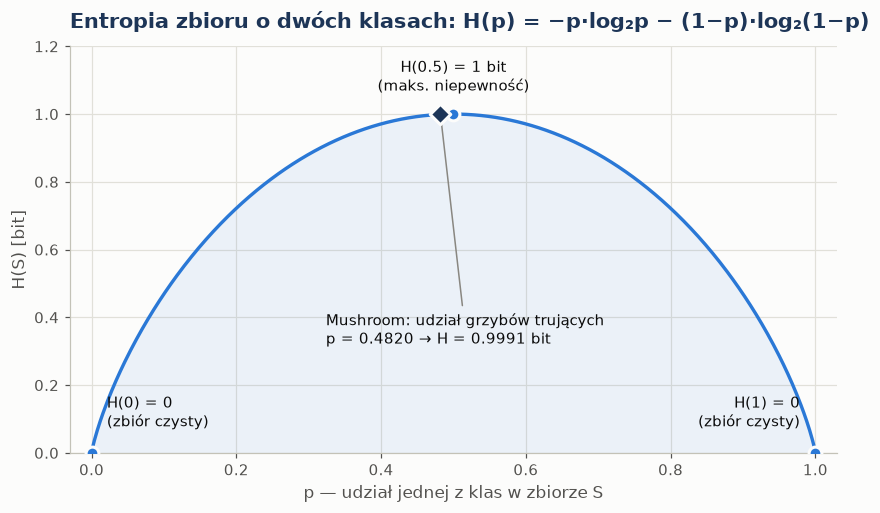

In [9]:
p_poisonous = float((y_all == "p").mean())
note(p_poisonous=p_poisonous, H_class=entropy(y_all))
show(plot_entropy_curve(("Mushroom: udział grzybów trujących", p_poisonous)), "01_entropy_curve")

**Interpretacja.** Krzywa jest symetryczna i wklęsła. Zero bitów niepewności mają zbiory czyste (`p = 0` lub `p = 1`),
maksimum, 1 bit, przypada na równowagę klas. W zbiorze Mushroom grzyby trujące stanowią 48.20%
obserwacji, więc entropia całego zbioru wynosi 0.9991 bita, czyli prawie maksimum. Zadaniem drzewa jest
sprowadzenie tej niepewności do zera w liściach.

## 1.2. Pseudokod ID3

```text
ID3(S, A, d)                     ▷ S – przykłady, A – niewykorzystane atrybuty, d – głębokość węzła
 1  utwórz węzeł N; zapisz w nim rozkład klas S, klasę większościową, |S| i H(S)
 2  jeżeli wszystkie przykłady S należą do jednej klasy c:      zwróć liść(c)
 3  jeżeli A = ∅:                                              zwróć liść(klasa większościowa S)
 4  jeżeli d = max_depth lub |S| < min_samples_split:          zwróć liść(klasa większościowa S)   ▷ rozszerzenie
 5  dla każdego a ∈ A oblicz IG(S, a)
 6  a* ← argmax IG(S, a)                                      ▷ remis → alfabetycznie po nazwie
 7  jeżeli IG(S, a*) ≤ ε lub IG(S, a*) < min_information_gain: zwróć liść(klasa większościowa S)
 8  N.atrybut ← a*
 9  dla każdej wartości v atrybutu a* występującej w S:
10      S_v ← { x ∈ S : x[a*] = v }
11      N.dziecko[v] ← ID3(S_v, A \ {a*}, d + 1)
12  zwróć N

PREDYKCJA(N, x)
 1  dopóki N nie jest liściem:
 2      v ← x[N.atrybut]
 3      jeżeli v ∉ N.dzieci:  zwróć N.klasa_większościowa    ▷ kategoria niewidziana w treningu
 4      N ← N.dziecko[v]
 5  zwróć N.klasa
```

Kroki 4 i 7 z parametrami `max_depth`, `min_samples_split` i `min_information_gain` to **dydaktyczne rozszerzenia**
(*pre-pruning*, przycinanie wstępne). Klasyczny ID3 Quinlana zatrzymuje się tylko w krokach 2–3. Próg
$\varepsilon = 10^{-12}$ chroni przed gałęziami o zerowym przyroście informacji. Remisy klas w liściu
rozstrzygamy na korzyść klasy `p`: przy niepewności bezpieczniej uznać grzyb za trujący.

## 1.3. Przykład: pierwsze rozgałęzienie „ręcznie”

Losujemy z Mushroom **12 rzeczywistych rekordów**, po 6 z każdej klasy (`random_state=42`), i trzy atrybuty:
`odor`, `gill-size`, `bruises`. Liczymy entropię zbioru, entropię każdej gałęzi i przyrost informacji, czyli
dokładnie to, co ID3 robi w korzeniu. Wszystkie liczby wylicza kod. Próbka służy wyłącznie ilustracji wzoru i nie
wpływa na żaden model.

In [10]:
example = (df.groupby("class", group_keys=False).sample(n=6, random_state=42)
           [["odor", "gill-size", "bruises", "class"]].reset_index(drop=True))
display(expand_frame(example))

,odor,gill-size,bruises,class
0,none (n),broad (b),bruises (t),jadalny (e)
1,none (n),narrow (n),no (f),jadalny (e)
2,none (n),broad (b),bruises (t),jadalny (e)
3,none (n),broad (b),no (f),jadalny (e)
4,none (n),broad (b),no (f),jadalny (e)
5,none (n),narrow (n),no (f),jadalny (e)
6,spicy (s),narrow (n),no (f),trujący (p)
7,foul (f),broad (b),no (f),trujący (p)
8,foul (f),broad (b),no (f),trujący (p)
9,spicy (s),narrow (n),no (f),trujący (p)


In [11]:
def h_terms(counts) -> str:
    # Rozpisanie -Σ p·log2(p) w LaTeX-u; dla zbioru czystego zwraca 0.
    n, nonzero = sum(counts), [c for c in counts if c]
    if len(nonzero) == 1:
        return r"0 \;\text{(zbiór czysty)}"
    return " ".join(rf"- \tfrac{{{c}}}{{{n}}}\log_2\tfrac{{{c}}}{{{n}}}" for c in nonzero)


def gain_derivation(frame: pd.DataFrame, feature: str, target: str = "class") -> str:
    labels = sorted(frame[target].unique())
    h_parent = entropy(frame[target])
    terms = gain_breakdown(frame[feature], frame[target])
    rows = [rf"H(S) &= {h_terms(frame[target].value_counts().reindex(labels).tolist())} = {h_parent:.4f}"]
    for row in terms.itertuples(index=False):
        counts = [getattr(row, f"n_{label}") for label in labels]
        rows.append(rf"H(S_{{\text{{{feature}}}={row.value}}}) &= {h_terms(counts)} = {row.entropy:.4f}")
    weighted = " + ".join(rf"\tfrac{{{r.n}}}{{{len(frame)}}}\cdot{r.entropy:.4f}" for r in terms.itertuples())
    gain = information_gain(frame[feature], frame[target])
    rows.append(rf"IG(S, \text{{{feature}}}) &= {h_parent:.4f} - \left({weighted}\right) = \mathbf{{{gain:.4f}}}")
    return r"\begin{aligned}" + r" \\ ".join(rows) + r"\end{aligned}"


display(Math(gain_derivation(example, "gill-size")))
display(Math(gain_derivation(example, "odor")))
example_gains = information_gain_table(example[["odor", "gill-size", "bruises"]], example["class"])
display(example_gains)
eg = example_gains.set_index("feature")
note(ex_n=len(example), ex_best=example_gains.iloc[0]["feature"], ex_ig_odor=eg.loc["odor", "information_gain"],
     ex_ig_bruises=eg.loc["bruises", "information_gain"], ex_ig_gill=eg.loc["gill-size", "information_gain"],
     ex_odor_values=int(eg.loc["odor", "n_values"]), ex_gr_odor=eg.loc["odor", "gain_ratio"],
     ex_gr_bruises=eg.loc["bruises", "gain_ratio"])

<IPython.core.display.Math object>

<IPython.core.display.Math object>

,rank,feature,n_values,information_gain,split_information,gain_ratio
0,1,odor,4,1.000000,1.729574,0.578177
1,2,bruises,2,0.190875,0.650022,0.293643
2,3,gill-size,2,0.020721,0.979869,0.021147


**Interpretacja.** W 12-elementowej próbce `odor` przyjmuje 4 wartości i rozdziela klasy
**idealnie**: każda gałąź jest czysta, więc $IG = H(S) =$ 1.0000 bita. Rozkłady `gill-size` w obu
gałęziach są prawie takie same jak w całej próbce, stąd IG zaledwie 0.0207. `bruises` daje
0.1909. ID3 wybrałby więc `odor`. Kolumna `gain_ratio` pokazuje korektę z C4.5 (sekcja 1.4).
Dzieląc IG przez entropię samego podziału (*SplitInfo*), zmniejsza ona przewagę atrybutu o wielu wartościach:
0.578 dla `odor` wobec 0.294 dla `bruises`.

## 1.4. Ograniczenia ID3

| Ograniczenie | Na czym polega | Typowa odpowiedź |
|---|---|---|
| **Preferencja atrybutów wielowartościowych** | IG rośnie z liczbą kategorii, bo wiele małych gałęzi „za darmo” obniża entropię. Identyfikator rekordu daje $IG = H(S)$. | **Gain Ratio** (C4.5): $GR = IG(S,A) / SplitInfo(S,A)$, gdzie $SplitInfo(S,A) = -\sum_v \frac{\lvert S_v\rvert}{\lvert S\rvert}\log_2\frac{\lvert S_v\rvert}{\lvert S\rvert}$ |
| **Szum i przeuczenie** | Drzewo rośnie do czystych liści, więc dopasowuje się również do przypadkowych wyjątków. | przycinanie wstępne (głębokość, liczność, próg IG) lub następcze (C4.5, CART); zbiór walidacyjny |
| **Tylko atrybuty nominalne** | Klasyczny ID3 nie dzieli zmiennych ciągłych. | wcześniejsza **dyskretyzacja**: przedziały równej szerokości lub częstości, progi wg entropii (Fayyad–Irani, 1993); w C4.5 progi binarne |
| **Braki danych** | Test $x[a] = v$ nie ma sensu dla nieznanej wartości. | jawna kategoria „brak”, imputacja dopasowana na zbiorze uczącym, ułamkowe przykłady w C4.5 |
| **Zachłanność** | Lokalnie najlepszy podział nie gwarantuje najmniejszego drzewa. Budowa optymalnego drzewa jest NP-zupełna (Hyafil, Rivest, 1976). | akceptujemy; alternatywą są komitety (lasy losowe, *boosting*) |
| **Złożoność obliczeniowa** | Węzeł z $n$ przykładami i $m$ kandydatami kosztuje $O(n\,m)$. Przykłady jednego poziomu się nie powtarzają, więc poziom kosztuje $O(N\,d)$, a głębokość nie przekracza $d$. | budowa w najgorszym razie $O(N\,d^2)$, predykcja $O(\text{głębokość}) \le O(d)$; na Mushroom jedno drzewo powstaje w ułamku sekundy |

## 1.5. Biblioteki zawierające algorytm ID3

Zestawienie ma charakter informacyjny. Zgodnie z wymaganiami **nie trenujemy** tych implementacji i nie
porównujemy ich wyników. Wszystkie modele w notebooku powstają z własnej implementacji (`src/id3.py`).

| Biblioteka | Środowisko / język | Czy to ID3? | Ograniczenia, uwagi | Źródło |
|---|---|---|---|---|
| **WEKA** `weka.classifiers.trees.Id3` | Java: GUI Explorer, CLI, API; pakiet `simpleEducationalLearningSchemes` | **tak**, klasyczny ID3 | tylko atrybuty nominalne, brak obsługi braków danych, drzewo nieprzycinane; puste gałęzie mogą zostawić przykład niesklasyfikowany | [dokumentacja WEKA](https://weka.sourceforge.io/doc.packages/simpleEducationalLearningSchemes/weka/classifiers/trees/Id3.html) |
| **RWeka** | R, interfejs do WEKA (wymaga Javy) | **tak**, pośrednio: `WPM("install-package", "simpleEducationalLearningSchemes")`, potem `make_Weka_classifier("weka/classifiers/trees/Id3")` | ograniczenia jak w WEKA; zależność od `rJava` | [CRAN: RWeka](https://cran.r-project.org/package=RWeka) |
| **chefboost** | Python | **tak**, obok C4.5, CART, CHAID i drzew regresyjnych | cechy liczbowe zamienia na binarne progi `<=x` / `>x`, co wykracza poza klasyczny ID3 | [GitHub: serengil/chefboost](https://github.com/serengil/chefboost) |
| **decision-tree-id3** | Python, API zgodne ze scikit-learn (`Id3Estimator`) | **tak**, z rozszerzeniami (cechy liczbowe, opcjonalne przycinanie) | ostatnie wydanie 0.1.2 z maja 2017; zgodności z bieżącymi wersjami bibliotek nie badano | [PyPI](https://pypi.org/project/decision-tree-id3/) |
| **scikit-learn** `DecisionTreeClassifier(criterion="entropy")` | Python | **nie**: zoptymalizowany CART | wyłącznie podziały **binarne** na progach liczbowych; brak natywnych cech kategorycznych; `criterion="entropy"` zmienia tylko miarę nieczystości | [dokumentacja scikit-learn, 1.10.6](https://scikit-learn.org/stable/modules/tree.html#tree-algorithms-id3-c4-5-c5-0-and-cart) |
| R `rpart` | R | **nie**: CART | podziały binarne (Gini lub *information*) | [CRAN: rpart](https://cran.r-project.org/package=rpart) |
| R `C50` | R | **nie**: C5.0, następca C4.5 | inne kryterium (Gain Ratio), przycinanie, *boosting* | [CRAN: C50](https://cran.r-project.org/package=C50) |

**Dlaczego `DecisionTreeClassifier` nie jest ID3?** Buduje wyłącznie drzewa binarne: każdy węzeł zadaje
pytanie „$x_j \le t$?”. Kategorię trzeba zakodować liczbą (porządek kodów jest sztuczny) albo rozbić na zmienne
zero-jedynkowe (wtedy jeden test sprawdza jedną kategorię). Atrybut może się też powtarzać na ścieżce. ID3 tworzy
jedną gałąź dla każdej kategorii i każdy atrybut testuje na ścieżce najwyżej raz. Powstają więc inne drzewa,
mimo tego samego kryterium entropii.

<a id="rozdzial-02"></a>
# 02. Zbiór danych Mushroom

**Pochodzenie.** Rekordy opisują *hipotetyczne* okazy 23 gatunków grzybów blaszkowych z rodzin *Agaricus*
i *Lepiota*, spisane z przewodnika *The Audubon Society Field Guide to North American Mushrooms* (1981). Zbiór
przekazał J. Schlimmer w 1987 roku, a dziś udostępnia go UCI Machine Learning Repository
(DOI 10.24432/C5959T) na licencji **CC BY 4.0**. Gatunki „o nieznanej jadalności, niezalecane” połączono
w źródle z trującymi, więc klasa `p` oznacza w praktyce „nie jeść”.

**Kontrakt danych** wg pliku `agaricus-lepiota.names`:

- 8124 rekordy, 22 atrybuty nominalne i klasa;
- rozkład klas 4208 `e` / 3916 `p`;
- 2480 braków oznaczonych `?`, wszystkie w atrybucie `stalk-root`.

Sprawdzamy to na surowym pliku, przed jakąkolwiek modyfikacją.

In [12]:
display(zip_members(DATA_ZIP))
display(contract_report)
names_check = compare_with_names_file(DATA_ZIP)
print(f"Słownik kategorii w kodzie zgodny z sekcją 7 pliku .names: "
      f"{int(names_check['zgodne'].sum())}/{len(names_check)} cech")
note(n_rows=df.shape[0], n_columns=df.shape[1], n_features=X_all.shape[1],
     n_e=int((y_all == "e").sum()), n_p=int((y_all == "p").sum()),
     share_e=float((y_all == "e").mean()), share_p=float((y_all == "p").mean()),
     n_missing_total=int(df.isna().sum().sum()), missing_share=float(df["stalk-root"].isna().mean()),
     names_ok=int(names_check["zgodne"].sum()))

,plik,rozmiar [B]
0,Index,193
1,README,853
2,agaricus-lepiota.data,373704
3,agaricus-lepiota.names,6816
4,expanded.Z,111577


,kontrola,oczekiwane (UCI),zaobserwowane,zgodne
0,liczba wierszy,8124,8124,True
1,liczba kolumn (klasa + 22 cechy),23,23,True
2,rozkład klas e / p,"{'e': 4208, 'p': 3916}","{'e': 4208, 'p': 3916}",True
3,znaki '?' w stalk-root,2480,2480,True
4,znaki '?' w pozostałych kolumnach,{},{},True


Słownik kategorii w kodzie zgodny z sekcją 7 pliku .names: 22/22 cech


**Interpretacja.** Wszystkie pięć kontroli kontraktu jest zgodnych z dokumentacją UCI: wymiary
8124 × 23, klasy 4208 `e` / 3916 `p`, liczba znaków `?` równa 2480,
wyłącznie w `stalk-root`. Słownik kategorii zapisany w kodzie (`CATEGORY_NAMES`) jest identyczny z plikiem `.names` dla
22/22 cech. Archiwum zawiera też pliki pomocnicze (`Index`, `README`, `expanded.Z`), z których nie
korzystamy.

### Słownik cech i kategorii
Wszystkie atrybuty są nominalne. Kody jednoliterowe rozwijamy na nazwy z dokumentacji,
np. `odor = f` → `foul (f)`.

In [13]:
display(dictionary_frame())

,cecha,znaczenie,liczba kategorii (UCI),kategorie (kod = nazwa)
0,cap-shape,kształt kapelusza,6,"b=bell, c=conical, x=convex, f=flat, k=knobbed, s=sunken"
1,cap-surface,powierzchnia kapelusza,4,"f=fibrous, g=grooves, y=scaly, s=smooth"
2,cap-color,kolor kapelusza,10,"n=brown, b=buff, c=cinnamon, g=gray, r=green, p=pink, u=purple, e=red, w=white, y=yellow"
3,bruises,siniaczenie po uszkodzeniu,2,"t=bruises, f=no"
4,odor,zapach,9,"a=almond, l=anise, c=creosote, y=fishy, f=foul, m=musty, n=none, p=pungent, s=spicy"
5,gill-attachment,przyrośnięcie blaszek,4,"a=attached, d=descending, f=free, n=notched"
6,gill-spacing,rozstaw blaszek,3,"c=close, w=crowded, d=distant"
7,gill-size,szerokość blaszek,2,"b=broad, n=narrow"
8,gill-color,kolor blaszek,12,"k=black, n=brown, b=buff, h=chocolate, g=gray, r=green, o=orange, p=pink, u=purple, e=red, w=white, y=yellow"
9,stalk-shape,kształt trzonu,2,"e=enlarging, t=tapering"


### Przykładowe rekordy
Pięć pierwszych wierszy po rozwinięciu kodów (transpozycja: cechy w wierszach). Brak danych w `stalk-root`
pokazujemy jako „brak danych (?)”.

In [14]:
display(expand_frame(df.head(5)).T.rename(columns=lambda i: f"rekord {i}"))

,rekord 0,rekord 1,rekord 2,rekord 3,rekord 4
class,trujący (p),jadalny (e),jadalny (e),trujący (p),jadalny (e)
cap-shape,convex (x),convex (x),bell (b),convex (x),convex (x)
cap-surface,smooth (s),smooth (s),smooth (s),scaly (y),smooth (s)
cap-color,brown (n),yellow (y),white (w),white (w),gray (g)
bruises,bruises (t),bruises (t),bruises (t),bruises (t),no (f)
odor,pungent (p),almond (a),anise (l),pungent (p),none (n)
gill-attachment,free (f),free (f),free (f),free (f),free (f)
gill-spacing,close (c),close (c),close (c),close (c),crowded (w)
gill-size,narrow (n),broad (b),broad (b),narrow (n),broad (b)
gill-color,black (k),black (k),brown (n),brown (n),black (k)


### Rozkład klas i profil cech

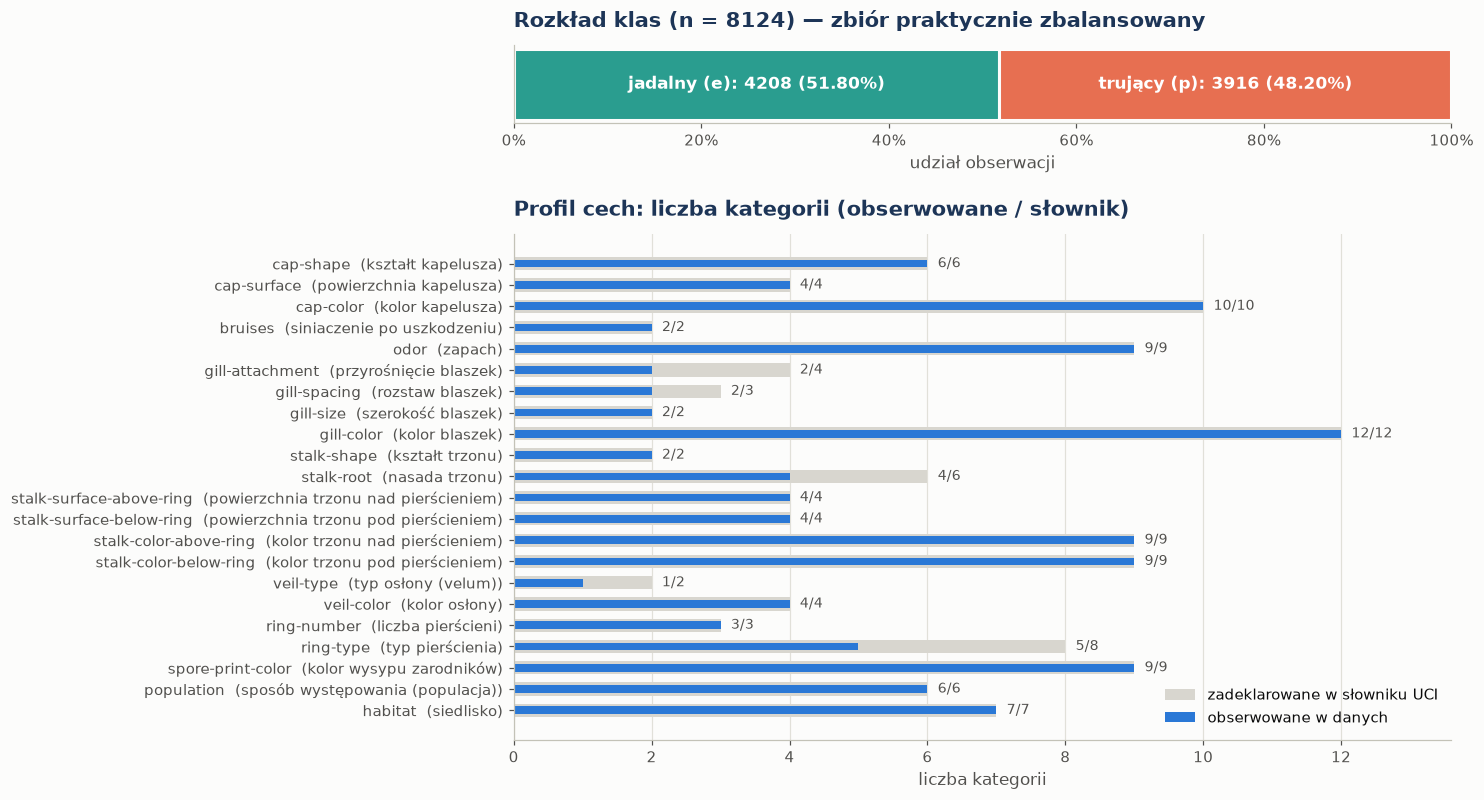

In [15]:
profile = feature_profile(X_all)
unobserved = unobserved_categories(X_all)
show(plot_dataset_overview(y_all, profile), "02_dataset_overview")
note(max_cardinality=int(profile["kategorie obserwowane"].max()),
     max_cardinality_feature=profile.loc[profile["kategorie obserwowane"].idxmax(), "cecha"],
     n_features_unobserved=len(unobserved))

**Interpretacja.** Klasy są prawie równoliczne: 51.80% jadalnych i 48.20% trujących.
Liczba obserwowanych kategorii waha się od 1 (`veil-type`) do 12 (`gill-color`).
W 5 cechach część kategorii ze słownika nie występuje ani razu (np. `veil-type = universal`,
`stalk-root = cup`). To właściwość próby, a nie błąd danych: drzewo nie utworzy dla nich gałęzi, a mechanizm
predykcji obsłuży je awaryjnie (rozdz. 04.6).

<a id="rozdzial-03"></a>
# 03. Analiza danych i czyszczenie

Analiza w tym rozdziale jest **opisowa** i obejmuje cały zbiór. Żadna decyzja wpływająca na model nie jest tu
jednak podejmowana na podstawie zbioru testowego. Transformacje uczone z danych (dominanty, kategorie, lista cech
stałych) dopasowujemy w rozdziale 04 wyłącznie na zbiorze uczącym.

## 3.1. Audyt jakości danych
Sprawdzamy typy, zgodność wartości ze słownikiem UCI, format kodów, puste napisy, etykiety klas, duplikaty
(pełne i sprzeczne), braki, cechy stałe oraz kategorie zadeklarowane, ale nieobecne. **Wynik negatywny**
(„nie znaleziono”) też jest wynikiem i pokazujemy go jawnie.

In [16]:
audit = data_quality_audit(df)
display(audit)
duplicates_raw = duplicate_stats(X_all, y_all)
note(n_out_of_domain=sum(len(v) for v in out_of_domain_values(X_all).values()),
     n_dup_rows=duplicates_raw["duplicate_rows"], n_dup_vectors=duplicates_raw["duplicate_feature_vectors"],
     n_conflicts=duplicates_raw["conflicting_vectors"])

,kontrola,wynik,status
0,typy kolumn,22/22 kolumn tekstowych (nominalnych),OK - brak problemu
1,wartości spoza słownika UCI,0,OK - brak problemu
2,format kodu (1 mała litera),0 niezgodnych wartości,OK - brak problemu
3,puste napisy / białe znaki,0 wartości,OK - brak problemu
4,"etykiety klas spoza {e, p}",0,OK - brak problemu
5,pełne duplikaty wierszy (cechy + klasa),0,OK - brak problemu
6,duplikaty wektorów cech,0,OK - brak problemu
7,"sprzeczne etykiety (te same cechy, inna klasa)",0,OK - brak problemu
8,braki danych ('?' -> NaN),stalk-root: 2480 (30.53%),"do obsłużenia (3 strategie, rozdz. 04)"
9,cechy stałe (1 wartość),veil-type,do usunięcia (zerowy IG)


**Interpretacja.** Audyt **nie znalazł błędnych danych**:

- wartości spoza słownika UCI: 0;
- pełne duplikaty wierszy: 0;
- powtórzone wektory cech: 0;
- wektory z różnymi klasami: 0;
- poza tym brak nieprawidłowych typów, pustych napisów i nietypowych kodów.

Do obsłużenia zostają dwa problemy wynikające z dokumentacji: braki w `stalk-root` (3.2) i stała cecha `veil-type`
(3.6). Kategorie niewystępujące w danych mają charakter informacyjny.

## 3.2. Braki danych w `stalk-root`
Braki liczymy **po zamianie `?` na NaN**, czyli jako brakującą obserwację, a nie poprawną wartość biologiczną.
Sprawdzamy też, czy braki są losowe (MCAR) czy powiązane z klasą. Zależność od klasy przemawia przeciw MCAR,
a brak sam w sobie staje się wtedy informacją.

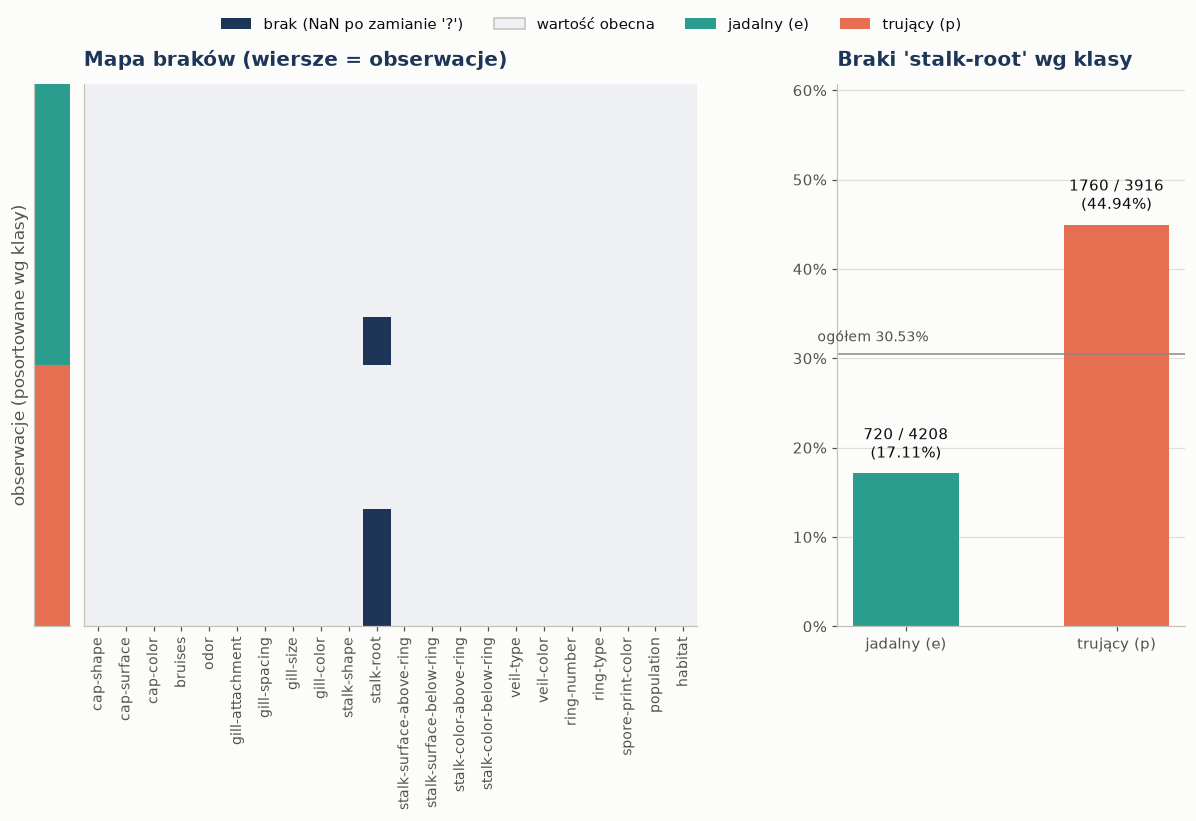

,braki,obserwacje,odsetek braków
class,,,
e,720,4208,0.171103
p,1760,3916,0.449438


Test niezależności χ²(1) = 740.9, log10(p) ≈ -162;  V Craméra(brak, klasa) = 0.302


In [17]:
from scipy.stats import chi2, chi2_contingency

missing_flag = df["stalk-root"].isna().rename("brak stalk-root")
missing_by_class = (missing_flag.groupby(y_all).agg(["sum", "count", "mean"])
                    .rename(columns={"sum": "braki", "count": "obserwacje", "mean": "odsetek braków"}))
chi2_stat = chi2_contingency(pd.crosstab(missing_flag, y_all), correction=False)[0]
log10_p = chi2.logsf(chi2_stat, df=1) / np.log(10)
show(plot_missing_overview(df), "03_missing_values")
display(missing_by_class)
print(f"Test niezależności χ²(1) = {chi2_stat:.1f}, log10(p) ≈ {log10_p:.0f};  "
      f"V Craméra(brak, klasa) = {cramers_v(missing_flag, y_all):.3f}")
note(miss_e_n=int(missing_by_class.loc["e", "braki"]), miss_e_share=float(missing_by_class.loc["e", "odsetek braków"]),
     miss_p_n=int(missing_by_class.loc["p", "braki"]), miss_p_share=float(missing_by_class.loc["p", "odsetek braków"]),
     miss_ratio=float(missing_by_class.loc["p", "odsetek braków"] / missing_by_class.loc["e", "odsetek braków"]),
     miss_chi2=float(chi2_stat), miss_v=cramers_v(missing_flag, y_all))

**Interpretacja.** Braki dotyczą wyłącznie `stalk-root` (2480 z 8124, czyli 30.53%).
Nie rozkładają się jednak równo między klasy: brakuje 17.11% wartości u grzybów jadalnych
(720) i 44.94% u trujących (1760), 2.63 razy częściej. Test χ²
(740.9) jednoznacznie odrzuca niezależność braku od klasy, więc braki **nie są MCAR**, a sam fakt braku
niesie informację (V Craméra 0.302). To argument za strategią „brak jako osobna kategoria” (rozdz. 04).
Mapa braków pokazuje dodatkowo, że w żadnej innej kolumnie braków nie ma.

## 3.3. Rozkłady kategorii względem klasy

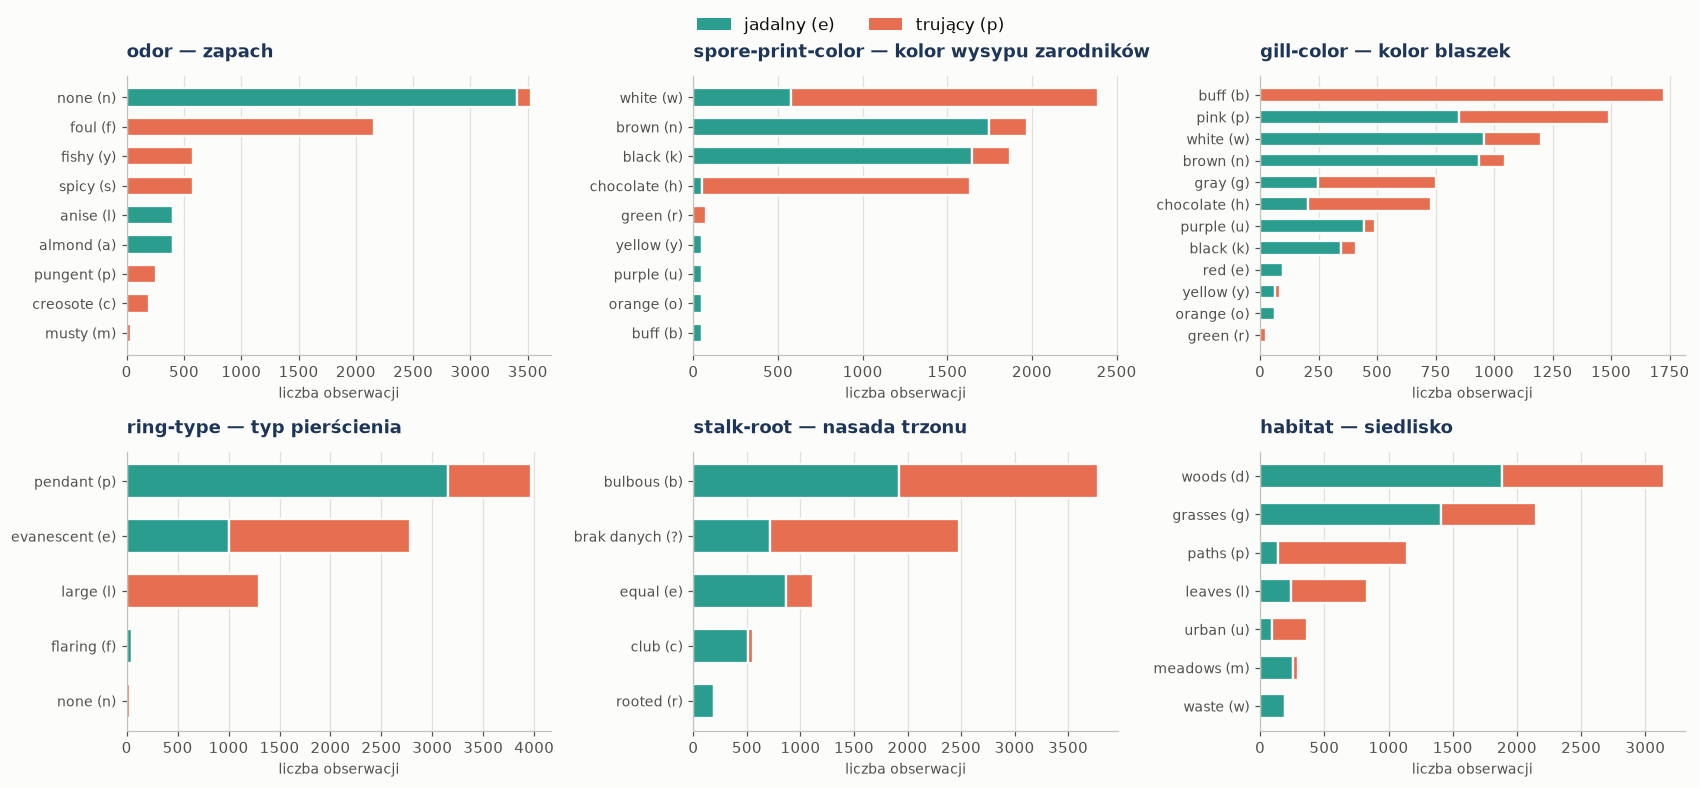

In [18]:
show(plot_category_distributions(df, ["odor", "spore-print-color", "gill-color", "ring-type", "stalk-root",
                                      "habitat"]), "03_category_distributions")
odor_purity = pd.crosstab(X_all["odor"], y_all)
none_counts = odor_purity.loc["n"]
note(odor_pure_categories=int((odor_purity.min(axis=1) == 0).sum()), odor_categories=len(odor_purity),
     odor_none_n_full=int(none_counts.sum()), odor_none_p_full=int(none_counts["p"]))

**Interpretacja.** `odor` jest niemal deterministyczny: 8 z 9 zapachów
występuje tylko w jednej klasie (migdałowy i anyżowy tylko u jadalnych, cuchnący, rybi czy ostry tylko
u trujących). Mieszany pozostaje wyłącznie zapach `none`: 3528 grzybów, w tym 120
trujących. Właśnie tam drzewo będzie musiało szukać kolejnych testów. Podobnie silnie rozdziela klasy
`spore-print-color` (np. `green` występuje tylko u trujących). Kategoria „brak danych” w `stalk-root` jest w większości
trująca, co potwierdza wniosek z 3.2.

## 3.4. Korelacje i zależności między cechami nominalnymi
Współczynnik Pearsona dla kodów liczbowych nie ma sensu: kolejność `a < c < f …` jest arbitralna, więc wynik
zależałby od przypadkowego kodowania. Dla par zmiennych nominalnych stosujemy **V Craméra**

$$V = \sqrt{\frac{\chi^2}{n \cdot \min(r-1,\; c-1)}} \in [0, 1],$$

gdzie $r, c$ to liczby kategorii, a $\chi^2$ to statystyka testu niezależności tablicy kontyngencji. Dla cechy
stałej (`veil-type`: $r = 1$) mianownik jest zerem. Funkcja `cramers_v` zwraca wtedy jawnie $0.0$ zamiast
dzielić przez zero lub zwracać NaN. Z klasą zestawiamy też **informację wzajemną** $I(A;Y)$ (równą IG w korzeniu)
i **U Theila** $U(Y\mid A) = I(A;Y) / H(Y)$, czyli odsetek niepewności o klasie usuwany przez cechę.
Informację wzajemną liczy niezależna implementacja ze scikit-learn.

,cecha,kategorie,V Craméra,I(A;Y) [bit],U Theila
0,odor,9,0.971005,0.906075,0.906920
1,spore-print-color,9,0.752645,0.480705,0.481153
2,gill-color,12,0.680830,0.416978,0.417367
3,ring-type,5,0.603271,0.318022,0.318318
4,stalk-surface-above-ring,4,0.587944,0.284726,0.284991
5,stalk-surface-below-ring,4,0.574837,0.271894,0.272148
6,stalk-color-above-ring,9,0.524850,0.253845,0.254082
7,stalk-color-below-ring,9,0.514725,0.241416,0.241641
8,gill-size,2,0.540024,0.230154,0.230369
9,population,6,0.487376,0.201958,0.202146


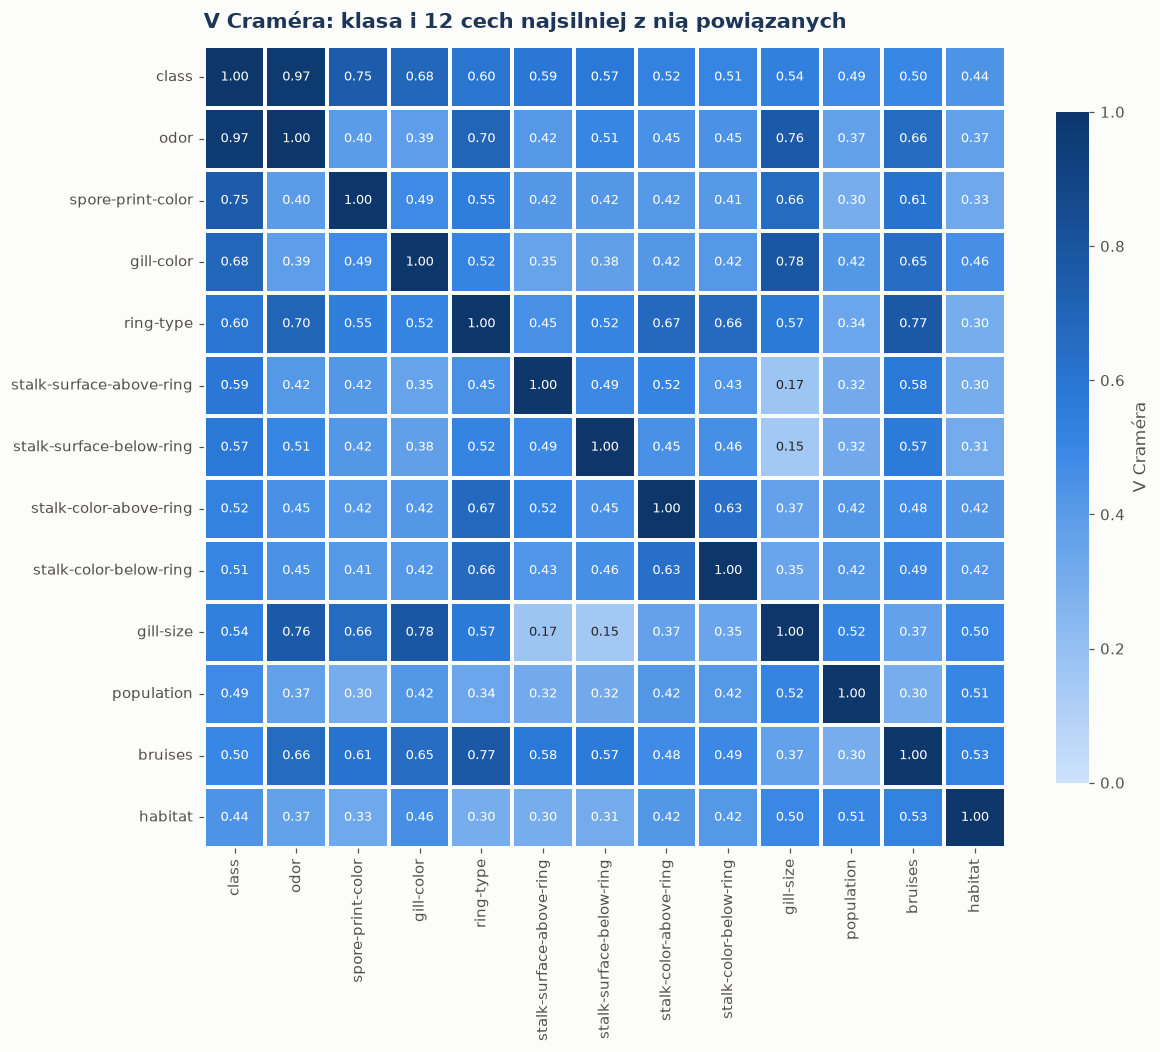

In [19]:
association = association_with_target(X_all, y_all)
display(association.head(10))
top_features = association["cecha"].head(12).tolist()
show(plot_cramers_v_heatmap(cramers_v_matrix(df, ["class", *top_features]),
                            "V Craméra: klasa i 12 cech najsilniej z nią powiązanych"), "03_cramers_v")
full_matrix = cramers_v_matrix(X_all)                       # wszystkie 22 cechy, w tym stała veil-type
upper = np.triu_indices(len(full_matrix), k=1)
k = int(np.argmax(full_matrix.to_numpy()[upper]))
assoc = association.set_index("cecha")
note(v_odor=assoc.loc["odor", "V Craméra"], mi_odor=assoc.loc["odor", "I(A;Y) [bit]"],
     u_odor=assoc.loc["odor", "U Theila"], v_spore=assoc.loc["spore-print-color", "V Craméra"],
     v_veil=assoc.loc["veil-type", "V Craméra"],
     top_pair_a=full_matrix.index[upper[0][k]], top_pair_b=full_matrix.columns[upper[1][k]],
     top_pair_v=float(full_matrix.to_numpy()[upper][k]), matrix_has_nan=bool(full_matrix.isna().any().any()))

**Interpretacja.**

- Najsilniej z klasą wiąże się `odor`: V = 0.971, $I(A;Y)$ = 0.906 bita, czyli
  90.7% niepewności o klasie. Na drugim miejscu jest `spore-print-color` (V = 0.753).
- Między samymi cechami najsilniej powiązana jest para `gill-attachment` – `stalk-color-above-ring` (V = 0.98).
  Takie redundancje **nie szkodzą** ID3: po wybraniu jednej cechy przyrost informacji drugiej w gałęziach spada
  i algorytm sam ją pomija.
- Stała `veil-type` ma V = 0.0. Pełna macierz 22 × 22 nie zawiera ani jednej wartości NaN.

## 3.5. Balansowanie klas

In [20]:
class_balance = y_all.value_counts().rename("liczność").to_frame()
class_balance["udział"] = class_balance["liczność"] / len(y_all)
display(class_balance)
note(imbalance_ratio=float(class_balance["liczność"].max() / class_balance["liczność"].min()))

,liczność,udział
class,,
e,4208,0.517971
p,3916,0.482029


**Decyzja: świadomie nie balansujemy.** Stosunek klas wynosi 1.075 : 1 (51.80% / 48.20%).
To rozkład praktycznie zrównoważony, przy którym nadpróbkowanie nie usuwa żadnego realnego problemu. Wnosiłoby
natomiast ryzyko:

- SMOTE interpoluje cechy liczbowe, a dla cech nominalnych tworzyłby sztuczne, nieistniejące grzyby;
- zduplikowane rekordy trafiłyby do różnych podzbiorów i zawyżyły wyniki walidacji.

Zamiast tego **stratyfikujemy** podział (rozdz. 04), więc każdy podzbiór zachowuje proporcje klas. Oceniamy model
miarami odpornymi na nierównowagę (macro-F1, czułość klasy `p`, liczba błędów `p → e`).

## 3.6. Zbędne atrybuty: cecha stała `veil-type`
**Kryterium usuwania:** atrybut ma najwyżej jedną obserwowaną wartość, więc $H(A) = 0$ i $IG = 0$ w każdym węźle.
Takiego atrybutu ID3 nigdy nie wybierze. Usunięcie go nie zmienia modelu, a upraszcza dane i analizy.
Cecha stała na całym zbiorze jest stała w każdym jego podzbiorze. Preprocesor stosuje to samo kryterium
do zbioru uczącego (rozdz. 04), co sprawdzamy asercją.

In [21]:
constant = find_constant_features(X_all)
ig_veil = information_gain(X_all["veil-type"], y_all)
before_after = pd.DataFrame([
    {"etap": "dane surowe", "liczba cech": X_all.shape[1], "cechy stałe": ", ".join(constant),
     "kolumny z brakami": ", ".join(X_all.columns[X_all.isna().any()])},
    {"etap": "po usunięciu cech stałych", "liczba cech": X_all.shape[1] - len(constant), "cechy stałe": "—",
     "kolumny z brakami": ", ".join(X_all.drop(columns=constant).columns[X_all.drop(columns=constant).isna().any()])},
])
display(before_after)
print(f"veil-type: {X_all['veil-type'].value_counts().to_dict()} · H = {entropy(X_all['veil-type']):.1f} · "
      f"IG = {ig_veil:.1f} · V Craméra = {cramers_v(X_all['veil-type'], y_all):.1f}")
note(constant_features=", ".join(constant), ig_veil=ig_veil)

,etap,liczba cech,cechy stałe,kolumny z brakami
0,dane surowe,22,veil-type,stalk-root
1,po usunięciu cech stałych,21,—,stalk-root


veil-type: {'p': 8124} · H = 0.0 · IG = 0.0 · V Craméra = 0.0


**Interpretacja.** Jedyną cechą stałą jest `veil-type`: wszystkie 8124 grzyby mają osłonę częściową
(`partial`), a IG = 0.0. Usuwamy ją, a z danych modelowych zostaje 21 atrybutów. Innych cech nie usuwamy.
Słaby związek z klasą mierzony na całym zbiorze (np. `stalk-shape`) nie jest wystarczającym kryterium: w głębszych
węzłach słaba w korzeniu cecha może rozstrzygać trudne przypadki. Decyzję zostawiamy kryterium IG w każdym węźle.

<a id="rozdzial-04"></a>
# 04. Przygotowanie danych do budowy modelu

## 4.1. Odpowiedź na „???” z punktu 3 slajdu
Przed podziałem na dane uczące, walidacyjne i testowe trzeba wykonać kilka kroków. Każdy omawiamy i realizujemy
jawnie:

1. **Wydzielenie `X` i `y`:** macierz 22 cech nominalnych i wektor klasy `class`.
2. **Kodowanie zmiennych kategorycznych:** dla ID3 **nie stosujemy** One-Hot ani Ordinal Encodingu. ID3 rozgałęzia
   się bezpośrednio po symbolach (`odor = foul`). Kodowanie porządkowe wprowadziłoby nieistniejący porządek
   `a < c < f`, a one-hot rozbiłby jeden atrybut o 9 wartościach na 9 atrybutów binarnych i zniszczył podział
   wielogałęziowy.
3. **Dyskretyzacja zmiennych ciągłych:** klasyczny ID3 przyjmuje tylko atrybuty nominalne, więc każdą cechę
   liczbową trzeba wcześniej zamienić na przedziały. W Mushroom nie ma cech ciągłych i krok jest pusty, ale nasza
   implementacja go wymusza (demonstracja niżej).
4. **Losowe przetasowanie i stratyfikacja:** dwa kolejne podziały `train_test_split(shuffle=True, stratify=y,
   random_state=42)` dają podzbiory 60/20/20 z identycznymi proporcjami klas.
5. **Fit on train, transform on val/test:** wszystko, czego transformacja się uczy (cechy stałe, dominanta do
   imputacji, znane kategorie), wyznaczamy **wyłącznie na zbiorze uczącym**.

## 4.2. Kodowanie i dyskretyzacja w praktyce

In [22]:
demo = pd.DataFrame({"temperatura_C": [-3.5, 12.0, 21.5, 31.0]})
try:
    ID3Classifier().fit(demo, ["delayed", "on_time", "on_time", "delayed"])
except ValueError as error:
    print("ID3Classifier odrzuca cechę ciągłą →", error)
demo["temperatura"] = pd.cut(demo["temperatura_C"], bins=[-np.inf, 5, 25, np.inf],
                             labels=["zimno", "umiarkowanie", "gorąco"]).astype(str)
display(demo)
tiny = ID3Classifier().fit(demo[["temperatura"]], ["delayed", "on_time", "on_time", "delayed"])
print("Po dyskretyzacji: korzeń =", tiny.root_.feature, "| gałęzie:", list(tiny.root_.children))

ID3Classifier odrzuca cechę ciągłą → classic ID3 handles nominal attributes only; numeric columns ['temperatura_C'] must be discretised first (e.g. pd.cut) or explicitly cast to strings


,temperatura_C,temperatura
0,-3.5,zimno
1,12.0,umiarkowanie
2,21.5,umiarkowanie
3,31.0,gorąco


Po dyskretyzacji: korzeń = temperatura | gałęzie: ['gorąco', 'umiarkowanie', 'zimno']


**Interpretacja.** Implementacja nie zgaduje znaczenia liczb. Kolumnę liczbową trzeba świadomie zamienić na
przedziały (`pd.cut`), dopiero wtedy ID3 tworzy po jednej gałęzi dla każdego przedziału. W Mushroom wszystkie
cechy są już symbolami.

## 4.3. Podział 60 / 20 / 20 (stratyfikowany, `random_state=42`)
Zbiór testowy od razu trafia do **„sejfu”** (`HoldoutVault`). Do rozdziału 09 jest dostępny tylko dla audytów
danych, które nie dotykają modelu (rozdz. 4.5). Każdy dostęp jest logowany, a jednorazowe „otwarcie” do oceny
modelu finalnego jest możliwe tylko raz.

,zbiór,n,udział,n e,% e,n p,% p
0,uczący,4874,0.599951,2524,0.517850,2350,0.482150
1,walidacyjny,1625,0.200025,842,0.518154,783,0.481846
2,testowy,1625,0.200025,842,0.518154,783,0.481846


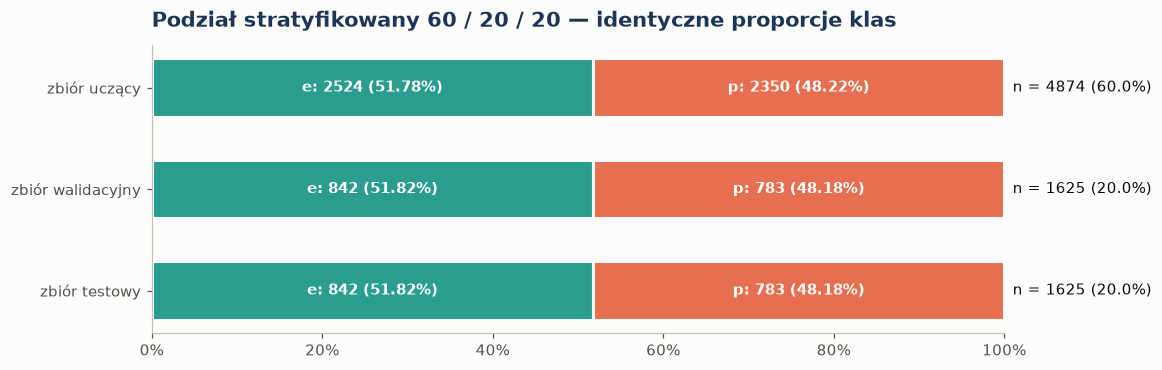

HoldoutVault('test', n=1625, zapieczętowany, dostępy=0)


In [23]:
split = make_stratified_split(y_all, train_size=0.6, validation_size=0.2, test_size=0.2, random_state=42)
split.assert_disjoint(len(y_all))
split_summary = split.summary(y_all)
display(split_summary)
show(plot_split_balance(split_summary), "04_split_balance")
split.assignment().to_csv(OUTPUT_DIR / "split_indices.csv", index=False)

X_train, y_train = X_all.loc[split.train], y_all.loc[split.train]
X_val, y_val = X_all.loc[split.validation], y_all.loc[split.validation]
test_vault = HoldoutVault(X_all.loc[split.test], y_all.loc[split.test])
print(test_vault)
shares = split_summary.set_index("zbiór")
note(n_train=len(split.train), n_val=len(split.validation), n_test=len(split.test),
     p_share_train=float(shares.loc["uczący", "% p"]), p_share_val=float(shares.loc["walidacyjny", "% p"]),
     p_share_test=float(shares.loc["testowy", "% p"]))

**Interpretacja.** Liczności podzbiorów: 4874 / 1625 / 1625. Indeksy są rozłączne
i razem pokrywają cały zbiór; sprawdza to `assert_disjoint`. Udział grzybów trujących wynosi 48.22%,
48.18% i 48.18%, czyli stratyfikacja zachowała proporcje co do setnej części procenta.
Przypisanie każdego wiersza do podzbioru zapisano w `outputs/split_indices.csv`.

## 4.4. Trzy strategie obsługi braków (dopasowanie tylko na zbiorze uczącym)

| Strategia | Transformacja | Uzasadnienie |
|---|---|---|
| `missing_category` | NaN → jawna kategoria `__MISSING__` | brak jest informatywny (3.2); ID3 natywnie obsługuje dodatkową kategorię |
| `most_frequent` | NaN → dominanta `stalk-root` **ze zbioru uczącego** | klasyczna imputacja; zaciera informację o braku |
| `drop_stalk_root` | usunięcie kolumny `stalk-root` | rezygnuje z atrybutu zamiast zgadywać wartości |

We wszystkich strategiach preprocesor usuwa też cechy stałe wykryte na zbiorze uczącym.

In [24]:
preprocessors = {strategy: CategoricalPreprocessor(strategy).fit(X_train) for strategy in MISSING_STRATEGIES}
strategy_table = pd.DataFrame([{
    "strategia": strategy,
    "usunięte kolumny": ", ".join(pre.dropped_features_),
    "liczba cech": len(pre.feature_names_out_),
    "braki stalk-root w train": pre.missing_counts_fit_.get("stalk-root", 0),
    "wartość wstawiana": pre.fill_values_.get("stalk-root", "— (kolumna usunięta)"),
    "kategorie stalk-root po transformacji": ", ".join(pre.categories_.get("stalk-root", [])) or "—",
    "NaN po transformacji (train / val)": f"{int(pre.transform(X_train).isna().sum().sum())} / "
                                          f"{int(pre.transform(X_val).isna().sum().sum())}",
} for strategy, pre in preprocessors.items()])
display(strategy_table)
assert all(pre.constant_features_ == ["veil-type"] for pre in preprocessors.values())
mode_value = preprocessors["most_frequent"].fill_values_["stalk-root"]
note(n_missing_train=preprocessors["missing_category"].missing_counts_fit_["stalk-root"],
     train_mode=mode_value, train_mode_label=expand_value("stalk-root", mode_value),
     n_features_model=len(preprocessors["missing_category"].feature_names_out_),
     n_features_drop=len(preprocessors["drop_stalk_root"].feature_names_out_))

,strategia,usunięte kolumny,liczba cech,braki stalk-root w train,wartość wstawiana,kategorie stalk-root po transformacji,NaN po transformacji (train / val)
0,missing_category,veil-type,21,1455,__MISSING__,"__MISSING__, b, c, e, r",0 / 0
1,most_frequent,veil-type,21,1455,b,"b, c, e, r",0 / 0
2,drop_stalk_root,"veil-type, stalk-root",20,0,— (kolumna usunięta),—,0 / 0


**Interpretacja.** Na zbiorze uczącym brakuje 1455 wartości `stalk-root`. Dominanta wyznaczona
**tylko na nim** to `bulbous (b)`. Strategia `most_frequent` wstawia ją również w zbiorze walidacyjnym
i testowym, nie zaglądając do ich rozkładów. Po każdej transformacji nie zostaje żaden NaN. Modele dostają
21 cech (`missing_category`, `most_frequent`) albo 20 (`drop_stalk_root`).
Asercja potwierdza, że kryterium cech stałych zastosowane do zbioru uczącego wskazuje `veil-type`, tak jak w 3.6.

## 4.5. Audyt duplikatów przed i po strategiach braków
Usunięcie kolumny albo imputacja mogą w ogólności sprawić, że różne rekordy staną się identyczne. Identyczny
wektor cech w treningu i teście oznaczałby przeciek: model „widziałby” przykład testowy, a sprzeczne etykiety
zaniżyłyby osiągalną trafność. Audyt korzysta z logowanego dostępu do zbioru testowego. Bada wyłącznie dane,
bez modelu i bez metryk.

In [25]:
X_test_audit, y_test_audit = test_vault.audit_view("audyt duplikatów: identyczne wektory cech między podzbiorami")
dup_audit = duplicate_audit({"train": (X_train, y_train), "validation": (X_val, y_val),
                             "test": (X_test_audit, y_test_audit)})
display(dup_audit)
note(dup_max=int(dup_audit.drop(columns=["wariant", "liczba cech"]).to_numpy().max()))
del X_test_audit, y_test_audit

,wariant,liczba cech,duplikaty wektorów cech,pełne duplikaty (cechy+klasa),wektory ze sprzeczną klasą,walidacja ∩ trening,test ∩ (trening+walidacja),w tym sprzeczne etykiety
0,"surowe (22 cechy, '?' jako symbol)",22,0,0,0,0,0,0
1,missing_category,21,0,0,0,0,0,0
2,most_frequent,21,0,0,0,0,0,0
3,drop_stalk_root,20,0,0,0,0,0,0


**Interpretacja.** Wynik jest **negatywny w każdym wariancie**: największa liczba w tabeli wynosi 0.
Wbrew obawie, że `drop_stalk_root` albo imputacja dominantą „skleją” rekordy, w Mushroom żadne dwa grzyby nie
różnią się wyłącznie wartością `stalk-root`. Żaden wektor cech ze zbioru testowego nie występuje więc w danych
uczących ani walidacyjnych i nie ma sprzecznych etykiet. Narzędzia audytu wykrywają duplikaty poprawnie;
sprawdza to test na danych z celowo podłożonymi duplikatami (`tests/test_preprocessing.py`).

## 4.6. Kategorie niewidziane w treningu

In [26]:
unseen = {strategy: pre.unseen_categories(X_val) for strategy, pre in preprocessors.items()}
display(pd.DataFrame([{"strategia": s, "niewidziane kategorie w walidacji": str(u) if u else "brak"}
                      for s, u in unseen.items()]))
note(n_unseen_val=sum(len(values) for found in unseen.values() for values in found.values()))

,strategia,niewidziane kategorie w walidacji
0,missing_category,brak
1,most_frequent,brak
2,drop_stalk_root,brak


**Interpretacja.** W walidacji nie ma kategorii nieznanych ze zbioru uczącego (łącznie 0).
Gdyby się pojawiły, preprocesor ich nie ukrywa, a ID3 przy predykcji zwraca **klasę większościową ostatniego
węzła**, do którego przykład dotarł. Ten węzeł ma zapisany rozkład klas z treningu. Model nie zgłasza wyjątku
i nie zagląda do danych testowych. Mechanizm sprawdzają testy jednostkowe (`tests/test_id3.py`).

<a id="rozdzial-05"></a>
# 05. Własna implementacja ID3

`ID3Classifier` (moduł `id3`) **nie korzysta** z drzew scikit-learn. Ze scikit-learn bierzemy wyłącznie
`train_test_split` i metryki. Węzeł (`ID3Node`) przechowuje:

- testowany atrybut i dzieci według kategorii;
- rozkład klas i klasę większościową (fallback);
- liczbę obserwacji i entropię;
- IG wybranego podziału oraz IG wszystkich kandydatów;
- flagę liścia i powód zatrzymania.

| Krok pseudokodu (1.2) | Kod |
|---|---|
| 1: węzeł z rozkładem, klasą większościową, $\lvert S\rvert$, $H(S)$ | `ID3Classifier._build_node` → `ID3Node(...)` |
| 2–4: liść (czystość, brak atrybutów, `max_depth`, `min_samples_split`) | `_build_node` → `_as_leaf(node, reason)` |
| 5: $IG(S,a)$ dla każdego atrybutu | `_gain` → `_gain_from_table` (z `entropy_from_counts`) |
| 6: argmax z deterministycznym remisem | `select_best_feature` |
| 7: próg $\varepsilon$ i `min_information_gain` | `_build_node` (`zero_gain`, `min_information_gain`) |
| 9–11: gałąź dla każdej występującej wartości, bez powtórzeń atrybutu | `_build_node` (`remaining`, pętla po `sorted(set(values))`) |
| PREDYKCJA, fallback dla nieznanej kategorii | `_trace` → `predict`, `predict_one`, `explain_prediction` |
| walidacja schematu (NaN, cechy liczbowe) | `_check_frame`, `_check_sample` → `ValueError` |
| ważność cech: $\sum_{t:\,A_t=A} \frac{n_t}{N}\, IG(t)$, normalizowana do 1 | `feature_importance_` |

### Listing: rekurencyjna budowa drzewa (wygenerowany automatycznie z `src/id3.py`)

```python
def _build_node(self, idx: np.ndarray, features: list[str], depth: int,
                branch_value: str | None = None) -> ID3Node:
    """Recursive ID3 step for the samples ``idx`` and the unused ``features``."""
    counts = self._count_classes(idx)
    node = ID3Node(
        node_id=self._new_node_id(), depth=depth, n_samples=int(idx.size),
        class_counts=counts, majority_class=self._majority_class(counts),
        entropy=entropy_from_counts(list(counts.values())), branch_value=branch_value,
    )
    # 1-2. Leaves: pure node, exhausted attributes, or a pre-pruning limit.
    if sum(c > 0 for c in counts.values()) == 1:
        return self._as_leaf(node, "pure")
    if not features:
        return self._as_leaf(node, "no_features")
    if self.max_depth is not None and depth >= self.max_depth:
        return self._as_leaf(node, "max_depth")
    if node.n_samples < self.min_samples_split:
        return self._as_leaf(node, "min_samples_split")

    # 3. Greedy choice: attribute with maximal information gain.
    node.candidate_gains = {f: self._gain(f, idx) for f in features}
    best_feature, best_gain = select_best_feature(node.candidate_gains)
    if best_gain <= GAIN_TOLERANCE:
        return self._as_leaf(node, "zero_gain")
    if best_gain < self.min_information_gain - GAIN_TOLERANCE:
        return self._as_leaf(node, "min_information_gain")

    # 4-5. Multiway split on every observed category; the attribute is not reused below.
    node.is_leaf, node.feature, node.information_gain = False, best_feature, best_gain
    remaining = [f for f in features if f != best_feature]
    values = self._columns[best_feature][idx]
    for value in sorted(set(values.tolist())):
        node.children[value] = self._build_node(idx[values == value], remaining, depth + 1, value)
    return node
```

### Listing: entropia, przyrost informacji i wybór atrybutu

```python
def entropy_from_counts(counts: Any) -> float:
    """Shannon entropy (in bits) of a vector of class counts.

    Zero counts are discarded *before* the logarithm is evaluated, which
    implements the convention ``0 * log2(0) := 0`` without ever computing
    ``log2(0)``. Empty and single-class inputs return exactly ``0.0``.
    """
    if not isinstance(counts, np.ndarray):
        counts = list(counts)
    arr = np.asarray(counts, dtype=float).ravel()
    if arr.size and (not np.all(np.isfinite(arr)) or np.any(arr < 0)):
        raise ValueError("class counts must be finite and non-negative")
    arr = arr[arr > 0]
    if arr.size <= 1:
        return 0.0
    p = arr / arr.sum()
    return max(float(-np.sum(p * np.log2(p))), 0.0)

def _gain_from_table(table: np.ndarray) -> float:
    """Information gain from a contingency table n(v, c) (rows: categories)."""
    n = table.sum()
    if n == 0:
        return 0.0
    parent = entropy_from_counts(table.sum(axis=0))
    remainder = sum((row.sum() / n) * entropy_from_counts(row) for row in table)
    gain = parent - remainder
    # Absorb floating-point noise only; genuine violations would surface in tests.
    if -1e-9 < gain < 0.0:
        gain = 0.0
    if parent < gain < parent + 1e-9:
        gain = parent
    return float(gain)

def select_best_feature(gains: Mapping[str, float]) -> tuple[str, float]:
    """argmax of information gain; gains within ``GAIN_TOLERANCE`` tie and are
    resolved alphabetically by attribute name (deterministic, order-independent)."""
    if not gains:
        raise ValueError("no candidate attributes")
    best_gain = max(gains.values())
    best_feature = min(f for f, g in gains.items() if g >= best_gain - GAIN_TOLERANCE)
    return best_feature, gains[best_feature]
```

### Listing: predykcja z fallbackiem i ścieżką decyzji

```python
def _trace(self, sample: Mapping[str, str]) -> PredictionExplanation:
    node, steps = self.root_, []
    while not node.is_leaf:
        value = sample[node.feature]
        child = node.children.get(value)
        steps.append(DecisionStep(
            node_id=node.node_id, depth=node.depth, feature=node.feature, value=value,
            n_samples=node.n_samples, class_counts=dict(node.class_counts), entropy=node.entropy,
            information_gain=float(node.information_gain), matched=child is not None,
        ))
        if child is None:  # category unseen in this node -> majority class stored in the node
            return PredictionExplanation(node.majority_class, tuple(steps), node.node_id, node.n_samples,
                                         dict(node.class_counts), used_fallback=True, fallback_value=value)
        node = child
    return PredictionExplanation(node.majority_class, tuple(steps), node.node_id, node.n_samples,
                                 dict(node.class_counts), used_fallback=False)
```

## 5.1. Pierwszy węzeł na zbiorze uczącym
Liczymy IG wszystkich 21 atrybutów w korzeniu (strategia `missing_category`, zbiór uczący)
i rozpisujemy składniki IG zwycięzcy. Te same liczby trafiają do korzenia drzewa.

,rank,feature,n_values,information_gain,split_information,gain_ratio
0,1,odor,9,0.903264,2.308158,0.391336
1,2,spore-print-color,9,0.502717,2.195882,0.228936
2,3,gill-color,12,0.430186,3.022573,0.142324
3,4,ring-type,5,0.325097,1.533695,0.211970
4,5,stalk-surface-above-ring,4,0.289435,1.208900,0.239420
5,6,stalk-surface-below-ring,4,0.281990,1.394677,0.202190
6,7,stalk-color-above-ring,9,0.255573,1.935987,0.132012
7,8,stalk-color-below-ring,9,0.247554,1.981576,0.124928


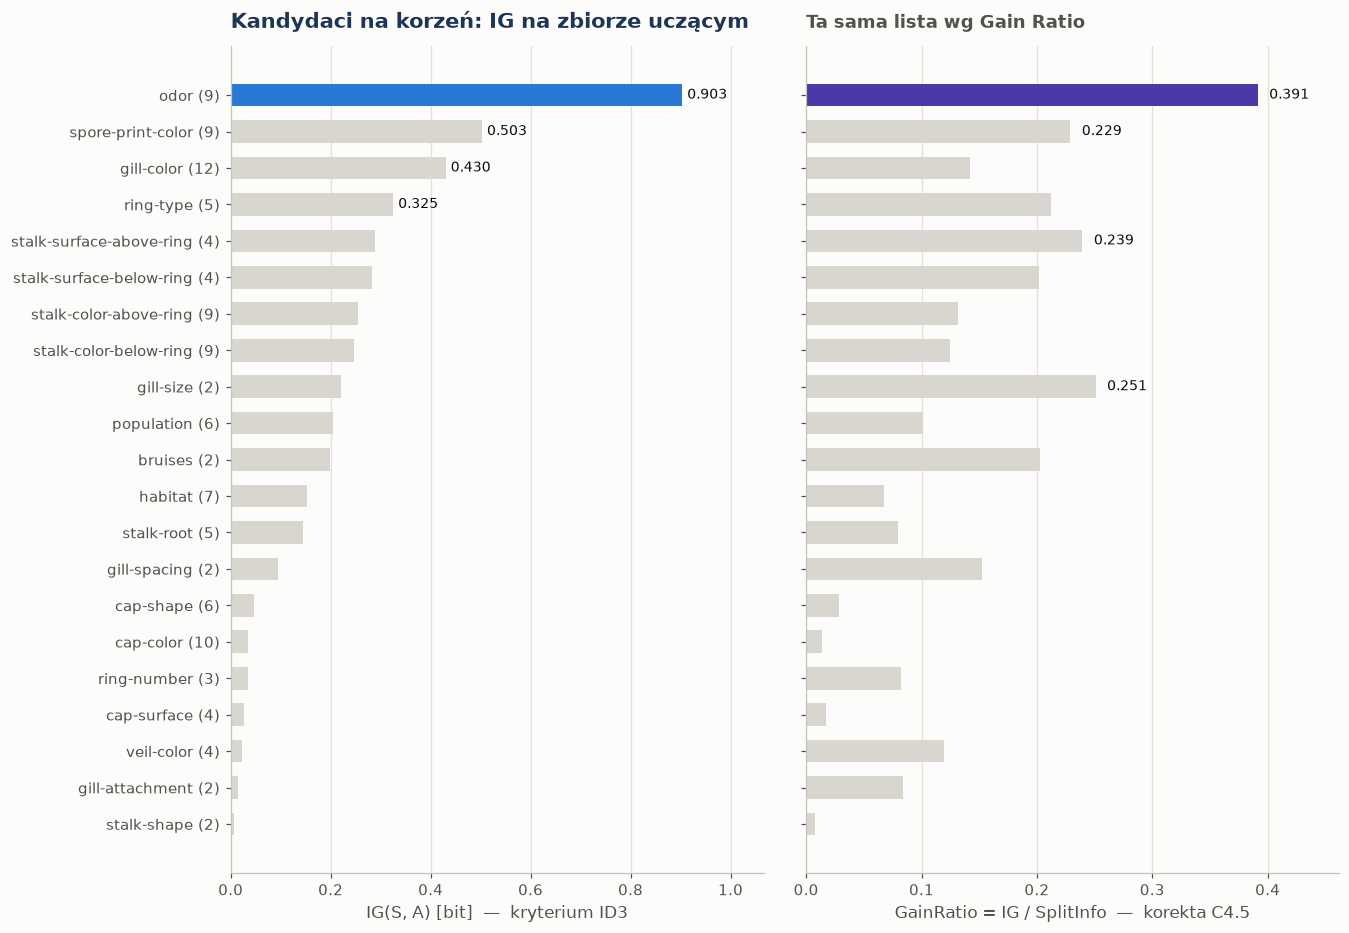

In [27]:
pre_mc = preprocessors["missing_category"]
X_train_mc = pre_mc.transform(X_train)
root_table = information_gain_table(X_train_mc, y_train)
display(root_table.head(8))
show(plot_information_gain_ranking(root_table, "Kandydaci na korzeń: IG na zbiorze uczącym"),
     "05_root_information_gain")
by_gr = root_table.sort_values(["gain_ratio", "feature"], ascending=[False, True]).reset_index(drop=True)
rt = root_table.set_index("feature")
note(ig_root_feature=root_table.iloc[0]["feature"], ig_odor_train=rt.loc["odor", "information_gain"],
     ig_second_feature=root_table.iloc[1]["feature"], ig_second=root_table.iloc[1]["information_gain"],
     ig_third_feature=root_table.iloc[2]["feature"], ig_third=root_table.iloc[2]["information_gain"],
     gr_first=by_gr.iloc[0]["feature"], gr_second=by_gr.iloc[1]["feature"],
     gr_second_value=by_gr.iloc[1]["gain_ratio"], gr_gill_size_ig_rank=int(rt.loc["gill-size", "rank"]),
     gill_size_values=int(rt.loc["gill-size", "n_values"]))

,kategoria,n,n_e,n_p,entropy,weight,weighted_entropy
0,almond (a),247,247,0,0.000000,0.050677,0.000000
1,creosote (c),107,0,107,0.000000,0.021953,0.000000
2,foul (f),1326,0,1326,0.000000,0.272056,0.000000
3,anise (l),248,248,0,0.000000,0.050882,0.000000
4,musty (m),20,0,20,0.000000,0.004103,0.000000
5,none (n),2104,2029,75,0.221962,0.431678,0.095816
6,pungent (p),140,0,140,0.000000,0.028724,0.000000
7,spicy (s),328,0,328,0.000000,0.067296,0.000000
8,fishy (y),354,0,354,0.000000,0.072630,0.000000


IG(S, odor) = H(S) − Σ |S_v|/|S|·H(S_v) = 0.9991 − 0.0958 = 0.9033 bita


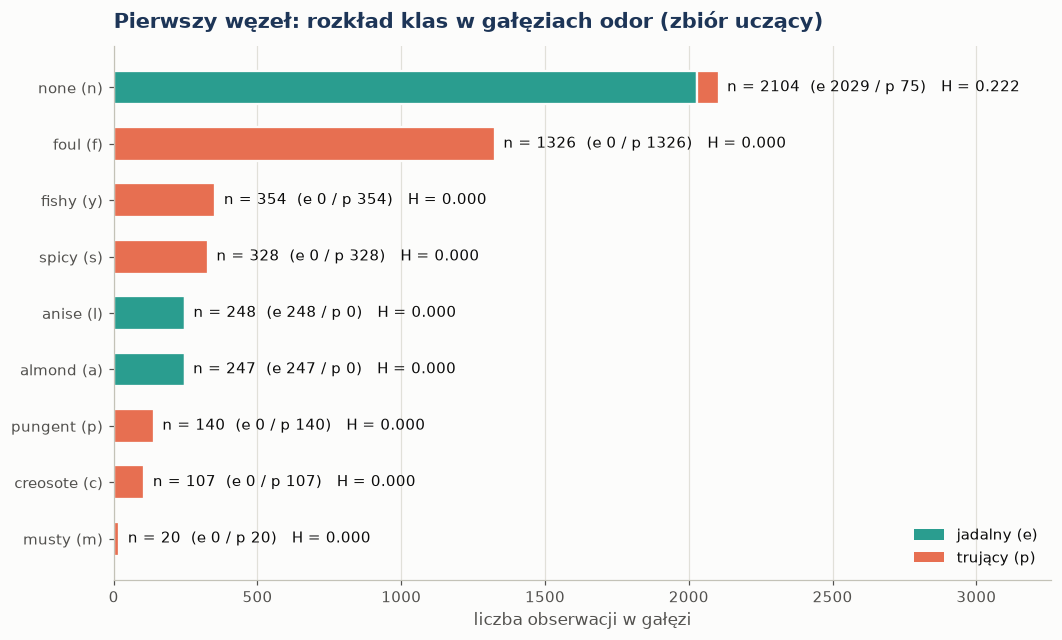

In [28]:
odor_terms = gain_breakdown(X_train_mc["odor"], y_train)
odor_terms.insert(0, "kategoria", [expand_value("odor", v) for v in odor_terms["value"]])
display(odor_terms.drop(columns="value"))
H_train = entropy(y_train)
remainder = odor_terms["weighted_entropy"].sum()
print(f"IG(S, odor) = H(S) − Σ |S_v|/|S|·H(S_v) = {H_train:.4f} − {remainder:.4f} = {H_train - remainder:.4f} bita")
show(plot_root_split(X_train_mc, y_train, "odor", "Pierwszy węzeł: rozkład klas w gałęziach odor (zbiór uczący)"),
     "05_root_split_odor")
none_row = odor_terms.set_index("value").loc["n"]
note(H_train=H_train, odor_remainder=remainder, n_odor_branches=len(odor_terms),
     n_odor_pure=int((odor_terms["entropy"] == 0).sum()), odor_none_n=int(none_row["n"]),
     odor_none_p=int(none_row["n_p"]), odor_none_H=float(none_row["entropy"]),
     odor_none_weight=float(none_row["weight"]))

**Interpretacja.** Na zbiorze uczącym $H(S)$ = 0.9991, a ważona entropia gałęzi `odor` to tylko
0.0958. Daje to $IG$ = 0.9033 bita, wyraźnie więcej niż u kolejnych kandydatów:
`spore-print-color` (0.503) i `gill-color` (0.430). Z 9
gałęzi 8 jest od razu czystych i staje się liśćmi. Całą pozostałą niepewność niesie gałąź `none`:
$n$ = 2104, w tym 75 trujących, $H$ = 0.222, waga 43.2%.

Ranking **Gain Ratio** (prawy panel) też stawia na czele `odor`, ale na drugie miejsce awansuje
`gill-size` (0.251). To cecha o 2 wartościach, która według IG zajmuje
dopiero 9. pozycję. Tak w praktyce wygląda korekta preferencji IG wobec atrybutów
wielowartościowych. Kryterium ID3 pozostaje jednak IG.

## 5.2. Wyniki testów
Pełny zestaw testów (`pytest`) znajduje się w katalogu `tests/` i jest raportowany w `outputs/QA_REPORT.md`.
Poniżej najpierw wbudowane kontrole działające także w Colab, a potem, jeśli folder `tests/` jest dostępny,
wynik rzeczywistego uruchomienia testów matematycznych i testów modelu.

In [29]:
rng = np.random.default_rng(0)
random_pairs = [(rng.integers(0, 4, 60).astype(str), rng.integers(0, 2, 60).astype(str)) for _ in range(200)]


def raises_value_error(action) -> bool:
    try:
        action()
    except ValueError:
        return True
    return False


probe_model = ID3Classifier().fit(X_train_mc, y_train)
unseen_sample = X_train_mc.iloc[0].copy()
unseen_sample["odor"] = "q"                                   # kategoria spoza słownika i treningu
root_path_ok = all(len({f for f, _ in path}) == len(path) for path in probe_model.node_paths().values())
checks = pd.DataFrame([
    ("H([]) = 0 (udokumentowana konwencja)", entropy([]) == 0.0),
    ("H(['e', 'e', 'e']) = 0", entropy(["e", "e", "e"]) == 0.0),
    ("H(['e', 'p']) = 1 bit", entropy(["e", "p"]) == 1.0),
    ("0·log2(0) := 0 bez wywołania log2(0)", entropy_from_counts([5, 0, 0]) == 0.0),
    ("IG podziału idealnego = H(rodzica)", abs(information_gain(["a", "a", "b"], ["e", "e", "p"]) - entropy(["e", "e", "p"])) < 1e-12),
    ("0 ≤ IG ≤ H(S) na 200 losowych próbach",
     all(-1e-12 <= information_gain(x, t) <= entropy(t) + 1e-12 for x, t in random_pairs)),
    ("IG(odor) = I(odor; klasa) ze scikit-learn",
     abs(information_gain(X_all["odor"], y_all) - association.set_index("cecha").loc["odor", "I(A;Y) [bit]"]) < 1e-10),
    ("NaN bez preprocessingu → ValueError", raises_value_error(lambda: ID3Classifier().fit(X_train[["stalk-root"]], y_train))),
    ("nieznana kategoria → klasa większościowa ostatniego węzła",
     probe_model.explain_prediction(unseen_sample).used_fallback
     and probe_model.predict_one(unseen_sample) == probe_model.root_.majority_class),
    ("determinizm: dwa treningi → identyczne drzewo",
     ID3Classifier().fit(X_train_mc, y_train).to_dict() == probe_model.to_dict()),
    ("żaden atrybut nie powtarza się na ścieżce", root_path_ok),
    ("predict_one ≡ predict dla 50 rekordów",
     [probe_model.predict_one(r) for _, r in X_train_mc.head(50).iterrows()] == probe_model.predict(X_train_mc.head(50)).tolist()),
], columns=["kontrola", "wynik"])
checks["wynik"] = checks["wynik"].map({True: "✅ OK", False: "❌ BŁĄD"})
display(checks)
assert (checks["wynik"] == "✅ OK").all(), "wbudowane kontrole nie przeszły"
note(n_inline_checks=len(checks))

tests_dir = PROJECT_ROOT / "tests"
if tests_dir.is_dir() and importlib.util.find_spec("pytest") is not None:
    completed = subprocess.run(
        [sys.executable, "-m", "pytest", "-q", "--color=no", "-p", "no:cacheprovider", "tests/test_entropy.py",
         "tests/test_information_gain.py", "tests/test_id3.py"],
        cwd=PROJECT_ROOT, capture_output=True, text=True, env={**os.environ, "ID3_QA_SKIP_REPORT": "1"})
    print("pytest (testy matematyczne i modelu):", completed.stdout.strip().splitlines()[-1])
    assert completed.returncode == 0, completed.stdout[-2000:]
else:
    print("Folder tests/ niedostępny (np. Google Colab) — pełne wyniki: outputs/QA_REPORT.md w paczce projektu.")

,kontrola,wynik
0,H([]) = 0 (udokumentowana konwencja),✅ OK
1,"H(['e', 'e', 'e']) = 0",✅ OK
2,"H(['e', 'p']) = 1 bit",✅ OK
3,0·log2(0) := 0 bez wywołania log2(0),✅ OK
4,IG podziału idealnego = H(rodzica),✅ OK
5,0 ≤ IG ≤ H(S) na 200 losowych próbach,✅ OK
6,IG(odor) = I(odor; klasa) ze scikit-learn,✅ OK
7,NaN bez preprocessingu → ValueError,✅ OK
8,nieznana kategoria → klasa większościowa ostatniego węzła,✅ OK
9,determinizm: dwa treningi → identyczne drzewo,✅ OK


pytest (testy matematyczne i modelu): 49 passed in 3.10s


**Interpretacja.** Wszystkie 12 wbudowanych kontroli przechodzi:

- własności entropii i IG są zachowane, w tym obsługa $0\log_2 0$;
- IG zgadza się z niezależną informacją wzajemną ze scikit-learn;
- braki danych bez preprocessingu kończą się czytelnym `ValueError`;
- nieznana kategoria przechodzi na klasę większościową węzła;
- drzewo jest deterministyczne i nie powtarza atrybutów na ścieżce.

Pełny zestaw testów obejmuje także warunki stopu, schemat danych, pipeline, protokół walidacji, wykresy,
notebook i warsztat.

<a id="rozdzial-06"></a>
# 06. Strojenie: modele próbne i dobór parametrów

## 6.1. Protokół
Każdą z **36 konfiguracji** (3 strategie braków × 3 wartości `max_depth` × 2 × 2) trenujemy na tym samym zbiorze
uczącym i oceniamy na tym samym zbiorze walidacyjnym. Funkcje strojenia (`run_experiment_grid`, `depth_curve`,
`rank_configurations`) nie mają argumentu, przez który mógłby trafić do nich zbiór testowy. Test
`tests/test_experiments.py` sprawdza dodatkowo, że celowe zepsucie etykiet testowych nie zmienia ani jednego wyniku.

| Oś | Wartości | Rola |
|---|---|---|
| strategia braków | `missing_category`, `most_frequent`, `drop_stalk_root` | sposób traktowania `stalk-root` |
| `max_depth` | 2, 4, `None` | 2: niedouczenie, 4: strefa przejściowa, `None`: pełny wzrost |
| `min_samples_split` | 2, 20 | minimalna liczność węzła do podziału |
| `min_information_gain` | 0.0, 0.01 | minimalny przyrost informacji podziału |

**Reguła wyboru została zakodowana przed obejrzeniem wyników** (`SELECTION_RULE` w module `experiments`). Jest
leksykograficzna, bo na Mushroom wiele modeli remisuje przy 100% trafności walidacyjnej:

In [30]:
display(selection_rule_frame())

,poziom,kolumna,kierunek
0,1. min. liczba błędów krytycznych p → e (walidacja),val_p_to_e,rosnąco
1,2. maks. macro-F1 (walidacja),val_macro_f1,malejąco
2,3. min. liczba liści,leaf_count,rosnąco
3,4. min. liczba węzłów,node_count,rosnąco
4,5. min. rzeczywista głębokość drzewa,depth,rosnąco
5,6a. strategia: missing_category > most_frequent > drop_stalk_root,strategy_rank,rosnąco
6,6b. mniejsze max_depth (None = ∞),max_depth_rank,rosnąco
7,6c. większe min_samples_split (ostrożniejszy wzrost),min_samples_split,malejąco
8,6d. większe min_information_gain (ostrożniejszy wzrost),min_information_gain,malejąco
9,6e. identyfikator konfiguracji (porządek całkowity),config_id,rosnąco


Poziomy 6c–6e rozszerzają regułę ze specyfikacji do porządku całkowitego. Przy identycznym drzewie i metrykach
wybieramy najbardziej zachowawcze ograniczenia wzrostu. To ta sama zasada, co preferencja mniejszego `max_depth`:
walidacja nie daje żadnego argumentu za swobodniejszym wzrostem.

> **„(Nie ??? w przypadku lasów)”: przycinanie a lasy losowe.** W lesie losowym (Breiman, 2001) każde drzewo rośnie
> **bez przycinania** na próbie bootstrapowej, z losowym podzbiorem cech w węzłach. Pojedyncze drzewa mają małe
> obciążenie i dużą wariancję, a głosowanie wielu słabo skorelowanych drzew tę wariancję redukuje. Do oceny
> wystarcza estymacja **out-of-bag (OOB)** na obserwacjach niewylosowanych do danej próby. Pojedyncze drzewo ID3 nie
> ma takiego mechanizmu, więc jego wariancję kontrolujemy bezpośrednio: ograniczamy wzrost (`max_depth`,
> `min_samples_split`, `min_information_gain`, czyli *pre-pruning*) i dobieramy te ograniczenia na **wydzielonym
> zbiorze walidacyjnym**, bo naturalnego odpowiednika OOB tu nie ma.

## 6.2. Wyniki 36 modeli próbnych

In [31]:
results = run_experiment_grid(X_train, y_train, X_val, y_val)      # zbiór testowy nie jest argumentem
results.to_csv(OUTPUT_DIR / "experiment_results.csv", index=False)
ranked = rank_configurations(results)
best_config = select_best_configuration(results)
top10 = ranked.head(10)[["rank", "config_id", "strategy", "max_depth_label", "min_samples_split",
                         "min_information_gain", "train_accuracy", "val_accuracy", "val_macro_f1",
                         "val_recall_p", "val_p_to_e", "leaf_count", "node_count", "depth", "fit_time_ms"]]
display(top10.round({"train_accuracy": 4, "val_accuracy": 4, "val_macro_f1": 4, "val_recall_p": 4,
                     "fit_time_ms": 1}).set_index("rank"))
summary36 = (results.groupby(["strategy", "max_depth_label"], sort=False)
             .agg(konfiguracje=("config_id", "size"), val_accuracy=("val_accuracy", "mean"),
                  val_p_to_e=("val_p_to_e", "max"), liście=("leaf_count", "mean"),
                  różne_drzewa=("tree_signature", "nunique")))
display(summary36)
perfect = results[results["val_accuracy"] == 1.0]
shallow = results[results["max_depth_label"] == "2"]
note(n_configs=len(results), n_perfect=len(perfect), n_shallow=len(shallow),
     shallow_acc=float(shallow["val_accuracy"].iloc[0]), shallow_p_to_e=int(shallow["val_p_to_e"].iloc[0]),
     shallow_leaves=int(shallow["leaf_count"].iloc[0]), n_signatures=int(results["tree_signature"].nunique()),
     perfect_leaves=int(perfect["leaf_count"].iloc[0]), perfect_nodes=int(perfect["node_count"].iloc[0]),
     perfect_depth=int(perfect["depth"].iloc[0]))

,config_id,strategy,max_depth_label,min_samples_split,min_information_gain,train_accuracy,val_accuracy,val_macro_f1,val_recall_p,val_p_to_e,leaf_count,node_count,depth,fit_time_ms
rank,,,,,,,,,,,,,,
1,C08,missing_category,4,20,0.01,1.0,1.0,1.0,1.0,0,24,29,4,38.7
2,C07,missing_category,4,20,0.00,1.0,1.0,1.0,1.0,0,24,29,4,36.3
3,C06,missing_category,4,2,0.01,1.0,1.0,1.0,1.0,0,24,29,4,36.3
4,C05,missing_category,4,2,0.00,1.0,1.0,1.0,1.0,0,24,29,4,37.3
5,C12,missing_category,None,20,0.01,1.0,1.0,1.0,1.0,0,24,29,4,36.9
6,C11,missing_category,None,20,0.00,1.0,1.0,1.0,1.0,0,24,29,4,36.3
7,C10,missing_category,None,2,0.01,1.0,1.0,1.0,1.0,0,24,29,4,37.6
8,C09,missing_category,None,2,0.00,1.0,1.0,1.0,1.0,0,24,29,4,36.9
9,C20,most_frequent,4,20,0.01,1.0,1.0,1.0,1.0,0,24,29,4,36.3


konfiguracje  val_accuracy  val_p_to_e  liście  różne_drzewa
strategy         max_depth_label                                                              
missing_category 2                           4      0.994462           9    16.0             1
                 4                           4      1.000000           0    24.0             1
                 None                        4      1.000000           0    24.0             1
most_frequent    2                           4      0.994462           9    16.0             1
                 4                           4      1.000000           0    24.0             1
                 None                        4      1.000000           0    24.0             1
drop_stalk_root  2                           4      0.994462           9    16.0             1
                 4                           4      1.000000           0    24.0             1
                 None                        4      1.000000           0    24.0             1

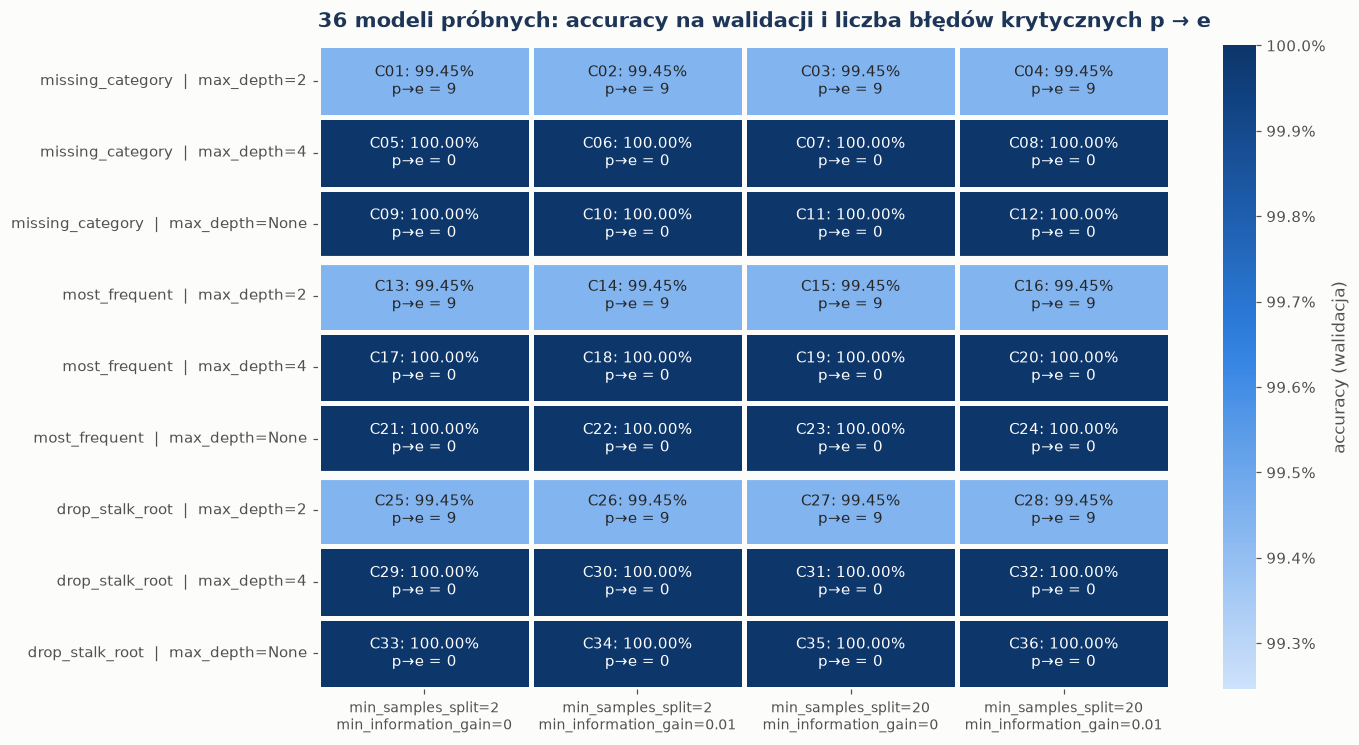

In [32]:
show(plot_experiment_heatmap(results), "06_experiment_heatmap")

**Interpretacja.**

- O jakości decyduje **wyłącznie `max_depth`**. Wszystkie 12 konfiguracji z `max_depth=2` mają
  99.45% trafności i 9 błędów krytycznych `p → e`: drzewo o 16 liściach
  jest niedouczone.
- Pozostałe konfiguracje (`max_depth` 4 lub `None`, łącznie 24) osiągają 100%.
- Progi `min_samples_split` i `min_information_gain` niczego nie zmieniają: na Mushroom podziały są albo bardzo
  informatywne, albo w ogóle niepotrzebne.
- Strategia braków też nie zmienia wyników. Wszystkie 36 modeli to tylko 2 różne drzewa;
  sygnatura struktury jest liczona z atrybutów, gałęzi i klas liści.

## 6.3. Krzywa walidacyjna dla `max_depth` = 1…6, `None`
Pozostałe parametry mają wartości domyślne (`min_samples_split=2`, `min_information_gain=0`). Krzywą liczymy dla
każdej strategii braków.

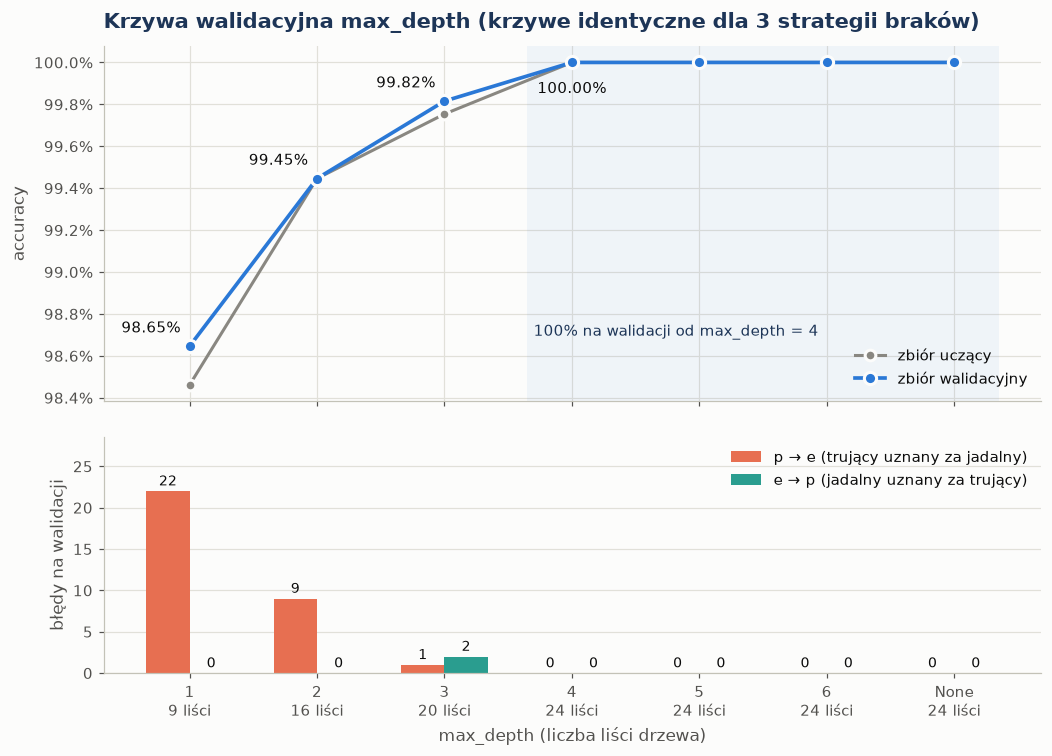

,train_accuracy,val_accuracy,val_macro_f1,val_p_to_e,val_e_to_p,depth,leaf_count,node_count
max_depth_label,,,,,,,,
1,0.984612,0.986462,0.986428,22,0,1,9,10
2,0.994460,0.994462,0.994452,9,0,2,16,18
3,0.997538,0.998154,0.998151,1,2,3,20,23
4,1.000000,1.000000,1.000000,0,0,4,24,29
5,1.000000,1.000000,1.000000,0,0,4,24,29
6,1.000000,1.000000,1.000000,0,0,4,24,29
None,1.000000,1.000000,1.000000,0,0,4,24,29


In [33]:
curve = depth_curve(X_train, y_train, X_val, y_val)
identical_curves = bool(curve.groupby("max_depth_label")["tree_signature"].nunique().eq(1).all())
show(plot_depth_curve(curve, "missing_category", identical_curves), "06_depth_curve")
mc_curve = curve[curve["strategy"] == "missing_category"].set_index("max_depth_label")
display(mc_curve[["train_accuracy", "val_accuracy", "val_macro_f1", "val_p_to_e", "val_e_to_p", "depth",
                  "leaf_count", "node_count"]])
first_perfect = mc_curve.index[mc_curve["val_accuracy"] >= 1.0][0]
note(curves_identical=identical_curves, d1_acc=mc_curve.loc["1", "val_accuracy"],
     d1_p_to_e=int(mc_curve.loc["1", "val_p_to_e"]), d2_acc=mc_curve.loc["2", "val_accuracy"],
     d2_p_to_e=int(mc_curve.loc["2", "val_p_to_e"]), d3_acc=mc_curve.loc["3", "val_accuracy"],
     d3_p_to_e=int(mc_curve.loc["3", "val_p_to_e"]), d3_e_to_p=int(mc_curve.loc["3", "val_e_to_p"]),
     first_perfect_depth=first_perfect, full_depth=int(mc_curve.loc["None", "depth"]),
     d1_train_acc=mc_curve.loc["1", "train_accuracy"])

**Interpretacja.**

| `max_depth` | Drzewo | Trafność walidacyjna | Błędy |
|---|---|---|---|
| 1 | sam `odor` | 98.65% | 22 × `p → e`: trujące z zapachem `none` uznane za jadalne |
| 2 | + `spore-print-color` | 99.45% | 9 × `p → e` |
| 3 | | 99.82% | 1 × `p → e`, 2 × `e → p` |
| od 4 | pełne drzewo | 100% | brak |

Głębszy limit nic nie zmienia, bo nieograniczone drzewo kończy się naturalnie na głębokości 4.
Krzywe uczenia i walidacji idą razem (przy `max_depth=1` walidacja ma nawet 98.65% wobec
98.46% na treningu). Nie ma więc **przeuczenia**, jest tylko **niedouczenie** płytkich drzew.
Krzywe są identyczne dla trzech strategii braków.

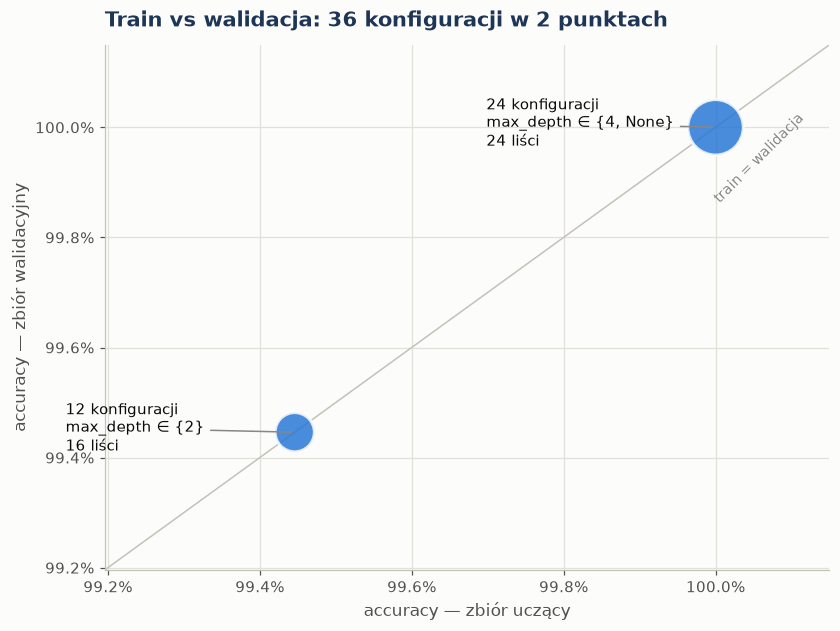

In [34]:
show(plot_train_vs_validation(results), "06_train_vs_validation")

**Interpretacja.** Każdy z 36 punktów leży na przekątnej `train = walidacja` lub tuż przy niej. Model
z mniejszą liczbą liści przegrywa jednakowo na obu zbiorach, czyli brakuje mu pojemności, a nie zdolności
uogólniania. To typowy obraz zbioru, który jest **deterministycznie separowalny**: wystarczająco głębokie drzewo
odtwarza regułę generującą etykiety.

## 6.4. Porównanie strategii braków: dlaczego wyniki są identyczne?

,node,n,winner,winner_gain,gain_missing_category,rank_missing_category,winner_missing_category,gain_most_frequent,rank_most_frequent,winner_most_frequent
0,korzeń,4874,odor,0.903264,0.144560,13,odor,0.117073,13,odor
1,głęb. 1: odor = none (n),2104,spore-print-color,0.156312,0.023128,12,spore-print-color,0.023094,12,spore-print-color
2,głęb. 2: spore-print-color = white (w),358,habitat,0.269540,0.043590,13,habitat,0.042831,13,habitat
3,głęb. 3: habitat = woods (d),21,gill-size,0.591673,0.591673,6,gill-size,0.000000,18,gill-size
4,głęb. 3: habitat = leaves (l),36,cap-color,0.811278,0.255489,11,cap-color,0.255489,11,cap-color


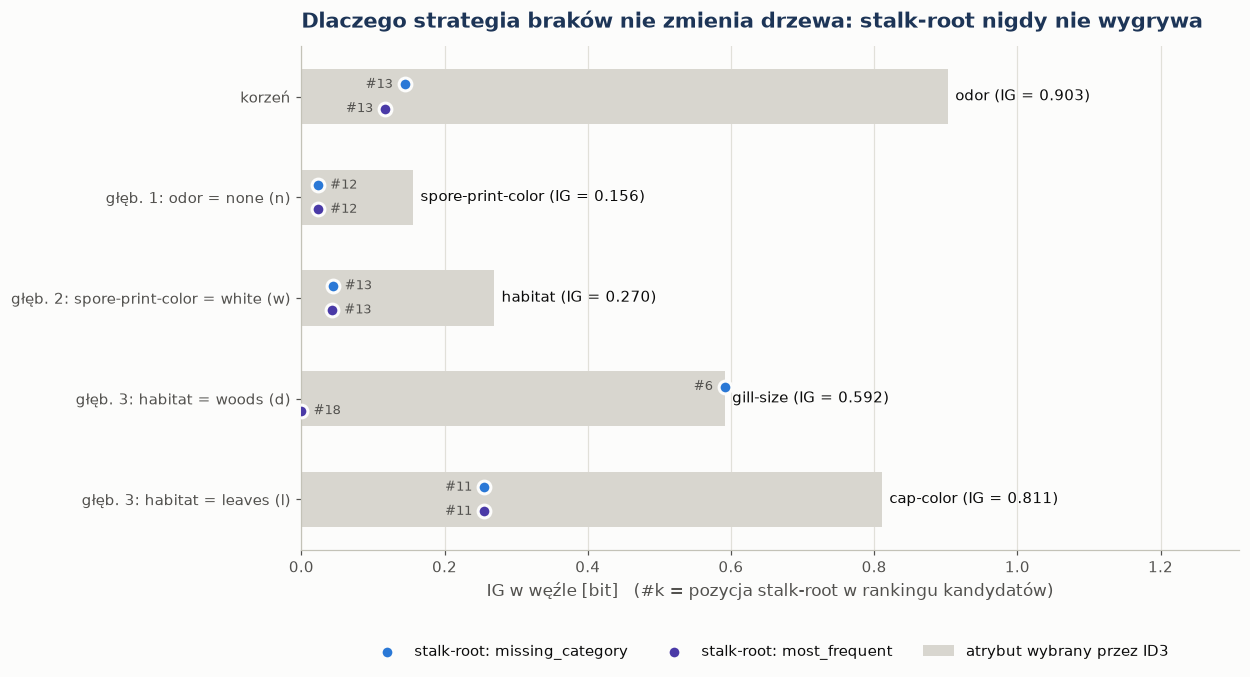

,węzeł,n,wybrany atrybut,IG,remisujące atrybuty,liczba remisujących
0,0,4874,odor,0.9033,odor,1
1,6,2104,spore-print-color,0.1563,spore-print-color,1
2,13,358,habitat,0.2695,habitat,1
3,14,21,gill-size,0.5917,"gill-size, population, ring-number, ring-type, stalk-color-above-ring, stalk-root, stalk-surface-above-ring",7
4,18,36,cap-color,0.8113,"cap-color, population, stalk-color-below-ring",3


In [35]:
signatures = results.pivot_table(index=["max_depth_label", "min_samples_split", "min_information_gain"],
                                 columns="strategy", values="tree_signature", aggfunc="first")
strategies_identical = bool((signatures.nunique(axis=1) == 1).all())
reference_model = ID3Classifier(class_priority=SAFETY_CLASS_PRIORITY).fit(X_train_mc, y_train)
gain_report = feature_gain_report(X_train, y_train, reference_model)
display(gain_report)
show(plot_strategy_gains(gain_report), "06_strategy_comparison")

tie_rows = []
for node in reference_model.iter_nodes():
    if not node.is_leaf:
        tied = sorted(f for f, g in node.candidate_gains.items() if g >= node.information_gain - GAIN_TOLERANCE)
        tie_rows.append({"węzeł": node.node_id, "n": node.n_samples, "wybrany atrybut": node.feature,
                         "IG": round(node.information_gain, 4), "remisujące atrybuty": ", ".join(tied),
                         "liczba remisujących": len(tied)})
ties_in_tree = pd.DataFrame(tie_rows)
display(ties_in_tree)
biggest_tie = ties_in_tree.sort_values("liczba remisujących", ascending=False).iloc[0]
mc_ranks = gain_report["rank_missing_category"]
note(strategies_identical=strategies_identical, stalk_best_rank=int(mc_ranks.min()),
     tie_node_n=int(biggest_tie["n"]), tie_count=int(biggest_tie["liczba remisujących"]),
     tie_gain=float(biggest_tie["IG"]), tie_winner=biggest_tie["wybrany atrybut"],
     tie_features=biggest_tie["remisujące atrybuty"],
     tie_node_label=gain_report.loc[gain_report["n"] == biggest_tie["n"], "node"].iloc[0])

**Interpretacja.** Dla każdej z 12 kombinacji hiperparametrów trzy strategie budują **to samo drzewo**
(`strategies_identical` = True). Powód widać na wykresie: `stalk-root` w żadnym węźle nie
wygrywa. W korzeniu i na dwóch kolejnych poziomach jego IG jest kilkukrotnie mniejszy niż IG atrybutu wybranego,
niezależnie od strategii; jego najlepsza pozycja w rankingu kandydatów to 6. Skoro `stalk-root`
nie jest testowany, jego braki nie mają wpływu na model.

Najciekawszy jest węzeł **głęb. 3: habitat = woods (d)** (21 obserwacji). Tu aż **7 atrybutów**
dzieli węzeł idealnie z identycznym IG = 0.5917: gill-size, population, ring-number, ring-type, stalk-color-above-ring, stalk-root, stalk-surface-above-ring. W wariancie `missing_category` jest
wśród nich `stalk-root` (kategoria `__MISSING__` pokrywa się tu z grzybami trującymi). O wyborze `gill-size`
przesądziła wyłącznie **deterministyczna reguła remisów** (alfabetycznie). Reguła remisów nie jest więc detalem
kosmetycznym, bo inna kolejność dałaby inne, choć równie trafne drzewo. Przy równych wynikach preferujemy
`missing_category`. Zachowuje pełną informację, także o samym fakcie braku, który według 3.2 jest skorelowany
z klasą, i nie wymaga zgadywania wartości.

## 6.5. Remisy i wybór konfiguracji finalnej

In [36]:
ties = metric_tie_groups(ranked)
display(ties)
winner = ranked.iloc[0]
display(winner[["config_id", "strategy", "max_depth_label", "min_samples_split", "min_information_gain",
                "val_accuracy", "val_macro_f1", "val_p_to_e", "leaf_count", "node_count", "depth"]].to_frame("wybrana"))
note(selected_config=best_config.config_id, selected_strategy=best_config.strategy,
     selected_max_depth=depth_label(best_config.max_depth), selected_min_split=best_config.min_samples_split,
     selected_min_ig=best_config.min_information_gain, top_group_size=int(ties.iloc[0]["liczba konfiguracji"]),
     top_group_trees=int(ties.iloc[0]["różne drzewa"]), selected_val_acc=float(winner["val_accuracy"]),
     selected_leaves=int(winner["leaf_count"]), selected_signature=winner["tree_signature"])

,najlepsza pozycja,liczba konfiguracji,konfiguracje,p → e,macro-F1,liście,węzły,głębokość,różne drzewa
0,1,24,"C08, C07, C06, C05, C12, C11, C10, C09, C20, C19, C18, C17, C24, C23, C22, C21, C32, C31, C30, C29, C36, C...",0,1.000000,24,29,4,1
1,25,12,"C04, C03, C02, C01, C16, C15, C14, C13, C28, C27, C26, C25",9,0.994452,16,18,2,1


,wybrana
config_id,C08
strategy,missing_category
max_depth_label,4
min_samples_split,20
min_information_gain,0.01
val_accuracy,1.0
val_macro_f1,1.0
val_p_to_e,0
leaf_count,24
node_count,29


**Wybór: `C08`** (`strategy=missing_category`, `max_depth=4`,
`min_samples_split=20`, `min_information_gain=0.01`). Rozstrzygnięcie
przebiegło tak:

- Poziomy 1–5 reguły (0 błędów `p → e`, macro-F1 = 1, 24 liście, 29 węzłów,
  głębokość 4) remisują dla **24 konfiguracji**. Wszystkie budują to samo drzewo
  (różnych drzew: 1).
- Poziom 6a wybrał `missing_category`, 6b mniejsze `max_depth = 4` zamiast `None`, a 6c–6d silniejsze progi
  `min_samples_split` i `min_information_gain`.

Wybór nie poprawia trafności, bo wszystkie zwycięskie konfiguracje są równoważne. Daje jednoznaczny, opisany
z góry i powtarzalny model.

> Zero błędów `p → e` na tym zbiorze **nie oznacza** bezpieczeństwa grzybobrania. Oznacza tylko, że drzewo
> odtwarza regułę, według której przewodnik przypisał etykiety 23 gatunkom.

<a id="rozdzial-07"></a>
# 07. Budowa modelu finalnego

Zgodnie z protokołem łączymy zbiór uczący i walidacyjny (60% + 20%). Na połączonych danych **od nowa**
dopasowujemy preprocessing, czyli cechy stałe i kategorie, a potem od podstaw trenujemy ID3 w wybranej
konfiguracji. Zbiór testowy pozostaje zapieczętowany.

In [37]:
train_val_idx = split.train_validation()
X_trval, y_trval = X_all.loc[train_val_idx], y_all.loc[train_val_idx]
final_pre, final_model = fit_final_model(X_trval, y_trval, best_config)
summary = final_model.summary()
display(pd.DataFrame({"wartość": {
    "konfiguracja": best_config.label(), "obserwacje (train+val)": summary["n_samples_fit"],
    "cechy wejściowe": summary["n_features_in"], "węzły": summary["node_count"], "liście": summary["leaf_count"],
    "głębokość": summary["depth"], "użyte atrybuty": ", ".join(summary["used_features"]),
    "remis klas w liściu → klasa": final_model.class_priority[0], "test": repr(test_vault)}}))
final_model.save_json(MODEL_DIR / "final_tree.json")
final_config = {
    "selected_configuration": best_config.__dict__, "selection_rule": [r[2] for r in SELECTION_RULE],
    "preprocessing": final_pre.summary(), "split": {"random_state": split.random_state, "train": len(split.train),
                                                    "validation": len(split.validation), "test": len(split.test)},
    "tree": {k: summary[k] for k in ("node_count", "leaf_count", "depth", "used_features")},
    "data": {"source": UCI_DATASET_URL, "doi": UCI_DOI, "sha256": file_sha256(DATA_ZIP)},
    "environment": ENVIRONMENT,
}
(MODEL_DIR / "final_config.json").write_text(json.dumps(final_config, indent=2, ensure_ascii=False, default=str),
                                            encoding="utf-8")
assert ID3Classifier.load_json(MODEL_DIR / "final_tree.json").structure_signature() == final_model.structure_signature()
importance = final_model.feature_importance_
note(final_n=summary["n_samples_fit"], final_nodes=summary["node_count"], final_leaves=summary["leaf_count"],
     final_depth=summary["depth"], final_n_used=len(summary["used_features"]),
     final_used=", ".join(summary["used_features"]), final_root_ig=final_model.root_.information_gain,
     final_same_as_validated=final_model.structure_signature() == winner["tree_signature"],
     imp_first=importance.index[0], imp_first_value=float(importance.iloc[0]),
     imp_second=importance.index[1], imp_second_value=float(importance.iloc[1]),
     final_impure_leaves=sum(1 for n in final_model.iter_nodes() if n.is_leaf and n.entropy > 0),
     importance_bits_total=float(final_model.feature_importance_bits_.sum()),
     H_trval=entropy(y_trval))

,wartość
konfiguracja,missing_category | max_depth=4 | min_samples_split=20 | min_information_gain=0.01
obserwacje (train+val),6499
cechy wejściowe,21
węzły,29
liście,24
głębokość,4
użyte atrybuty,"odor, spore-print-color, habitat, gill-size, cap-color"
remis klas w liściu → klasa,p
test,"HoldoutVault('test', n=1625, zapieczętowany, dostępy=1)"


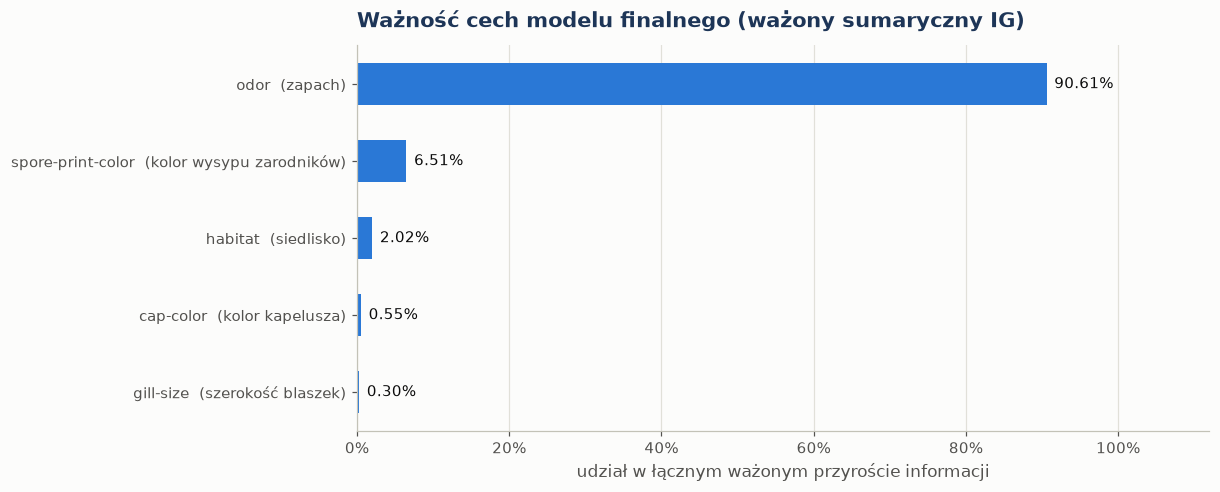

,ważność [%],IG ważony [bit]
odor,90.61,0.9053
spore-print-color,6.51,0.0650
habitat,2.02,0.0202
cap-color,0.55,0.0055
gill-size,0.30,0.0030


Atrybuty o zerowej ważności (nieużyte w drzewie): 16 z 21


In [38]:
show(plot_feature_importance(importance, "Ważność cech modelu finalnego (ważony sumaryczny IG)"),
     "07_feature_importance")
importance_table = pd.DataFrame({"ważność [%]": (importance * 100).round(2),
                                 "IG ważony [bit]": final_model.feature_importance_bits_.round(4)})
display(importance_table[importance_table["ważność [%]"] > 0])
print(f"Atrybuty o zerowej ważności (nieużyte w drzewie): {int((importance == 0).sum())} z {len(importance)}")

**Charakterystyka.** Drzewo finalne wytrenowane na 6499 obserwacjach ma 29 węzłów,
24 liście i głębokość 4. Testuje tylko 5 z 21 atrybutów:
odor, spore-print-color, habitat, gill-size, cap-color. Wszystkie liście są czyste (liście mieszane: 0). Struktura jest identyczna
z drzewem zweryfikowanym na walidacji (porównanie sygnatur struktury: True), więc dołożenie danych walidacyjnych tylko
zagęściło liczności w liściach.

**Ważność cech** definiujemy jako $\mathrm{imp}(A) = \sum_{t:\,A_t = A} \frac{n_t}{N}\, IG(t)$, czyli ważony
przyrost informacji ze wszystkich węzłów testujących $A$, normalizowany do sumy 1. `odor` odpowiada za
90.6% całej redukcji entropii, `spore-print-color` za 6.5%. Suma nieznormalizowanych
ważności (0.9991 bita) równa się entropii zbioru $H$ = 0.9991. Tak musi być, gdy
wszystkie liście są czyste, i jest to dobra kontrola poprawności implementacji.

### Pełna lista reguł (jedna reguła na liść)

In [39]:
for i, rule in enumerate(final_model.rules_text(value_formatter=expand_value), start=1):
    print(f"{i:>2}. {rule}")

 1. JEŻELI odor = almond (a) TO e   [n=318, e=318, p=0]
 2. JEŻELI odor = creosote (c) TO p   [n=154, e=0, p=154]
 3. JEŻELI odor = foul (f) TO p   [n=1754, e=0, p=1754]
 4. JEŻELI odor = anise (l) TO e   [n=319, e=319, p=0]
 5. JEŻELI odor = musty (m) TO p   [n=27, e=0, p=27]
 6. JEŻELI odor = none (n) ORAZ spore-print-color = buff (b) TO e   [n=36, e=36, p=0]
 7. JEŻELI odor = none (n) ORAZ spore-print-color = chocolate (h) TO e   [n=38, e=38, p=0]
 8. JEŻELI odor = none (n) ORAZ spore-print-color = black (k) TO e   [n=1037, e=1037, p=0]
 9. JEŻELI odor = none (n) ORAZ spore-print-color = brown (n) TO e   [n=1079, e=1079, p=0]
10. JEŻELI odor = none (n) ORAZ spore-print-color = orange (o) TO e   [n=37, e=37, p=0]
11. JEŻELI odor = none (n) ORAZ spore-print-color = green (r) TO p   [n=61, e=0, p=61]
12. JEŻELI odor = none (n) ORAZ spore-print-color = white (w) ORAZ habitat = woods (d) ORAZ gill-size = broad (b) TO e   [n=5, e=5, p=0]
13. JEŻELI odor = none (n) ORAZ spore-print-color =

<a id="rozdzial-08"></a>
# 08. Graficzne przedstawienie drzewa

Każdy węzeł pokazuje testowany atrybut (albo klasę liścia), liczbę obserwacji, rozkład klas (liczby i pasek
proporcji) oraz entropię. Krawędzie opisują wartości kategorii z rozwiniętymi nazwami. Widok prezentacyjny łączy
rodzeństwo będące **czystymi liśćmi tej samej klasy** w jedno pole (np. 6 zapachów → trujący). Model się nie
zmienia, a schemat mieści się na ekranie projektora.

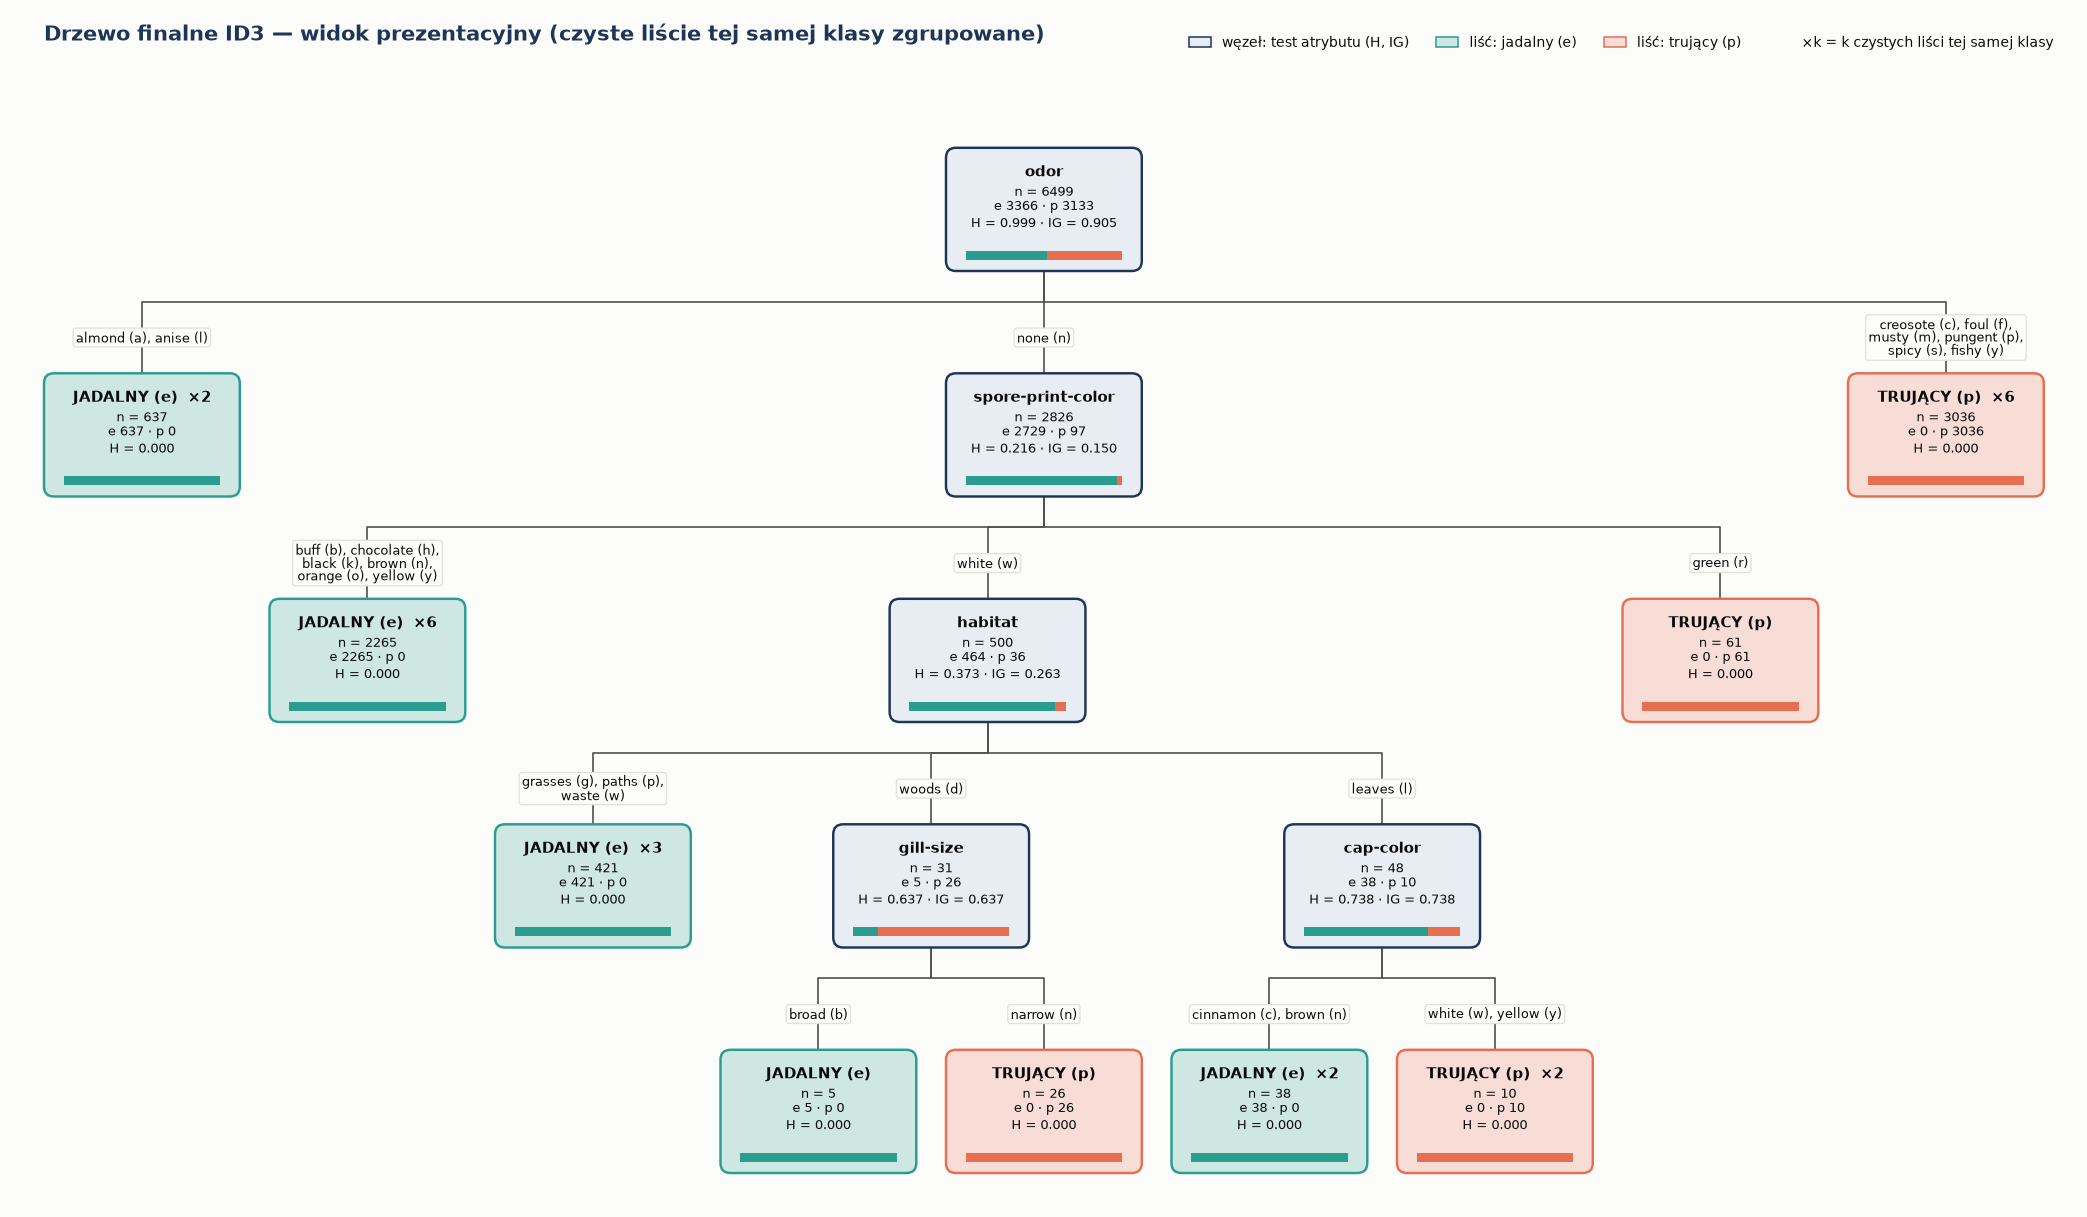

In [40]:
show(plot_tree(final_model, group_pure_leaves=True,
               title="Drzewo finalne ID3 — widok prezentacyjny (czyste liście tej samej klasy zgrupowane)"),
     "08_tree_presentation", formats=("png", "svg"))

**Interpretacja.** Drzewo czyta się jak klucz do oznaczania:

1. Zapach migdałowy lub anyżowy → jadalny; każdy z sześciu nieprzyjemnych zapachów → trujący.
2. Zapach `none` → rozstrzyga kolor wysypu zarodników: zielony → trujący, większość kolorów → jadalny.
3. Biały wysyp → decyduje siedlisko, a w lesie i na liściach jeszcze szerokość blaszek albo kolor kapelusza.

Najrzadsze ścieżki (najmniejsze liście mają 5 obserwacji) obsługują najtrudniejsze przypadki,
które zarazem są najsłabiej udokumentowane w danych.

### Powiększenie: poddrzewo `odor = none (n)`, każda gałąź osobno

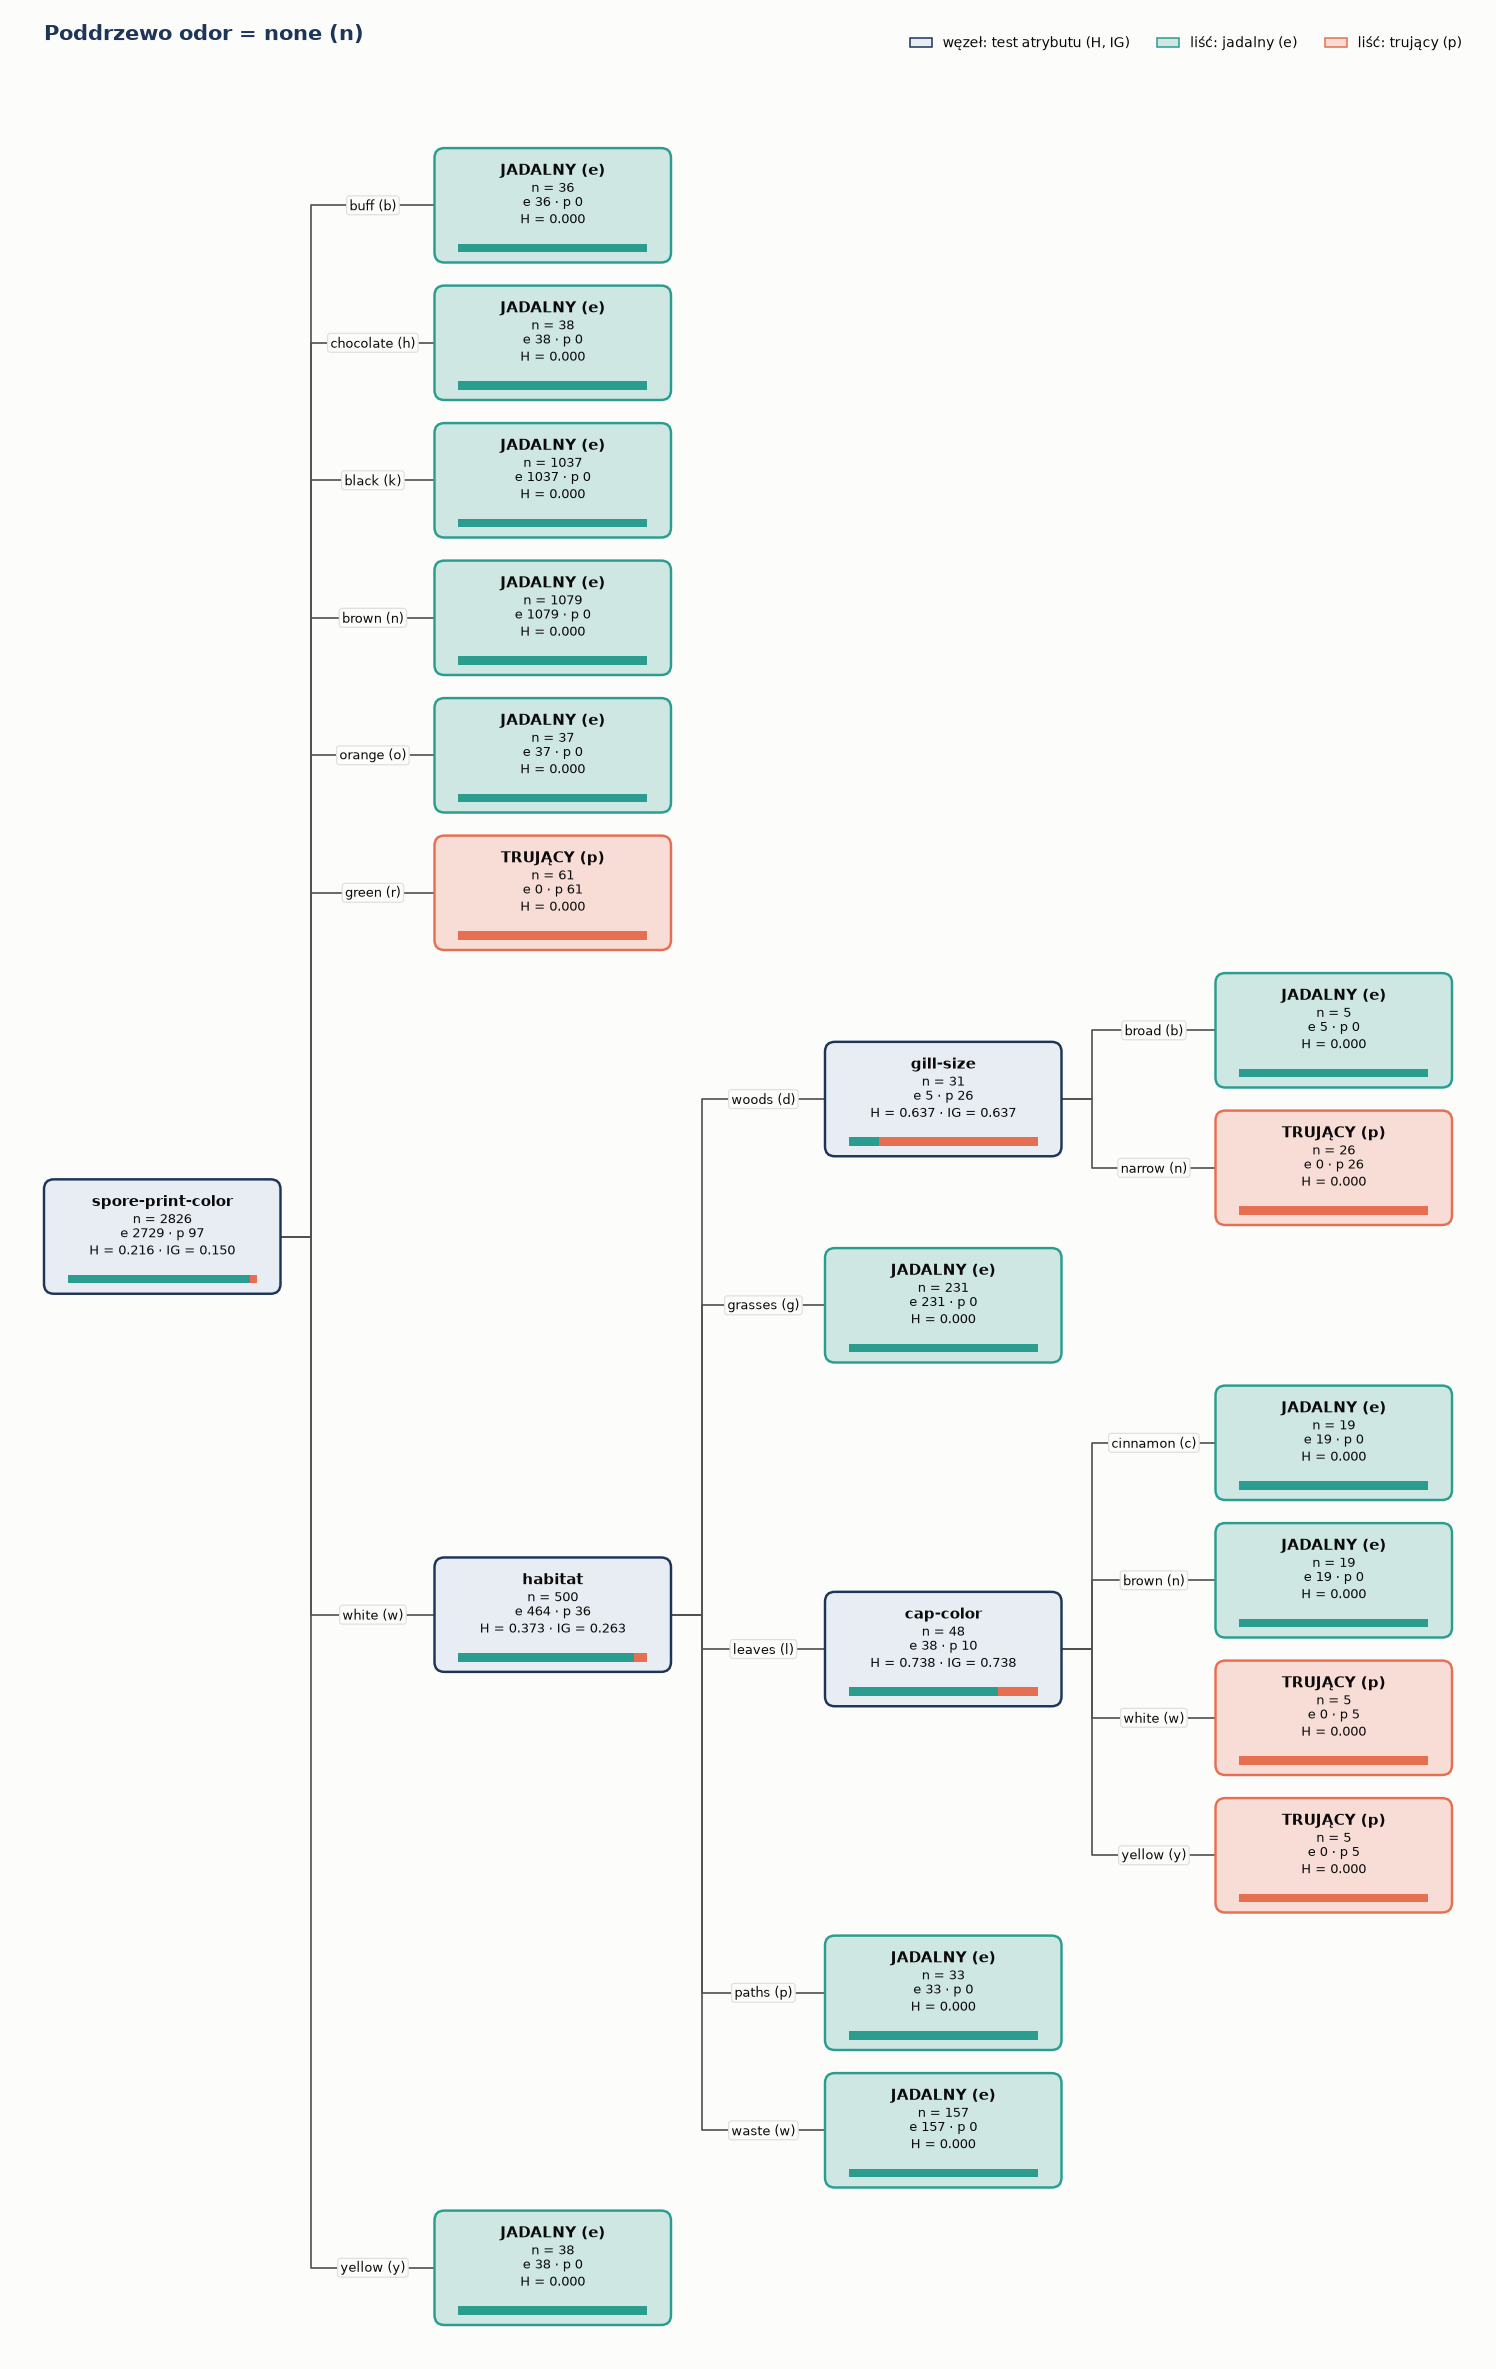

In [41]:
show(plot_tree(final_model, subtree_path=[("odor", "n")], orientation="LR",
               title="Poddrzewo odor = none (n)"),
     "08_tree_odor_none", formats=("png", "svg"))

### Pełne drzewo do pliku: Graphviz (DOT) lub fallback matplotlib
Drzewo zapisujemy w formacie **DOT**. Jeśli w systemie jest program `dot` (Graphviz; w Google Colab jest
preinstalowany), SVG i PNG renderuje Graphviz. W przeciwnym razie `render_tree` automatycznie rysuje ten sam
pełny schemat w matplotlib (układ od lewej do prawej, każda gałąź osobno).

Renderer: matplotlib  ·  pliki: final_tree.svg, final_tree.png  ·  DOT: outputs/final_model/final_tree.dot


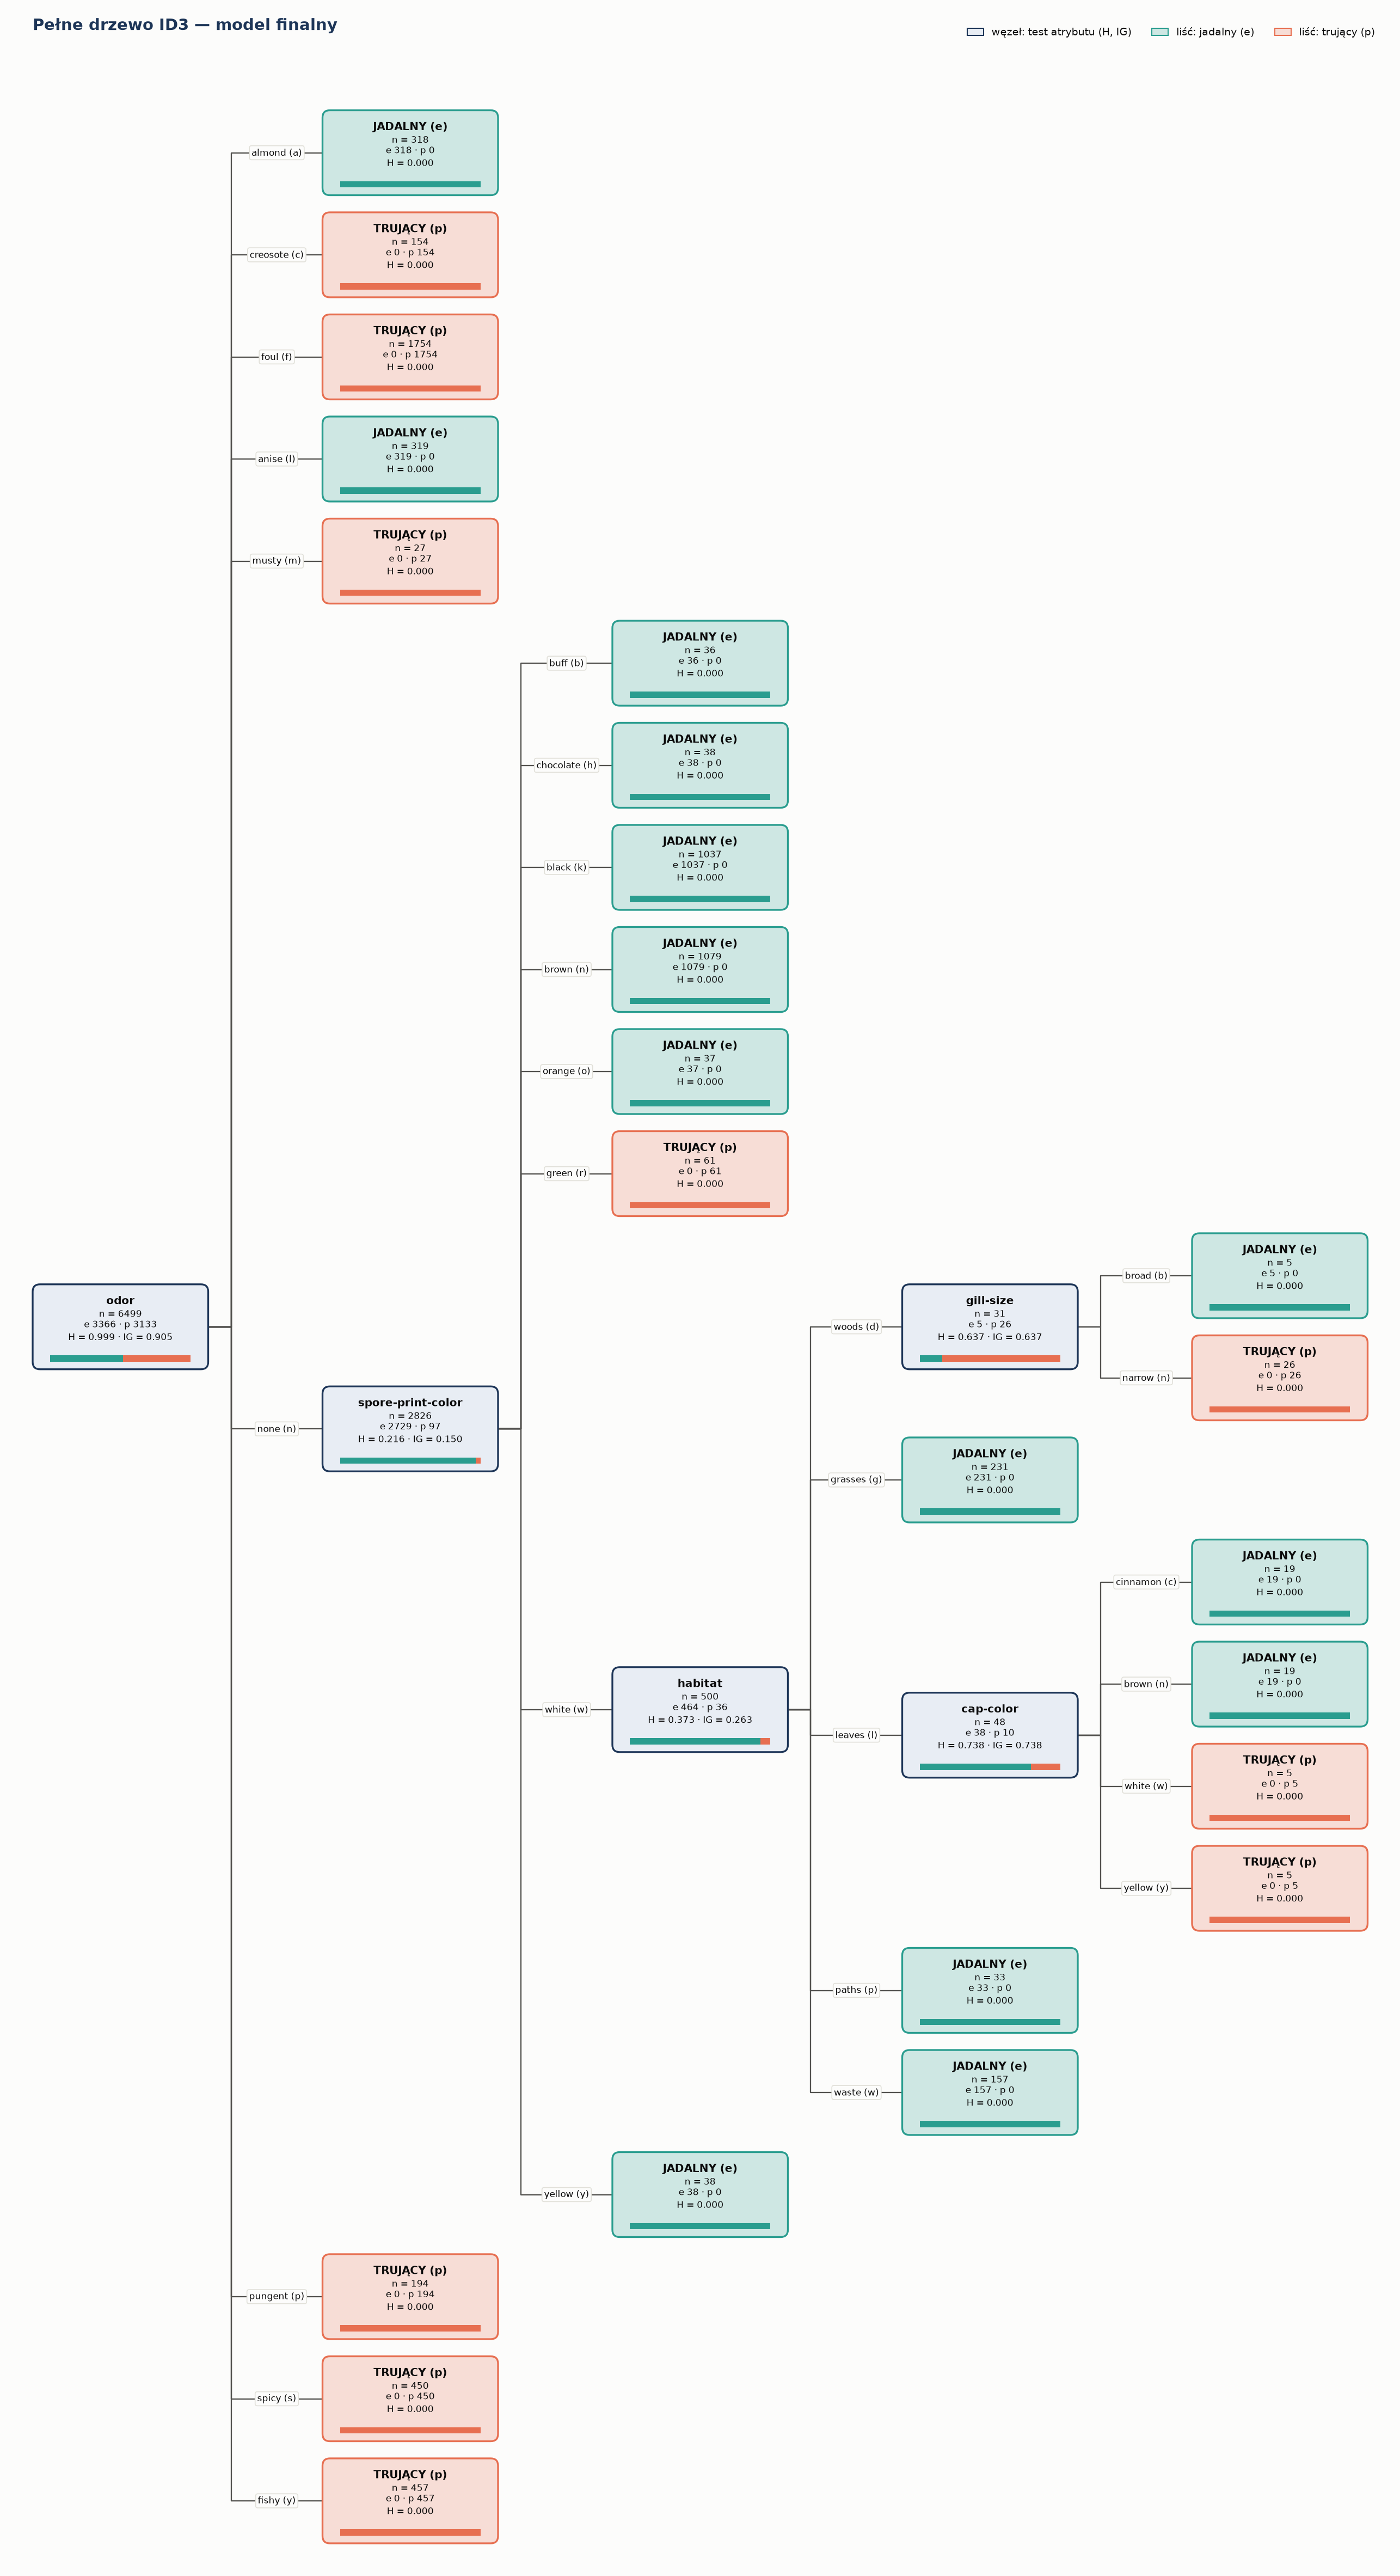

In [42]:
rendered = render_tree(final_model, FIG_DIR / "final_tree", title="Pełne drzewo ID3 — model finalny")
shutil.copy2(rendered["dot"], MODEL_DIR / "final_tree.dot")
print(f"Renderer: {rendered['backend']}  ·  pliki: {', '.join(p.name for p in rendered['files'])}  ·  "
      f"DOT: {(MODEL_DIR / 'final_tree.dot').relative_to(PROJECT_ROOT)}")
display(Image(filename=str(FIG_DIR / "final_tree.png"), width=820))

### Widok tekstowy (pomocniczy)
Wydruk ASCII służy szybkiemu podglądowi w konsoli. Nie zastępuje diagramu powyżej.

In [43]:
print(export_text(final_model, value_formatter=expand_value))

[odor]  n=6499  e=3366, p=3133
├── odor = almond (a) -> e  (n=318; e=318, p=0)
├── odor = creosote (c) -> p  (n=154; e=0, p=154)
├── odor = foul (f) -> p  (n=1754; e=0, p=1754)
├── odor = anise (l) -> e  (n=319; e=319, p=0)
├── odor = musty (m) -> p  (n=27; e=0, p=27)
├── odor = none (n) -> [spore-print-color]  (n=2826; e=2729, p=97)
│   ├── spore-print-color = buff (b) -> e  (n=36; e=36, p=0)
│   ├── spore-print-color = chocolate (h) -> e  (n=38; e=38, p=0)
│   ├── spore-print-color = black (k) -> e  (n=1037; e=1037, p=0)
│   ├── spore-print-color = brown (n) -> e  (n=1079; e=1079, p=0)
│   ├── spore-print-color = orange (o) -> e  (n=37; e=37, p=0)
│   ├── spore-print-color = green (r) -> p  (n=61; e=0, p=61)
│   ├── spore-print-color = white (w) -> [habitat]  (n=500; e=464, p=36)
│   │   ├── habitat = woods (d) -> [gill-size]  (n=31; e=5, p=26)
│   │   │   ├── gill-size = broad (b) -> e  (n=5; e=5, p=0)
│   │   │   └── gill-size = narrow (n) -> p  (n=26; e=0, p=26)
│   │   ├── habita

## 8.1. Biblioteki generujące grafikę drzew decyzyjnych

| Biblioteka | Język | Jak rysuje | Czy narysuje nasze drzewo ID3 (wielogałęziowe)? | Ograniczenia |
|---|---|---|---|---|
| **Graphviz** (`dot`) + `python-graphviz` / `PyGraphviz` | C (program), interfejsy Python/R | automatyczny układ grafu z opisu DOT → SVG/PNG/PDF | **tak**: eksportujemy DOT (`tree_to_dot`) | wymaga systemowego programu `dot` |
| **Matplotlib**, własny renderer (`plot_tree`) | Python | prostokąty, kolory klas, opisane krawędzie; własny układ drzewa | **tak**: fallback bez zależności systemowych | układ trzeba zaprogramować samodzielnie |
| **NetworkX + Matplotlib** | Python | graf węzłów i krawędzi | tak, po przepisaniu drzewa na graf | do hierarchii potrzebny `graphviz_layout` (pygraphviz/pydot) lub własne pozycje |
| **Plotly** (`treemap`, `sunburst`, `icicle`) | Python/JS | interaktywne wykresy hierarchii w HTML | częściowo: hierarchia liczności, a nie klasyczny schemat węzłów | eksport statyczny wymaga dodatku `kaleido` |
| **dtreeviz** | Python | bogate wizualizacje z rozkładami w węzłach | nie bezpośrednio: obsługuje drzewa scikit-learn, XGBoost, LightGBM, Spark | własne drzewo wymaga adaptera |
| **scikit-learn** `plot_tree` / `export_graphviz` | Python | rysunek drzewa CART | **nie**: tylko obiekty `DecisionTreeClassifier` (drzewa binarne) | nie obsługuje drzew wielogałęziowych |
| R: `rpart.plot`, `partykit`, `DiagrammeR` | R | wykresy drzew `rpart`/`party`; diagramy Graphviz | `DiagrammeR`: tak (DOT); pozostałe: tylko własne obiekty | związane z pakietami modelującymi R |

W projekcie: **DOT/Graphviz** jako format wymiany (`final_tree.dot`) i renderer, gdy jest dostępny, oraz **własny
renderer matplotlib** jako fallback i do widoków prezentacyjnych (grupowanie liści, wyróżnianie ścieżki predykcji).

<a id="rozdzial-09"></a>
# 09. Ocena modelu na zbiorze testowym

Konfiguracja, preprocessing i drzewo są już ustalone. Teraz **jeden raz** otwieramy sejf ze zbiorem testowym,
transformujemy go preprocesorem dopasowanym na train+val i oceniamy model. Po tym kroku nie wolno już niczego
stroić. Ponowne `unlock()` zgłosiłoby wyjątek.

,typ dostępu,cel
0,audyt danych (bez modelu),audyt duplikatów: identyczne wektory cech między podzbiorami
1,jednorazowa ocena modelu,jednorazowa ocena modelu finalnego C08


,precision,recall,F1,support
klasa,,,,
e,1.0,1.0,1.0,842
p,1.0,1.0,1.0,783
średnia makro,1.0,1.0,1.0,1625
średnia ważona,1.0,1.0,1.0,1625


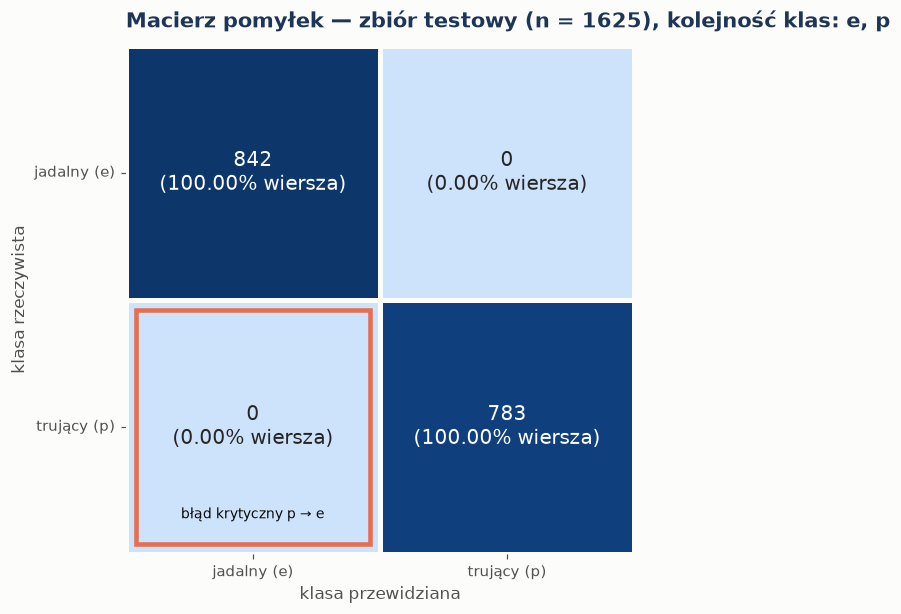

In [44]:
X_test, y_test = test_vault.unlock("jednorazowa ocena modelu finalnego " + best_config.config_id)
display(test_vault.log_frame())
X_test_ready = final_pre.transform(X_test)
test_pred = final_model.predict(X_test_ready)
test_details = final_model.predict_details(X_test_ready)
assert (test_details["prediction"].to_numpy() == test_pred).all()   # predykcje i ścieżki z tego samego modelu
test_metrics = classification_metrics(y_test, test_pred)
cm = confusion_matrix_frame(y_test, test_pred, labels=CLASS_ORDER)
display(classification_report_frame(y_test, test_pred).round(4))
show(plot_confusion_matrix(cm, f"Macierz pomyłek — zbiór testowy (n = {len(y_test)}), kolejność klas: e, p"),
     "09_confusion_matrix")
predictions = prediction_table(y_test, test_pred, index=X_test.index).join(test_details[["final_node_id",
                                                                                         "path_length"]])
predictions.to_csv(OUTPUT_DIR / "test_predictions.csv", index_label="row_index")
note(test_n=test_metrics["n"], test_acc=test_metrics["accuracy"], test_macro_f1=test_metrics["macro_f1"],
     test_weighted_f1=test_metrics["weighted_f1"], test_errors=test_metrics["n_errors"],
     test_p_to_e=test_metrics["p_to_e"], test_e_to_p=test_metrics["e_to_p"],
     test_p_to_e_rate=test_metrics["p_to_e_rate_of_p"], test_recall_p=test_metrics["recall_p"],
     test_precision_p=test_metrics["precision_p"], test_recall_e=test_metrics["recall_e"],
     test_fallbacks=int(test_details["used_fallback"].sum()),
     cm_ee=int(cm.loc["e", "e"]), cm_ep=int(cm.loc["e", "p"]), cm_pe=int(cm.loc["p", "e"]), cm_pp=int(cm.loc["p", "p"]))

**Wyniki na odłożonym zbiorze testowym** (1625 obserwacji):

| Miara | Wartość |
|---|---|
| accuracy | 1.0000 |
| macro-F1 / weighted-F1 | 1.0000 / 1.0000 |
| precision / recall klasy `p` | 1.0000 / 1.0000 |
| recall klasy `e` | 1.0000 |
| liczba błędów (łącznie) | 0 |
| błędy krytyczne `p → e` (udział wśród trujących) | 0 (0.00%) |
| błędy `e → p` | 0 |
| predykcje z fallbackiem (nieznana kategoria) | 0 |

**Macierz pomyłek** (wiersze: klasa rzeczywista, kolumny: przewidziana, kolejność `e`, `p`):
`e → e` = 842, `e → p` = 0, `p → e` = 0, `p → p` = 783.

**Interpretacja.** Model sklasyfikował poprawnie wszystkie 1625 obserwacji testowych. Liczba błędów wynosi
0, w tym 0 krytycznych `p → e`. Wynik potwierdza ocenę walidacyjną i jest zgodny z naturą
danych: etykiety w Mushroom wynikają z deterministycznych reguł przewodnika, a pełne drzewo ID3 te reguły odtwarza.
Wynik 100% nie świadczy tu o przecieku. Sprawdziliśmy to wprost:

- podzbiory są rozłączne (4.3);
- test nie zawiera wektorów cech obecnych w danych uczących (4.5);
- preprocessing dopasowano bez zbioru testowego;
- sejf otwarto dokładnie raz (log powyżej).

Żadna predykcja nie wymagała fallbacku dla nieznanej kategorii (liczba takich przypadków: 0).

## 9.1. Analiza błędów `p → e` i strefy ryzyka
Na teście nie ma błędnych klasyfikacji (liczba: 0), więc nie ma czego analizować. Nie tworzymy
sztucznych błędów. Wskazujemy natomiast, gdzie model jest najmniej pewny: przykłady trafiające do liści, które
w treningu oparto na bardzo małej liczbie obserwacji. Tam w pierwszej kolejności pojawiłyby się pomyłki
na nowych danych.

In [45]:
leaf_support = {node.node_id: node.n_samples for node in final_model.iter_nodes() if node.is_leaf}
risk = (predictions.assign(n_liścia=predictions["final_node_id"].map(leaf_support))
        .groupby("n_liścia").agg(przykłady_testowe=("predykcja", "size"),
                                 trujące=("klasa rzeczywista", lambda s: int((s == "p").sum())))
        .sort_index().head(6))
display(risk)
errors = predictions[predictions["wynik"] != "poprawna"]
print("Błędne klasyfikacje na teście:", len(errors))
note(risk_small_leaf_tests=int(risk.loc[risk.index <= 10, "przykłady_testowe"].sum()),
     min_leaf_support=int(min(leaf_support.values())))

,przykłady_testowe,trujące
n_liścia,,
5,9,6
19,10,0
26,6,6
27,9,9
33,7,0
36,12,0


Błędne klasyfikacje na teście: 0


**Interpretacja.** Najmniejsze liście mają w treningu tylko 5 obserwacji. Liczba grzybów
testowych w liściach opartych na ≤ 10 przykładach: 9. Te decyzje (np. `cap-color = white` przy
siedlisku `leaves`) mają najsłabsze pokrycie w danych i to tam w pierwszej kolejności należałoby się spodziewać
błędów na nowych danych spoza przewodnika.

## 9.2. Ścieżki predykcji dla rzeczywistych przykładów testowych
Wybieramy deterministycznie 5 przykładów: najpierw ewentualne błędy, potem po jednym przykładzie z każdej
głębokości ścieżki, a na koniec najgłębsze inne liście. Każda predykcja ma pełne uzasadnienie
(`explain_prediction`) z rozwiniętymi nazwami cech i kategorii.

In [46]:
chosen = list(errors.index)
for depth in sorted(test_details["path_length"].unique()):
    candidates = test_details.index[(test_details["path_length"] == depth) & ~test_details.index.isin(chosen)]
    chosen.append(candidates[0])
extra = (test_details.drop(index=chosen).sort_values(["path_length", "final_node_id"], ascending=[False, True])
         .drop_duplicates("final_node_id"))
chosen = (chosen + [i for i in extra.index if test_details.loc[i, "final_node_id"] not in
                    set(test_details.loc[chosen, "final_node_id"])])[:5]
for i, idx in enumerate(chosen, start=1):
    explanation = final_model.explain_prediction(X_test_ready.loc[idx])
    verdict = "poprawna" if explanation.prediction == y_test.loc[idx] else "BŁĘDNA"
    print(f"Przykład {i} — rekord #{idx}: klasa rzeczywista {describe_class(y_test.loc[idx])}, "
          f"predykcja {describe_class(explanation.prediction)} ({verdict})")
    print(explanation.to_text(value_formatter=expand_value), end="\n\n")
deepest = max(chosen, key=lambda i: test_details.loc[i, "path_length"])
path_ids = [s.node_id for s in final_model.explain_prediction(X_test_ready.loc[deepest]).steps]
path_ids.append(int(test_details.loc[deepest, "final_node_id"]))
note(n_examples=len(chosen), deepest_example=int(deepest), deepest_length=int(test_details.loc[deepest, "path_length"]))

Przykład 1 — rekord #2: klasa rzeczywista jadalny (e), predykcja jadalny (e) (poprawna)
1. węzeł #0 (n=6499, e=3366, p=3133, H=0.999) testuje 'odor' -> anise (l)
=> liść #4 (n=319, e=319, p=0): predykcja e

Przykład 2 — rekord #15: klasa rzeczywista jadalny (e), predykcja jadalny (e) (poprawna)
1. węzeł #0 (n=6499, e=3366, p=3133, H=0.999) testuje 'odor' -> none (n)
2. węzeł #6 (n=2826, e=2729, p=97, H=0.216) testuje 'spore-print-color' -> brown (n)
=> liść #10 (n=1079, e=1079, p=0): predykcja e

Przykład 3 — rekord #4291: klasa rzeczywista jadalny (e), predykcja jadalny (e) (poprawna)
1. węzeł #0 (n=6499, e=3366, p=3133, H=0.999) testuje 'odor' -> none (n)
2. węzeł #6 (n=2826, e=2729, p=97, H=0.216) testuje 'spore-print-color' -> white (w)
3. węzeł #13 (n=500, e=464, p=36, H=0.373) testuje 'habitat' -> waste (w)
=> liść #24 (n=157, e=157, p=0): predykcja e

Przykład 4 — rekord #4364: klasa rzeczywista trujący (p), predykcja trujący (p) (poprawna)
1. węzeł #0 (n=6499, e=3366, p=3133, H

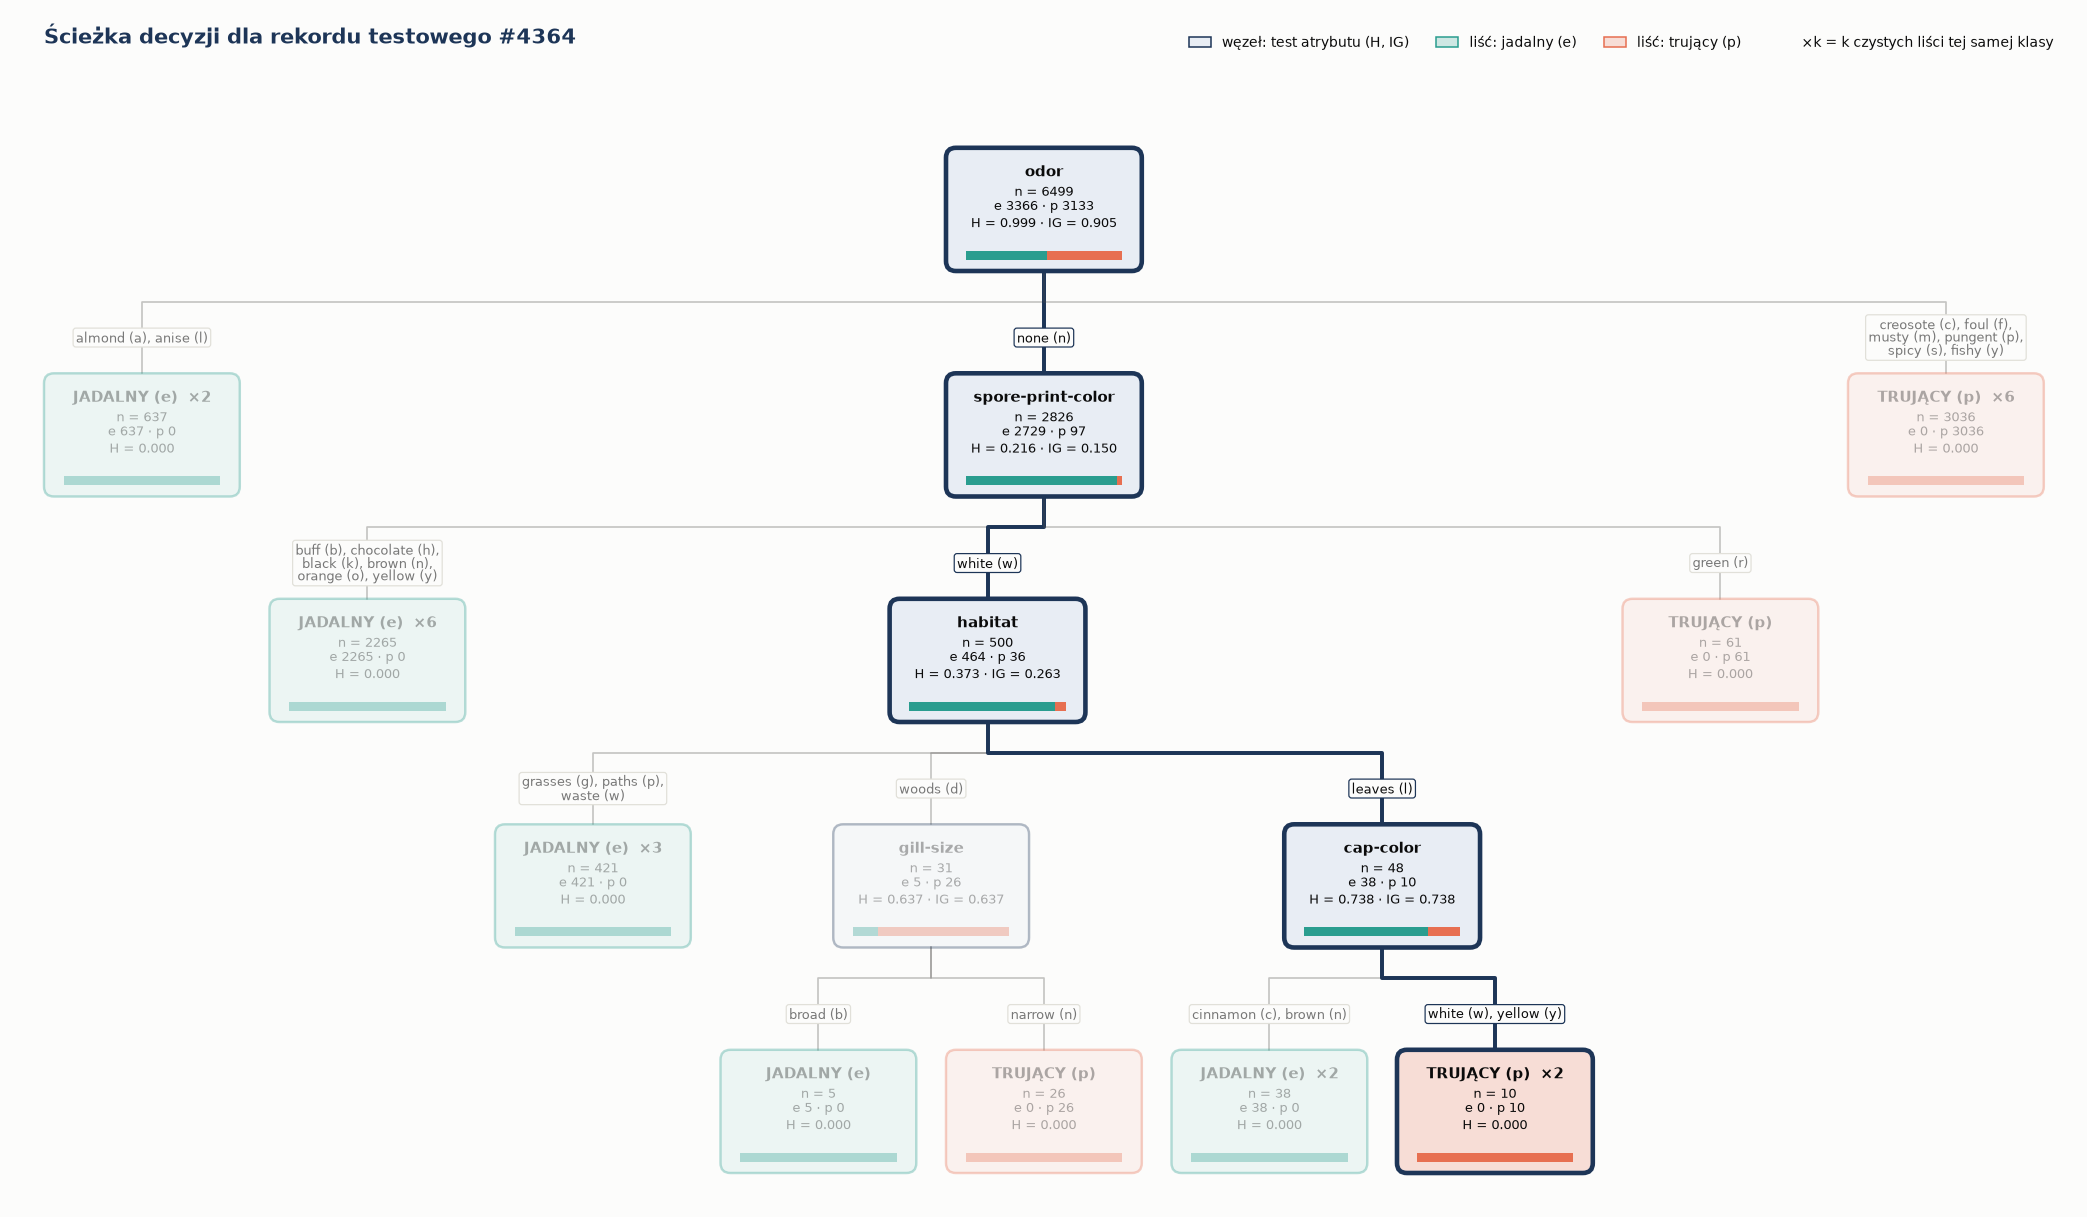

In [47]:
show(plot_tree(final_model, group_pure_leaves=True, highlight_node_ids=path_ids,
               title=f"Ścieżka decyzji dla rekordu testowego #{deepest}"), "09_prediction_path")

**Interpretacja.** Pięć ścieżek pokazuje, jak drzewo „rozumuje”. Grzyb z charakterystycznym zapachem jest
rozstrzygany jednym testem. Grzyb bezwonny wymaga sprawdzenia wysypu zarodników, a przy białym wysypie także
siedliska i jeszcze jednej cechy. Najdłuższa ścieżka (rekord #4364, 4 testy)
przechodzi przez wyróżnione węzły na schemacie. Każdy krok podaje liczność i rozkład klas węzła, więc widać,
na ilu przykładach z treningu opiera się decyzja.

> ⚠️ **Ostrzeżenie.** Te predykcje to ilustracja działania algorytmu na danych edukacyjnych. Model zna tylko
> 23 gatunki opisane w jednym przewodniku i cechy zakodowane przez człowieka. Nie nadaje się do oceny jadalności
> prawdziwych grzybów.

<a id="rozdzial-10"></a>
# 10. Warsztat dla grupy: „Delivery Decision — czy przesyłka dotrze na czas?”

**Zadanie:** na małym, syntetycznym zbiorze 28 przesyłek uczestnicy samodzielnie wykonują pełny cykl ID3:

1. wykrywają i uzupełniają braki danych;
2. liczą entropię i przyrost informacji, a na tej podstawie wybierają korzeń;
3. budują gotowym mini-ID3 drzewo i uzasadniają jego predykcję dla nowej przesyłki.

Dane są **inne niż Mushroom**: 4 nominalne cechy (`distance`, `weather`, `workload`, `shipping`), etykieta
`on_time` / `delayed`, 3 kontrolowane braki w dwóch kolumnach.

| Minuty | Uczestnik wykonuje | Weryfikowalny wynik |
|---|---|---|
| 0–4 | otwiera notebook w Colab, czyta opis i dane | wczytana tabela i etykieta celu |
| 4–9 | **TODO 1:** wykrywa i uzupełnia braki dominantą | tabela „braki przed / po” |
| 9–16 | **TODO 2–3:** entropia, IG, wybór korzenia; mini-ID3 | ranking IG + mini-drzewo |
| 16–20 | **TODO 4:** predykcja nowej przesyłki i uzasadnienie ścieżką | predykcja + 1–2 zdania |

**Jak pracować:**

- Na zajęciach notebook otwiera się w **Google Colab**: *Plik → Zapisz kopię na Dysku*, potem *Uruchom wszystko*.
  Działa też lokalnie w JupyterLab.
- Notebook jest samowystarczalny: dane są wbudowane, nie trzeba montować cudzego Dysku ani pobierać repozytorium.
- Każde TODO ma automatyczną kontrolę z podpowiedzią. Niedokończone zadanie nie blokuje kolejnych kroków.
- **W domu, bez limitu czasu:** te same materiały, a do tego opcjonalny bonus (porównanie strategii braków
  i wpływ na wybór korzenia). Bonus nie jest potrzebny do zaliczenia scenariusza podstawowego.

**Dostęp tylko dla grupy:** materiały uczestnika (`submission/ID3_Group_Workshop_Students.zip`: notebook, CSV,
README) publikujemy w folderze Google Drive z dostępem **„Ograniczony”**, udostępnionym wyłącznie adresom e-mail
osób z grupy. Alternatywą jest prywatne repozytorium GitHub z zaproszonymi członkami grupy. Instrukcja krok po
kroku: `group_exercise/README.md`. **Materiały nie zostały jeszcze opublikowane.** Link należy wpisać poniżej
po utworzeniu folderu. Rozwiązanie i klucz odpowiedzi są w osobnej, prywatnej paczce prowadzącego warsztat
i nie trafiają do grupy.

In [48]:
WORKSHOP_LINK = None   # ← po publikacji: link do folderu Google Drive / repozytorium dostępnego tylko dla grupy
WORKSHOP_CSV = '''
distance,weather,workload,shipping,on_time
medium,rain,medium,express,on_time
medium,clear,high,express,delayed
long,clear,medium,express,on_time
medium,clear,low,standard,on_time
long,snow,low,standard,delayed
medium,clear,medium,express,on_time
long,rain,medium,standard,delayed
medium,snow,medium,standard,delayed
short,snow,high,standard,delayed
long,clear,medium,standard,on_time
medium,,low,express,on_time
long,clear,low,express,on_time
short,clear,high,standard,delayed
short,clear,low,standard,on_time
long,snow,high,express,delayed
short,,medium,standard,on_time
short,rain,high,standard,on_time
long,rain,low,express,on_time
medium,rain,high,standard,delayed
short,snow,,standard,delayed
long,rain,low,standard,delayed
long,clear,high,standard,delayed
long,snow,medium,express,delayed
short,snow,medium,express,delayed
medium,snow,high,express,delayed
medium,rain,low,standard,delayed
short,rain,high,express,on_time
short,clear,medium,express,on_time
'''  # kopia group_exercise/delivery_data.csv wstawiona przez scripts/build_notebook.py
delivery = pd.read_csv(io.StringIO(WORKSHOP_CSV.strip()))
print("Link dla grupy:", WORKSHOP_LINK or "jeszcze nieopublikowany — patrz group_exercise/README.md")
print(f"Dane warsztatu: {delivery.shape[0]} przesyłek × {delivery.shape[1]} kolumn; braki: "
      f"{ {c: int(n) for c, n in delivery.isna().sum().items() if n} }")
display(delivery.head(8))

Link dla grupy: jeszcze nieopublikowany — patrz group_exercise/README.md
Dane warsztatu: 28 przesyłek × 5 kolumn; braki: {'weather': 2, 'workload': 1}


,distance,weather,workload,shipping,on_time
0,medium,rain,medium,express,on_time
1,medium,clear,high,express,delayed
2,long,clear,medium,express,on_time
3,medium,clear,low,standard,on_time
4,long,snow,low,standard,delayed
5,medium,clear,medium,express,on_time
6,long,rain,medium,standard,delayed
7,medium,snow,medium,standard,delayed


Powyżej jest tylko podgląd danych, bez obliczeń. Wyniki zadania (ranking IG, korzeń, predykcja) uczestnicy
uzyskują sami w notebooku warsztatowym.

<a id="rozdzial-11"></a>
# 11. Podsumowanie

### Wnioski
1. **Własny ID3** (entropia, IG, podziały wielogałęziowe, deterministyczne remisy, fallback dla nieznanych
   kategorii, wyjaśnienia ścieżek) spełnia testy matematyczne i zachowuje się zgodnie z pseudokodem. Na Mushroom
   wybiera w korzeniu `odor` (IG = 0.903 bita na zbiorze uczącym).
2. **Dane są czyste:** nie ma duplikatów, wartości spoza słownika ani sprzecznych etykiet. Wymagają tylko obsługi
   2480 braków w `stalk-root` (nielosowych: 17.1% u jadalnych wobec
   44.9% u trujących) i usunięcia stałej cechy `veil-type`. Balansowanie nie było potrzebne.
3. **Strojenie:** jakość zależy wyłącznie od głębokości. `max_depth=2` daje 99.45% i 9
   błędów `p → e` na walidacji, a od głębokości 4 jest 100%. Trzy strategie braków budują
   identyczne drzewa, bo `stalk-root` nigdzie nie wygrywa. W jednym węźle remisuje jednak 7 atrybutów
   i o kształcie drzewa przesądza reguła remisów.
4. **Model finalny** `C08` (29 węzłów, 24 liście, głębokość 4,
   5 atrybutów) osiągnął na jednokrotnie użytym zbiorze testowym accuracy 1.0000, macro-F1
   1.0000 i 0 błędów krytycznych `p → e`.

### Ograniczenia
- Mushroom jest zbiorem **syntetycznym i deterministycznym**: opisuje 23 gatunki z jednego przewodnika, a etykiety
  wynikają z reguł. Wysoka trafność nie przenosi się na realne okazy, wątpliwe kategorie cech ani nowe gatunki.
- Klasa `p` łączy grzyby trujące i „o nieznanej jadalności”, więc model nie rozróżnia stopnia zagrożenia.
- Część liści opiera się na kilku obserwacjach (minimum 5). Te reguły są najmniej pewne.
- Pojedynczy podział 60/20/20 nie mierzy zmienności wyników. Przy wynikach na sufit nie zmieniłoby to decyzji,
  ale na trudniejszych danych warto użyć walidacji krzyżowej na części train+val.

### Reprodukowalność
- Ziarno `random_state=42` (podział), deterministyczny ID3 (sortowanie kategorii, alfabetyczne remisy), stałe
  parametry renderowania wykresów.
- Wyniki 36 modeli mają stały **odcisk SHA-256** (kolumny deterministyczne, bez czasu uczenia), a drzewo ma stałą
  sygnaturę struktury.
- Artefakty: `experiment_results.csv`, `split_indices.csv`, `test_predictions.csv`, `final_model/final_tree.json`
  i `.dot`, `final_config.json`, `run_summary.json`, wykresy w `outputs/figures/`.
- Komendy kontroli: `python -m pytest -q`, `python scripts/build_notebook.py`, `python scripts/validate_notebook.py`,
  `python scripts/package_submission.py`. Raport: `outputs/QA_REPORT.md`.

In [49]:
run_summary = {
    "data_sha256": file_sha256(DATA_ZIP), "split_random_state": split.random_state,
    "experiment_fingerprint": results_fingerprint(results), "selected_configuration": best_config.config_id,
    "final_tree_signature": final_model.structure_signature(),
    "test_metrics": {k: test_metrics[k] for k in ("accuracy", "macro_f1", "p_to_e", "e_to_p", "n")},
    "graphviz_backend": rendered["backend"], "environment": ENVIRONMENT,
}
(OUTPUT_DIR / "run_summary.json").write_text(json.dumps(run_summary, indent=2, ensure_ascii=False), encoding="utf-8")
display(pd.Series({k: v for k, v in run_summary.items() if k != "environment"}, name="wartość").to_frame())

,wartość
data_sha256,face32f32647e0d939f6233f36dd30dd5d619ae9f3f9b8e10bea4ac7e1f60b1a
split_random_state,42
experiment_fingerprint,af8797b347a5c114f3329cddfe18a88f85b72509c8034e74c5732ab6657a0336
selected_configuration,C08
final_tree_signature,096f6b3d00a32b15
test_metrics,"{'accuracy': 1.0, 'macro_f1': 1.0, 'p_to_e': 0, 'e_to_p': 0, 'n': 1625}"
graphviz_backend,matplotlib


### Bibliografia i źródła
1. Schlimmer, J. (1987). *Mushroom* [Dataset]. UCI Machine Learning Repository.
   https://archive.ics.uci.edu/dataset/73/mushroom, DOI: https://doi.org/10.24432/C5959T
2. Quinlan, J. R. (1986). Induction of Decision Trees. *Machine Learning*, 1, 81–106.
   https://doi.org/10.1007/BF00116251
3. Quinlan, J. R. (1993). *C4.5: Programs for Machine Learning*. Morgan Kaufmann.
4. Hunt, E. B., Marin, J., Stone, P. J. (1966). *Experiments in Induction*. Academic Press.
5. Breiman, L., Friedman, J., Olshen, R., Stone, C. (1984). *Classification and Regression Trees*. Wadsworth.
6. Breiman, L. (2001). Random Forests. *Machine Learning*, 45, 5–32. https://doi.org/10.1023/A:1010933404324
7. Hyafil, L., Rivest, R. L. (1976). Constructing optimal binary decision trees is NP-complete.
   *Information Processing Letters*, 5(1), 15–17.
8. Fayyad, U., Irani, K. (1993). Multi-interval discretization of continuous-valued attributes for classification
   learning. *IJCAI-93*, 1022–1027.
9. WEKA, `weka.classifiers.trees.Id3`:
   https://weka.sourceforge.io/doc.packages/simpleEducationalLearningSchemes/weka/classifiers/trees/Id3.html
10. scikit-learn: Decision Trees (1.10.6 *Tree algorithms*): https://scikit-learn.org/stable/modules/tree.html
11. JupyterLab: eksport notebooków: https://jupyterlab.readthedocs.io/en/stable/user/export.html
12. Google Colab: praca z plikami zewnętrznymi: https://colab.research.google.com/notebooks/io.ipynb

### Licencja danych
Zbiór *Mushroom* jest udostępniany przez UCI Machine Learning Repository na licencji
**Creative Commons Attribution 4.0 International (CC BY 4.0)**. Wykorzystanie wymaga podania źródła. Cytowanie:
*Mushroom [Dataset]. (1981). UCI Machine Learning Repository. https://doi.org/10.24432/C5959T*. Archiwum
`data/mushroom.zip` jest niezmienioną kopią pliku pobranego z UCI.

### Kontrola spójności narracji
Ostatnia komórka zestawia każdą liczbę cytowaną w komentarzach tego notebooka (wstawioną przez generator
z rzeczywistego uruchomienia) z wartością policzoną teraz. Jakakolwiek różnica przerywa wykonanie notebooka.

In [50]:
NARRATIVE_FACTS = {
 "H_class|.4f": "0.9991",
 "H_train|.4f": "0.9991",
 "H_trval|.4f": "0.9991",
 "cm_ee|": "842",
 "cm_ep|": "0",
 "cm_pe|": "0",
 "cm_pp|": "783",
 "constant_features|": "veil-type",
 "d1_acc|.2%": "98.65%",
 "d1_p_to_e|": "22",
 "d1_train_acc|.2%": "98.46%",
 "d2_acc|.2%": "99.45%",
 "d2_p_to_e|": "9",
 "d3_acc|.2%": "99.82%",
 "d3_e_to_p|": "2",
 "d3_p_to_e|": "1",
 "deepest_example|": "4364",
 "deepest_length|": "4",
 "dup_max|": "0",
 "ex_best|": "odor",
 "ex_gr_bruises|.3f": "0.294",
 "ex_gr_odor|.3f": "0.578",
 "ex_ig_bruises|.4f": "0.1909",
 "ex_ig_gill|.4f": "0.0207",
 "ex_ig_odor|.4f": "1.0000",
 "ex_odor_values|": "4",
 "final_depth|": "4",
 "final_impure_leaves|": "0",
 "final_leaves|": "24",
 "final_n_used|": "5",
 "final_nodes|": "29",
 "final_n|": "6499",
 "final_same_as_validated|": "True",
 "final_used|": "odor, spore-print-color, habitat, gill-size, cap-color",
 "first_perfect_depth|": "4",
 "full_depth|": "4",
 "gill_size_values|": "2",
 "gr_first|": "odor",
 "gr_gill_size_ig_rank|": "9",
 "gr_second_value|.3f": "0.251",
 "gr_second|": "gill-size",
 "ig_odor_train|.3f": "0.903",
 "ig_odor_train|.4f": "0.9033",
 "ig_second_feature|": "spore-print-color",
 "ig_second|.3f": "0.503",
 "ig_third_feature|": "gill-color",
 "ig_third|.3f": "0.430",
 "ig_veil|.1f": "0.0",
 "imbalance_ratio|.3f": "1.075",
 "imp_first_value|.1%": "90.6%",
 "imp_first|": "odor",
 "imp_second_value|.1%": "6.5%",
 "imp_second|": "spore-print-color",
 "importance_bits_total|.4f": "0.9991",
 "max_cardinality_feature|": "gill-color",
 "max_cardinality|": "12",
 "mi_odor|.3f": "0.906",
 "min_leaf_support|": "5",
 "miss_chi2|.1f": "740.9",
 "miss_e_n|": "720",
 "miss_e_share|.1%": "17.1%",
 "miss_e_share|.2%": "17.11%",
 "miss_p_n|": "1760",
 "miss_p_share|.1%": "44.9%",
 "miss_p_share|.2%": "44.94%",
 "miss_ratio|.2f": "2.63",
 "miss_v|.3f": "0.302",
 "missing_share|.2%": "30.53%",
 "n_columns|": "23",
 "n_conflicts|": "0",
 "n_dup_rows|": "0",
 "n_dup_vectors|": "0",
 "n_e|": "4208",
 "n_features_drop|": "20",
 "n_features_model|": "21",
 "n_features_unobserved|": "5",
 "n_inline_checks|": "12",
 "n_missing_total|": "2480",
 "n_missing_train|": "1455",
 "n_odor_branches|": "9",
 "n_odor_pure|": "8",
 "n_out_of_domain|": "0",
 "n_perfect|": "24",
 "n_p|": "3916",
 "n_rows|": "8124",
 "n_shallow|": "12",
 "n_signatures|": "2",
 "n_test|": "1625",
 "n_train|": "4874",
 "n_unseen_val|": "0",
 "n_val|": "1625",
 "names_ok|": "22",
 "odor_categories|": "9",
 "odor_none_H|.3f": "0.222",
 "odor_none_n_full|": "3528",
 "odor_none_n|": "2104",
 "odor_none_p_full|": "120",
 "odor_none_p|": "75",
 "odor_none_weight|.1%": "43.2%",
 "odor_pure_categories|": "8",
 "odor_remainder|.4f": "0.0958",
 "p_poisonous|.2%": "48.20%",
 "p_share_test|.2%": "48.18%",
 "p_share_train|.2%": "48.22%",
 "p_share_val|.2%": "48.18%",
 "perfect_depth|": "4",
 "perfect_nodes|": "29",
 "risk_small_leaf_tests|": "9",
 "selected_config|": "C08",
 "selected_leaves|": "24",
 "selected_max_depth|": "4",
 "selected_min_ig|": "0.01",
 "selected_min_split|": "20",
 "selected_strategy|": "missing_category",
 "shallow_acc|.2%": "99.45%",
 "shallow_leaves|": "16",
 "shallow_p_to_e|": "9",
 "share_e|.2%": "51.80%",
 "share_p|.2%": "48.20%",
 "stalk_best_rank|": "6",
 "strategies_identical|": "True",
 "test_acc|.4f": "1.0000",
 "test_e_to_p|": "0",
 "test_errors|": "0",
 "test_fallbacks|": "0",
 "test_macro_f1|.4f": "1.0000",
 "test_n|": "1625",
 "test_p_to_e_rate|.2%": "0.00%",
 "test_p_to_e|": "0",
 "test_precision_p|.4f": "1.0000",
 "test_recall_e|.4f": "1.0000",
 "test_recall_p|.4f": "1.0000",
 "test_weighted_f1|.4f": "1.0000",
 "tie_count|": "7",
 "tie_features|": "gill-size, population, ring-number, ring-type, stalk-color-above-ring, stalk-root, stalk-surface-above-ring",
 "tie_gain|.4f": "0.5917",
 "tie_node_label|": "głęb. 3: habitat = woods (d)",
 "tie_node_n|": "21",
 "tie_winner|": "gill-size",
 "top_group_size|": "24",
 "top_group_trees|": "1",
 "top_pair_a|": "gill-attachment",
 "top_pair_b|": "stalk-color-above-ring",
 "top_pair_v|.2f": "0.98",
 "train_mode_label|": "bulbous (b)",
 "u_odor|.1%": "90.7%",
 "v_odor|.3f": "0.971",
 "v_spore|.3f": "0.753",
 "v_veil|.1f": "0.0"
}  # wygenerowane przez build_notebook.py
(OUTPUT_DIR / "narrative_facts.json").write_text(json.dumps(FACTS, indent=2, ensure_ascii=False, default=str),
                                                 encoding="utf-8")
if NARRATIVE_FACTS:
    rows = []
    for key, expected in NARRATIVE_FACTS.items():
        name, _, spec = key.partition("|")
        actual = format(FACTS[name], spec) if name in FACTS else "— (brak w tym uruchomieniu)"
        rows.append({"wartość": name, "format": spec or "—", "w tekście": expected, "obliczone teraz": actual,
                     "zgodne": actual == expected})
    consistency = pd.DataFrame(rows)
    print(f"Liczby w komentarzach zgodne z obliczeniami: {int(consistency['zgodne'].sum())} / {len(consistency)}")
    display(consistency[~consistency["zgodne"]] if not consistency["zgodne"].all() else consistency.sample(
        n=min(8, len(consistency)), random_state=0).sort_values("wartość"))
    assert consistency["zgodne"].all(), "Narracja niezgodna z wynikami — przebuduj notebook (build_notebook.py)."
else:
    print(f"Przebieg roboczy generatora: zapisano {len(FACTS)} wartości.")

Liczby w komentarzach zgodne z obliczeniami: 149 / 149


,wartość,format,w tekście,obliczone teraz,zgodne
7,constant_features,—,veil-type,veil-type,True
59,miss_e_n,—,720,720,True
80,n_odor_pure,—,8,8,True
95,odor_none_n,—,2104,2104,True
104,p_share_val,.2%,48.18%,48.18%,True
109,selected_leaves,—,24,24,True
133,tie_count,—,7,7,True
140,top_group_trees,—,1,1,True
